# ĐỒ ÁN MÁY HỌC – ỨNG DỤNG BAGGING HDBSCAN TRONG PHÂN CỤM DỮ LIỆU ĐA MẬT ĐỘ

Notebook này chứa **Chương 5 (Thiết kế và cài đặt chương trình)**, **Chương 6 (Dữ liệu, thực nghiệm và so sánh)** và **Chương 7 (Kết luận)**.
Mọi thuật toán lõi (HDBSCAN và Bagging cho phân cụm) được **tự cài đặt bằng lập trình hướng đối tượng**, bám sát lý thuyết ở Chương 3 (các bước 3.3.1 – 3.3.8) và Chương 4 (giả mã 4.1, các định nghĩa 4.1 – 4.8). Thư viện chỉ dùng để **đối chiếu, đánh giá và vẽ hình**.

**Thư viện đối chiếu:** dùng duy nhất gói **`hdbscan`** (McInnes); ô bên dưới cài gói nếu chưa có.
`HDBSCANLibraryAdapter` không tự thay nguồn thuật toán khi import thất bại.

**Quy ước tham số để đối chiếu công bằng:** bản tự viết hiện tính cả chính điểm trong `min_samples`;
gói `hdbscan` không tính chính điểm. Adapter giữ nguyên đầu vào của chương trình và truyền
`min_samples_hdbscan = min(min_samples_tu_cai, n) - 1`. Ví dụ `(MCS=3, MS_tự_cài=2)` đối chiếu `(MCS=3, MS_hdbscan=1)`.
Không thay công thức core distance của bản tự viết trong lần sửa này.

Khi hiệu chỉnh tham số làm `MS_tự_cài=1`, giá trị tương đương là 0: API công khai của gói không nhận 0,
nên adapter dùng riêng pipeline generic nội bộ **của chính gói hdbscan** cho trường hợp biên này (đã kiểm tra 0.8.44).
Các trường hợp `MS_tự_cài>=2` dùng API công khai `hdbscan.HDBSCAN(algorithm='generic')`.

`sklearn.metrics` và `sklearn.neighbors` vẫn phục vụ kiểm tra chỉ số/láng giềng; nguồn thuật toán HDBSCAN đối chiếu là gói `hdbscan`.
Tên và phiên bản gói được in trong notebook. Các bảng đối chiếu cũ cần được chạy lại sau khi đổi thư viện.

Nguồn quy ước: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.HDBSCAN.html (Notes);
pipeline gói: https://hdbscan.readthedocs.io/en/latest/_modules/hdbscan/hdbscan_.html .

**Dữ liệu thực nghiệm đã cập nhật:** `synthetic-stroke-hdbscan-data-v2.xlsx`,
do nhóm tự sinh (seed tạo dữ liệu 2027), gồm 2.985 dòng và 12 cột.
Đây là dữ liệu tổng hợp. Các lớp thuật toán, bộ điểm minh họa D1, seed thực nghiệm,
hai biến phân cụm, quy ước chuẩn hóa và lưới tham số được giữ nguyên.
Thực nghiệm chính dùng **toàn bộ dữ liệu tổng hợp sau khi loại trùng** (`N_SAMPLE = None` ở mục 6.3); đặt `N_SAMPLE` là một số nguyên nếu cần lấy mẫu con.
Các kết luận định lượng ở cuối notebook được tính lại từ đầu ra hiện tại.


## Chương 5. Thiết kế và cài đặt chương trình
### 5.1. Nguyên tắc cài đặt thủ công
* Mỗi bước lý thuyết có **một phương thức riêng**, tên phương thức ghi rõ mục lý thuyết tương ứng (ví dụ `compute_core_distances` ↔ 3.3.2).
* **Tự xây:** khoảng cách, core distance, mutual reachability, MST (Prim), single linkage bằng UnionFind, cây cô đọng, độ ổn định, EOM, gán nhãn; lấy mẫu bootstrap, ma trận S/T/C, đồ thị ngưỡng, thành phần liên thông; ARI, DBCV, so sánh mặt nạ nhiễu.
* **Dùng thư viện** chỉ để: đọc dữ liệu (pandas), vẽ hình (matplotlib), đối chiếu (HDBSCAN thư viện, scipy `linkage` / `minimum_spanning_tree`, sklearn `adjusted_rand_score`, `silhouette_score`).
* Ngôn ngữ vector hóa của NumPy được dùng bên trong các hàm để chạy nhanh; mỗi hàm vẫn thực hiện đúng phép tính của giả mã ở Chương 3 (riêng khoảng cách có thêm bản vòng lặp `use_loops=True` đúng giả mã 3.3.1 để kiểm tra).

### Cài đặt gói hdbscan cho phần đối chiếu
Ô sau cài `hdbscan==0.8.44` vào Python đang chạy notebook nếu chưa có; nếu đã cài thì chỉ in phiên bản.
Nếu bạn vừa cài/thay phiên bản trong một kernel đã import gói cũ, hãy Restart Kernel rồi Run All.


In [21]:
import importlib.util
import subprocess
import sys
from importlib.metadata import version

if importlib.util.find_spec("hdbscan") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "hdbscan==0.8.44"])

import hdbscan
HDBSCAN_LIBRARY_VERSION = version("hdbscan")
print("Đã sẵn sàng:", "hdbscan", HDBSCAN_LIBRARY_VERSION)
if HDBSCAN_LIBRARY_VERSION != "0.8.44":
    print("Bản chỉnh sửa đã kiểm tra với 0.8.44; hãy ghi lại phiên bản thực tế khi báo cáo.")


Đã sẵn sàng: hdbscan 0.8.44


In [22]:
import time, math, os, itertools, tracemalloc, warnings
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform, cdist
from scipy.sparse.csgraph import minimum_spanning_tree
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})

# Hằng số ký hiệu (khớp mục 4.3.3: ∅ = không được quan sát, −1 = nhiễu)
NOISE = -1
UNOBS = -2

### 5.3. Thiết kế các lớp

| Lớp | Vai trò |
|---|---|
| `Preprocessor` | Đọc, kiểm tra, chuẩn hóa z-score, dữ liệu trùng, IQR, tách dev/eval, PCA 2D |
| `UnionFind` | Quản lý các thành phần (dùng cho cây single linkage 3.3.5 và thành phần liên thông 4.5.2) |
| `HDBSCANScratch` | Thực hiện toàn bộ HDBSCAN theo 3.3.1 – 3.3.8 |
| `BootstrapSampler` | Sinh và lưu chỉ số mẫu (4.3.1) |
| `CoAssociationBuilder` | Xây S, T, C (4.4) |
| `ConsensusClusterer` | Tổng hợp cụm: đồ thị ngưỡng (4.5.1–4.5.3), average linkage và HDBSCAN trên 1−C (4.5.5) |
| `BaggedHDBSCANScratch` | Điều phối toàn bộ ensemble (giả mã 4.1) |
| `HDBSCANLibraryAdapter` | Chạy bản thư viện tương ứng |
| `ClusteringEvaluator` | Số cụm, nhiễu, Silhouette, DBCV, ARI, mặt nạ nhiễu, thời gian, bộ nhớ |
| `ExperimentRunner` | Quản lý thí nghiệm, bảng kết quả, độ ổn định |

### 5.4. Cài đặt HDBSCAN theo Chương 3
`UnionFind`, `HDBSCANScratch` (các phương thức `compute_*`, `build_*`, `condense_tree`, `select_clusters_eom`, `assign_labels` tương ứng 3.3.1 – 3.3.8) và `HDBSCANLibraryAdapter` chạy gói `hdbscan` để đối chiếu, với quy đổi MS đã nêu đầu notebook.

In [23]:
class UnionFind:
    """Cấu trúc Union-Find có tạo nút cha mới (kiểu cây phân cấp của scipy: lá 0..n-1, nút trong n..2n-2).
    Dùng cho: dựng cây single linkage (3.3.5) và tìm thành phần liên thông của đồ thị ngưỡng (4.5.2)."""

    def __init__(self, n_leaves):
        self.n = n_leaves
        total = 2 * n_leaves - 1
        self.parent = np.arange(total)
        self.size = np.zeros(total, dtype=np.int64)
        self.size[:n_leaves] = 1
        self.next_label = n_leaves

    def find(self, x):                       # TIM_GOC, có nén đường đi
        root = x
        while self.parent[root] != root:
            root = self.parent[root]
        while self.parent[x] != root:
            self.parent[x], x = root, self.parent[x]
        return root

    def get_size(self, root):                # LAY_KICH_THUOC
        return int(self.size[root])

    def union(self, ra, rb):                 # HOP_NHAT(goc_u, goc_v, nut_cha_moi)
        new = self.next_label
        self.parent[ra] = new
        self.parent[rb] = new
        self.size[new] = self.size[ra] + self.size[rb]
        self.next_label += 1
        return new

    def components(self, edges):
        """Thành phần liên thông của đồ thị có n đỉnh và danh sách cạnh `edges` (i, j)."""
        for i, j in edges:
            ri, rj = self.find(i), self.find(j)
            if ri != rj:
                self.union(ri, rj)
        roots = np.array([self.find(i) for i in range(self.n)])
        return roots

In [24]:
class HDBSCANScratch:
    """HDBSCAN tự cài đặt theo Chương 3.

    Quy ước NỘI BỘ của bản tự viết (adapter quy đổi khi đối chiếu gói hdbscan): core distance = khoảng cách tới láng giềng thứ `min_samples`
    **có tính chính điểm** (điểm thứ 1 là bản thân, khoảng cách 0); chọn cụm EOM; allow_single_cluster=False
    (nút gốc không bao giờ được chọn); khi hòa độ ổn định thì giữ cụm cha (như thư viện).
    Các thuộc tính trung gian được lưu lại để đối chiếu từng bước (mục 6.6)."""

    def __init__(self, min_cluster_size=5, min_samples=None, metric="euclidean", allow_single_cluster=False):
        self.min_cluster_size = int(min_cluster_size)
        self.min_samples = int(min_samples) if min_samples is not None else int(min_cluster_size)
        self.metric = metric
        self.allow_single_cluster = allow_single_cluster

    # ---------- 3.3.1 ----------
    @staticmethod
    def compute_distance_matrix(X, use_loops=False):
        """Ma trận khoảng cách Euclidean D (3.2.1, 3.3.1)."""
        X = np.asarray(X, dtype=float)
        n, d = X.shape
        if use_loops:                          # đúng giả mã 3.3.1 (chỉ dùng khi n nhỏ)
            D = np.zeros((n, n))
            for i in range(n):
                for j in range(i + 1, n):
                    s = 0.0
                    for k in range(d):
                        diff = X[i, k] - X[j, k]
                        s += diff * diff
                    D[i, j] = D[j, i] = math.sqrt(s)
            return D
        diff = X[:, None, :] - X[None, :, :]
        return np.sqrt((diff * diff).sum(axis=2))

    # ---------- 3.3.2 ----------
    def compute_core_distances(self, D):
        """core_k(x) = phần tử thứ k (chỉ số k-1) của hàng khoảng cách đã sắp tăng dần (3.2.2, 3.3.2)."""
        k = min(self.min_samples, D.shape[0])
        return np.sort(D, axis=1)[:, k - 1]

    # ---------- 3.3.3 ----------
    @staticmethod
    def compute_mutual_reachability(D, core):
        """d_mreach(a,b) = max{core(a), core(b), d(a,b)}; đường chéo = 0 (3.2.3, 3.3.3)."""
        Dm = np.maximum(D, np.maximum(core[:, None], core[None, :]))
        np.fill_diagonal(Dm, 0.0)
        return Dm

    # ---------- 3.3.4 ----------
    @staticmethod
    def build_mst_prim(Dm):
        """Cây bao trùm nhỏ nhất bằng Prim O(N^2) trên ma trận (3.2.4, 3.3.4). Trả về mảng (N-1, 3): u, v, trọng số."""
        n = Dm.shape[0]
        visited = np.zeros(n, dtype=bool)
        min_edge = np.full(n, np.inf)
        parent = np.full(n, -1, dtype=np.int64)
        min_edge[0] = 0.0
        edges = []
        for _ in range(n):
            cand = np.where(visited, np.inf, min_edge)
            u = int(np.argmin(cand))            # hòa: lấy chỉ số nhỏ nhất (như giả mã)
            visited[u] = True
            if parent[u] != -1:
                edges.append((parent[u], u, Dm[parent[u], u]))
            upd = (~visited) & (Dm[u] < min_edge)
            min_edge[upd] = Dm[u][upd]
            parent[upd] = u
        return np.array(edges, dtype=float)

    # ---------- 3.3.5 ----------
    @staticmethod
    def build_single_linkage(mst, n):
        """Cây single linkage bằng UnionFind (3.2.5, 3.3.5). Mỗi hàng: (trái, phải, khoảng cách, kích thước)."""
        u_ = np.minimum(mst[:, 0], mst[:, 1]); v_ = np.maximum(mst[:, 0], mst[:, 1])
        order = np.lexsort((v_, u_, mst[:, 2]))             # SAP_XEP_TANG_DAN ổn định: (trọng số, u, v) – xử lý cạnh đồng trọng số (3.6.3b)
        uf = UnionFind(n)
        hier = []
        for e in order:
            u, v, w = int(mst[e, 0]), int(mst[e, 1]), mst[e, 2]
            ru, rv = uf.find(u), uf.find(v)
            if ru != rv:
                size = uf.get_size(ru) + uf.get_size(rv)
                hier.append((ru, rv, w, size))
                uf.union(ru, rv)
        return np.array(hier, dtype=float)

    @staticmethod
    def _leaves(node, hier, n):
        out, stack = [], [node]
        while stack:
            x = stack.pop()
            if x < n:
                out.append(x)
            else:
                row = hier[x - n]
                stack.append(int(row[0])); stack.append(int(row[1]))
        return out

    # ---------- 3.3.6 ----------
    def condense_tree(self, hier, n):
        """Cây cô đọng (3.2.6, 3.3.6). Trả về danh sách (cha, con, lambda, kích thước con).
        Nhãn cụm bắt đầu từ n (gốc = n). Điểm rơi rớt: con < n, kích thước 1."""
        m = self.min_cluster_size
        size_of = lambda x: 1 if x < n else int(hier[x - n][3])
        rows = []
        root = 2 * n - 2
        relabel = {root: n}
        next_label = n + 1
        stack = [root]
        while stack:
            node = stack.pop()
            if node < n:
                continue
            left, right, w, _ = hier[node - n]
            left, right = int(left), int(right)
            lam = 1.0 / w if w > 0 else np.inf
            ls, rs = size_of(left), size_of(right)
            cur = relabel[node]
            if ls >= m and rs >= m:                        # tách cụm thật (SPLIT)
                relabel[left] = next_label; next_label += 1
                relabel[right] = next_label; next_label += 1
                rows.append((cur, relabel[left], lam, ls))
                rows.append((cur, relabel[right], lam, rs))
                stack.append(left); stack.append(right)
            elif ls < m and rs < m:                        # cả hai nhánh nhỏ: mọi điểm rơi rớt tại lam
                for p in self._leaves(left, hier, n) + self._leaves(right, hier, n):
                    rows.append((cur, p, lam, 1))
            elif ls < m:                                   # nhánh trái rơi rớt, nhánh phải giữ định danh cha
                for p in self._leaves(left, hier, n):
                    rows.append((cur, p, lam, 1))
                relabel[right] = cur; stack.append(right)
            else:
                for p in self._leaves(right, hier, n):
                    rows.append((cur, p, lam, 1))
                relabel[left] = cur; stack.append(left)
        return rows

    # ---------- 3.2.7 ----------
    @staticmethod
    def compute_stability(rows, n):
        """S(C) = Σ_p (λ_p − λ_birth(C)) trên mọi hàng có cha C, **kể cả hàng của cụm con** (kích thước × (λ_tách − λ_birth)).
        Trả về (stability, birth, death)."""
        birth = {n: 0.0}
        for parent, child, lam, size in rows:
            if child >= n:
                birth[child] = lam
        stability = defaultdict(float)
        death = defaultdict(float)
        for parent, child, lam, size in rows:
            stability[parent] += (lam - birth[parent]) * size
            death[parent] = max(death[parent], lam)
        return dict(stability), birth, dict(death)

    # ---------- 3.2.8, 3.3.7 ----------
    def select_clusters_eom(self, rows, stability, n):
        """Excess of Mass: duyệt từ lá lên gốc; giữ C nếu S(C) >= Σ S^(con) (hòa → giữ cha, như thư viện).
        Nút gốc bị loại khỏi danh sách xét khi allow_single_cluster=False."""
        children = defaultdict(list)
        cparent = {}
        for parent, child, lam, size in rows:
            if child >= n:
                children[parent].append(child); cparent[child] = parent
        clusters = sorted({n} | {c for _, c, _, _ in rows if c >= n})
        stab = dict(stability)
        for c in clusters:
            stab.setdefault(c, 0.0)
        is_cluster = {c: True for c in clusters}
        node_list = clusters[::-1]                          # nhãn con luôn lớn hơn nhãn cha
        if not self.allow_single_cluster:
            node_list = [c for c in node_list if c != n]
            is_cluster[n] = False
        def descendants(c):
            out, st = [], list(children[c])
            while st:
                x = st.pop(); out.append(x); st.extend(children[x])
            return out
        for node in node_list:
            subtree = sum(stab[ch] for ch in children[node])
            if subtree > stab[node]:                        # bỏ chọn cụm cha, truyền tổng ổn định lên
                is_cluster[node] = False
                stab[node] = subtree
            else:                                           # giữ cụm cha, hủy các cụm con
                for d in descendants(node):
                    is_cluster[d] = False
        selected = [c for c in clusters if is_cluster[c]]
        return selected, cparent, stab

    # ---------- 3.2.9, 3.3.8 ----------
    def assign_labels(self, rows, selected, cparent, birth, n):
        """Gán nhãn cụm, nhiễu −1 và xác suất thành viên.
        `probabilities_`     : công thức của báo cáo (3.2.9) (λ_p − λ_birth)/(λ_max − λ_birth).
        `probabilities_lib_` : quy ước của thư viện, min(λ_p, λ_max)/λ_max (để đối chiếu)."""
        label_of = {c: i for i, c in enumerate(selected)}
        sel = set(selected)
        labels = np.full(n, NOISE, dtype=np.int64)
        lam_p = np.zeros(n)
        owner = np.full(n, -1, dtype=np.int64)
        for parent, child, lam, size in rows:
            if child < n:
                lam_p[child] = lam
                c = parent
                while c is not None:
                    if c in sel:
                        labels[child] = label_of[c]; owner[child] = c
                        break
                    c = cparent.get(c)
        prob = np.zeros(n); prob_lib = np.zeros(n)
        for c in selected:
            pts = np.where(owner == c)[0]
            if len(pts) == 0:
                continue
            lmax = np.max(lam_p[pts][np.isfinite(lam_p[pts])]) if np.isfinite(lam_p[pts]).any() else np.inf
            lb = birth[c]
            for p in pts:
                lp = min(lam_p[p], lmax)
                prob[p] = np.clip((lp - lb) / (lmax - lb), 0, 1) if lmax > lb and np.isfinite(lmax) else 1.0
                prob_lib[p] = lp / lmax if lmax > 0 and np.isfinite(lmax) else 1.0
        return labels, prob, prob_lib, lam_p

    # ---------- đường ống ----------
    def fit_from_mst(self, mst, n):
        """Chạy từ bước 3.3.5 trở đi, khi đã có sẵn các cạnh MST (dùng để kiểm lại ví dụ tính tay 3.4)."""
        self.mst_ = np.asarray(mst, dtype=float)
        return self.fit_from_hierarchy(self.build_single_linkage(self.mst_, n), n)

    def fit_from_hierarchy(self, hier, n):
        """Chạy từ bước 3.3.6 trở đi trên một cây single linkage cho sẵn (dùng để kiểm các bước 3.3.6–3.3.8 độc lập với thứ tự gộp cạnh đồng trọng số)."""
        self.hierarchy_ = np.asarray(hier, dtype=float)
        self.condensed_ = self.condense_tree(self.hierarchy_, n)
        self.stability_, self.birth_, self.death_ = self.compute_stability(self.condensed_, n)
        self.selected_, self.cluster_parent_, self.stability_opt_ = self.select_clusters_eom(self.condensed_, self.stability_, n)
        (self.labels_, self.probabilities_, self.probabilities_lib_, self.lambda_p_) = self.assign_labels(
            self.condensed_, self.selected_, self.cluster_parent_, self.birth_, n)
        self.n_ = n
        return self

    def fit(self, X):
        """X: ma trận N×d (hoặc ma trận khoảng cách N×N nếu metric='precomputed')."""
        X = np.asarray(X, dtype=float)
        n = X.shape[0]
        self.D_ = X.copy() if self.metric == "precomputed" else self.compute_distance_matrix(X)
        if n <= 1:
            self.labels_ = np.full(n, NOISE); self.probabilities_ = np.zeros(n); return self
        self.core_ = self.compute_core_distances(self.D_)
        self.Dmreach_ = self.compute_mutual_reachability(self.D_, self.core_)
        return self.fit_from_mst(self.build_mst_prim(self.Dmreach_), n)

    def fit_predict(self, X):
        return self.fit(X).labels_

In [25]:
class HDBSCANLibraryAdapter:
    """Đối chiếu CHỈ bằng gói hdbscan (McInnes), không tự chuyển engine.

    Tham số nhận vào giữ nguyên quy ước của HDBSCANScratch: có tính chính điểm.
    Gói hdbscan không tính chính điểm: min_samples_hdbscan = k_effective - 1.
    EOM, generic, alpha=1, allow_single_cluster=False, epsilon=0.
    """

    def __init__(self, min_cluster_size=5, min_samples=None, metric="euclidean"):
        from importlib.metadata import version
        try:
            import hdbscan
        except ImportError as exc:
            raise ImportError(
                "Chưa cài gói hdbscan. Chạy ô cài đặt đầu notebook hoặc: "
                "python -m pip install hdbscan==0.8.44"
            ) from exc
        self._h = hdbscan
        self.engine_name = "hdbscan " + version("hdbscan")
        self.min_cluster_size = int(min_cluster_size)
        self.min_samples = int(min_samples) if min_samples is not None else self.min_cluster_size
        self.metric = metric
        if self.min_cluster_size < 2 or self.min_samples < 1:
            raise ValueError("min_cluster_size >= 2 và min_samples >= 1.")
        if self.metric not in ("euclidean", "precomputed"):
            raise ValueError("Adapter của đồ án hỗ trợ euclidean hoặc precomputed.")

    def fit(self, X):
        X = np.asarray(X, dtype=np.float64, order="C")
        if X.ndim != 2 or not np.isfinite(X).all():
            raise ValueError("Dữ liệu đối chiếu phải là ma trận hữu hạn.")
        n = len(X)
        # Cùng cách chặn k theo n như compute_core_distances của bản tự viết.
        k_effective = min(self.min_samples, n)
        self.min_samples_library_ = max(0, k_effective - 1)
        self.comparison_parameters_ = {
            "min_cluster_size": self.min_cluster_size,
            "min_samples_scratch_including_self": self.min_samples,
            "min_samples_effective_including_self": k_effective,
            "min_samples_hdbscan_excluding_self": self.min_samples_library_,
            "metric": self.metric,
            "algorithm": "generic",
            "cluster_selection_method": "eom",
            "allow_single_cluster": False,
            "cluster_selection_epsilon": 0.0,
        }
        if n <= 1:
            self.model_ = None
            self.labels_ = np.full(n, NOISE, dtype=np.int64)
            self.probabilities_ = np.zeros(n)
            self.hierarchy_ = np.empty((0, 4))
            self.fit_backend_ = "degenerate_n_le_1"
            return self

        if self.min_samples_library_ >= 1:
            # Đường chạy chính: API công khai của gói hdbscan.
            model = self._h.HDBSCAN(
                min_cluster_size=self.min_cluster_size,
                min_samples=self.min_samples_library_,
                metric=self.metric,
                algorithm="generic",
                alpha=1.0,
                cluster_selection_method="eom",
                allow_single_cluster=False,
                cluster_selection_epsilon=0.0,
                approx_min_span_tree=False,
                core_dist_n_jobs=1,
                match_reference_implementation=False,
            ).fit(X)
            self.model_ = model
            self.labels_ = np.asarray(model.labels_, dtype=np.int64)
            self.probabilities_ = np.asarray(model.probabilities_, dtype=float)
            self.hierarchy_ = np.asarray(model.single_linkage_tree_.to_numpy(), dtype=float)
            self.fit_backend_ = "hdbscan.HDBSCAN"
        else:
            # Biên k_scratch=1: core=0, tương ứng k_hdbscan=0.
            # API công khai không nhận 0. Dùng chính pipeline generic của gói,
            # không âm thầm đổi thành 1 (sẽ đổi mật độ), không dùng sklearn HDBSCAN.
            # Nhánh này cần cho các mẫu có hiệu chỉnh MS về 1 ở mục 4.3/6.7.
            # Các hàm nội bộ dưới đây đã kiểm tra với hdbscan 0.8.44.
            from hdbscan.hdbscan_ import _hdbscan_generic, _tree_to_labels
            hierarchy, _ = _hdbscan_generic(
                X, min_samples=0, alpha=1.0, metric=self.metric,
                gen_min_span_tree=False,
            )
            labels, strengths, _, _, _ = _tree_to_labels(
                X, hierarchy,
                min_cluster_size=self.min_cluster_size,
                cluster_selection_method="eom",
                allow_single_cluster=False,
                match_reference_implementation=False,
                cluster_selection_epsilon=0.0,
            )
            self.model_ = None
            self.labels_ = np.asarray(labels, dtype=np.int64)
            self.probabilities_ = np.asarray(strengths, dtype=float)
            self.hierarchy_ = np.asarray(hierarchy, dtype=float)
            self.fit_backend_ = "hdbscan generic pipeline (k_scratch=1, k_library=0)"
        self.comparison_parameters_["backend"] = self.fit_backend_
        return self

    def fit_predict(self, X):
        return self.fit(X).labels_


LIB_ENGINE = HDBSCANLibraryAdapter().engine_name
print("Thư viện HDBSCAN dùng đối chiếu:", LIB_ENGINE)
print("Quy đổi: MS_hdbscan = min(MS_tự_cài, n) - 1; MS_tự_cài tính cả chính điểm.")
display(pd.DataFrame({
    "MS_tự_cài_có_chính_điểm": [2, 3, 5, 15],
    "MS_hdbscan_không_chính_điểm": [1, 2, 4, 14],
}))


Thư viện HDBSCAN dùng đối chiếu: hdbscan 0.8.44
Quy đổi: MS_hdbscan = min(MS_tự_cài, n) - 1; MS_tự_cài tính cả chính điểm.


,MS_tự_cài_có_chính_điểm,MS_hdbscan_không_chính_điểm
0,2,1
1,3,2
2,5,4
3,15,14


### 5.5. Cài đặt Bagging phân cụm theo Chương 4
`BootstrapSampler` (4.3.1) → `HDBSCAN` trên tập chỉ số không trùng (4.3.2, 4.3.4) → ánh xạ về điểm gốc (4.3.3) → `CoAssociationBuilder` (4.4) → `ConsensusClusterer` (4.5).

In [26]:
class BootstrapSampler:
    """Sinh và lưu chỉ số mẫu (4.3.1). Chỉ lưu dãy chỉ số, không lưu bản sao dữ liệu.
    kiểu (a) `bootstrap`: rút có hoàn lại m = round(ρ n) lần; kiểu (b) `subsample`: m điểm khác nhau không hoàn lại (ρ<1).
    Bộ sinh số ngẫu nhiên được khởi tạo **một lần** bằng seed cho cả B lượt (bảng 4.3)."""

    def __init__(self, n_rounds=10, rho=1.0, kind="bootstrap", seed=0):
        assert kind in ("bootstrap", "subsample")
        self.B, self.rho, self.kind, self.seed = n_rounds, rho, kind, seed

    def generate(self, n):
        rng = np.random.default_rng(self.seed)
        m = int(round(self.rho * n))
        replace = (self.kind == "bootstrap")
        self.I_ = [rng.choice(n, m, replace=replace) for _ in range(self.B)]     # dãy chỉ số I_b (có thể lặp)
        self.U_ = [np.unique(I) for I in self.I_]                               # U_b: không trùng, tăng dần
        return self.I_

    @staticmethod
    def expected_unique_fraction(n, m):
        """Mệnh đề 4.1: E|U_b| / n = 1 − (1 − 1/n)^m."""
        return 1.0 - (1.0 - 1.0 / n) ** m


class CoAssociationBuilder:
    """Ma trận S, T, C (4.4). Quy tắc của bảng 4.5:
    điểm không được lấy mẫu: không cộng vào T, S;  điểm nhiễu: cộng vào T, không cộng vào S (kể cả hai điểm cùng nhiễu)."""

    def __init__(self, n):
        self.n = n
        self.S = np.zeros((n, n), dtype=np.int64)
        self.T = np.zeros((n, n), dtype=np.int64)

    def update(self, y_b):
        """y_b: vector nhãn theo điểm gốc của một lượt (UNOBS = chưa quan sát, −1 = nhiễu)."""
        obs = np.where(y_b != UNOBS)[0]
        lab = y_b[obs]
        ix = np.ix_(obs, obs)
        self.T[ix] += 1                                                           # (4.8)
        same = (lab[:, None] == lab[None, :]) & (lab[:, None] != NOISE)            # (4.7)
        self.S[ix] += same.astype(np.int64)

    @property
    def C(self):
        """(4.9): C = S/T khi T>0; ngược lại NaN (không xác định, không phải 0)."""
        C = np.full((self.n, self.n), np.nan)
        np.divide(self.S, self.T, out=C, where=self.T > 0)
        return C

    def pair_coverage(self, t_min):
        iu = np.triu_indices(self.n, 1)
        return float((self.T[iu] >= t_min).mean())

    def point_observations(self):
        return np.diag(self.T)


class ConsensusClusterer:
    """Tổng hợp cụm từ (S, T). method:
    'threshold' – đồ thị ngưỡng + thành phần liên thông (4.5.1–4.5.3, định nghĩa 4.7–4.8);
    'average'   – average linkage trên D = 1 − C cắt tại 1 − θ (4.5.5);
    'hdbscan'   – HDBSCAN (tự cài) với khoảng cách tính sẵn D (4.5.5)."""

    def __init__(self, theta=0.5, t_min=2, c_min=3, method="threshold", hdbscan_min_samples=2):
        self.theta, self.t_min, self.c_min, self.method = theta, t_min, c_min, method
        self.hdbscan_min_samples = hdbscan_min_samples

    def dissimilarity(self, S, T):
        """(4.12): D = 1 − C nếu T ≥ T_min, ngược lại D = 1."""
        C = np.divide(S, T, out=np.zeros(S.shape), where=T > 0)
        D = np.where(T >= self.t_min, 1.0 - C, 1.0)
        np.fill_diagonal(D, 0.0)
        return D

    def threshold_graph_edges(self, S, T):
        """(4.11): E = {(i,j): i≠j, T_ij ≥ T_min, C_ij ≥ θ}."""
        C = np.divide(S, T, out=np.zeros(S.shape), where=T > 0)
        A = (T >= self.t_min) & (C >= self.theta - 1e-12)
        np.fill_diagonal(A, False)
        iu = np.triu_indices(S.shape[0], 1)
        mask = A[iu]
        return list(zip(iu[0][mask], iu[1][mask]))

    def _labels_from_groups(self, groups):
        """Định nghĩa 4.8: đánh số thành phần theo chỉ số điểm nhỏ nhất; thành phần < c_min đỉnh → −1."""
        n = len(groups)
        first = {}
        for i, g in enumerate(groups):
            first.setdefault(g, i)
        sizes = defaultdict(int)
        for g in groups:
            sizes[g] += 1
        y = np.full(n, NOISE, dtype=np.int64)
        k = 0
        for g in sorted(first, key=lambda g: first[g]):
            if sizes[g] >= self.c_min:
                for i in range(n):
                    if groups[i] == g:
                        y[i] = k
                k += 1
        return y

    def fit(self, S, T):
        n = S.shape[0]
        self.edges_ = None
        if self.method == "threshold":
            self.edges_ = self.threshold_graph_edges(S, T)
            roots = UnionFind(n).components(self.edges_)
            self.labels_ = self._labels_from_groups(list(roots))
        else:
            D = self.dissimilarity(S, T)
            has_pair = ((T >= self.t_min).sum(axis=1) - (np.diag(T) >= self.t_min)) > 0   # có ít nhất 1 cặp đạt T_min
            if self.method == "average":
                Z = linkage(squareform(D, checks=False), method="average")
                groups = list(fcluster(Z, t=1.0 - self.theta + 1e-12, criterion="distance"))
                y = self._labels_from_groups(groups)
            elif self.method == "hdbscan":
                h = HDBSCANScratch(min_cluster_size=self.c_min, min_samples=self.hdbscan_min_samples, metric="precomputed")
                y = h.fit_predict(D)
            else:
                raise ValueError(self.method)
            y[~has_pair] = NOISE
            self.labels_ = y
        return self.labels_

In [27]:
class BaggedHDBSCANScratch:
    """Bagging cho phân cụm với HDBSCAN cơ sở – cài đặt giả mã 4.1.

    Tham số: B, rho, sampling ('bootstrap' | 'subsample'), seed, base (min_cluster_size, min_samples),
    adjust (hiệu chỉnh mcs, ms theo công thức 4.3), dedupe (True: chạy trên chỉ số không trùng – 4.3.4;
    False: chạy trên cả điểm lặp, chỉ dùng cho khảo sát 6.9), θ, T_min, c_min, consensus ('threshold' | 'average' | 'hdbscan'),
    engine ('scratch' | 'library')."""

    def __init__(self, base_min_cluster_size=3, base_min_samples=2, B=20, rho=1.0, sampling="bootstrap", seed=0,
                 adjust=False, dedupe=True, theta=0.5, t_min=2, c_min=3, consensus="threshold", engine="scratch"):
        self.mcs, self.ms = base_min_cluster_size, base_min_samples
        self.B, self.rho, self.sampling, self.seed = B, rho, sampling, seed
        self.adjust, self.dedupe = adjust, dedupe
        self.theta, self.t_min, self.c_min, self.consensus, self.engine = theta, t_min, c_min, consensus, engine

    def _round_params(self, n_unique, n):
        """(4.3): mcs_b = max(2, round(mcs·|U_b|/n)), ms_b = max(1, round(ms·|U_b|/n))."""
        if not self.adjust:
            return self.mcs, self.ms
        f = n_unique / n
        return max(2, int(round(self.mcs * f))), max(1, int(round(self.ms * f)))

    def _make_base(self, mcs, ms):
        return HDBSCANScratch(mcs, ms) if self.engine == "scratch" else HDBSCANLibraryAdapter(mcs, ms)

    def fit_rounds(self, X, samples=None):
        """Các bước 1–12 của giả mã 4.1: lấy mẫu, HDBSCAN từng mẫu, ánh xạ về điểm gốc, cập nhật S, T."""
        t0 = time.perf_counter()
        X = np.asarray(X, dtype=float); n = X.shape[0]
        if samples is None:
            self.sampler_ = BootstrapSampler(self.B, self.rho, self.sampling, self.seed)
            self.samples_ = self.sampler_.generate(n)
        else:
            self.samples_ = [np.asarray(s) for s in samples]
        self.builder_ = CoAssociationBuilder(n)
        self.round_labels_ = np.full((len(self.samples_), n), UNOBS, dtype=np.int64)    # y_b (4.5)
        self.round_params_ = []
        for b, I in enumerate(self.samples_):
            U = np.unique(I)                                                          # U_b (4.3.4)
            mcs_b, ms_b = self._round_params(len(U), n)
            self.round_params_.append((mcs_b, ms_b))
            base = self._make_base(mcs_b, ms_b)
            if self.dedupe:
                lab = base.fit_predict(X[U])
                y = np.full(n, UNOBS, dtype=np.int64); y[U] = lab                      # ánh xạ 1–1 (4.5)
            else:                                                                      # khảo sát: giữ điểm lặp
                lab = base.fit_predict(X[I])
                y = np.full(n, UNOBS, dtype=np.int64)
                for pos in range(len(I) - 1, -1, -1):                                  # nhãn của lần xuất hiện đầu tiên
                    y[I[pos]] = lab[pos]
            self.round_labels_[b] = y
            self.builder_.update(y)
        self.S_, self.T_ = self.builder_.S, self.builder_.T
        self.fit_rounds_time_ = time.perf_counter() - t0
        return self

    def aggregate(self, theta=None, t_min=None, c_min=None, consensus=None):
        """Các bước 13–17: đồ thị ngưỡng (hoặc phương án đối chiếu) → nhãn đồng thuận y*."""
        cc = ConsensusClusterer(self.theta if theta is None else theta, self.t_min if t_min is None else t_min,
                                self.c_min if c_min is None else c_min, self.consensus if consensus is None else consensus,
                                hdbscan_min_samples=self.ms)
        y = cc.fit(self.S_, self.T_)
        self.consensus_ = cc
        return y

    def fit(self, X, samples=None):
        self.fit_rounds(X, samples)
        self.labels_ = self.aggregate()
        self.C_ = self.builder_.C
        return self

    def fit_predict(self, X):
        return self.fit(X).labels_

#### Các lớp hỗ trợ: `ClusteringEvaluator` (mục 2.5, 2.6), `Preprocessor` (2.4), `ExperimentRunner` (2.7)

In [28]:
class ClusteringEvaluator:
    """Các chỉ số ở mục 2.5: số cụm/kích thước, nhiễu, độ bao phủ, Silhouette (2 chính sách nhiễu), DBCV (2 chính sách nhiễu),
    ARI tự cài, độ khớp mặt nạ nhiễu, thời gian & bộ nhớ, độ ổn định giữa các lượt."""

    # ---- 2.5.2 ----
    @staticmethod
    def basic(labels):
        labels = np.asarray(labels); cl = labels[labels != NOISE]
        sizes = np.bincount(cl) if len(cl) else np.array([], dtype=int)
        return dict(n_clusters=int(len(sizes)), noise_ratio=float((labels == NOISE).mean()),
                    coverage=float((labels != NOISE).mean()),
                    min_size=int(sizes.min()) if len(sizes) else 0, max_size=int(sizes.max()) if len(sizes) else 0)

    # ---- 2.5.3 ----
    @staticmethod
    def silhouette(X, labels, noise_policy="drop"):
        """noise_policy: 'drop' (bỏ nhiễu rồi tính) hoặc 'merge' (gộp nhiễu thành một cụm riêng). Chỉ tính khi 2 ≤ k ≤ n−1."""
        labels = np.asarray(labels)
        if noise_policy == "drop":
            m = labels != NOISE; X, labels = X[m], labels[m]
        else:
            labels = np.where(labels == NOISE, labels.max() + 1 if (labels >= 0).any() else 0, labels)
        k = len(np.unique(labels))
        if k < 2 or k > len(labels) - 1:
            return np.nan
        return float(silhouette_score(X, labels))

    # ---- 2.5.4 ----
    @staticmethod
    def dbcv(X, labels, noise_policy="penalize"):
        """DBCV (Moulavi và cs., 2014) tự cài. noise_policy: 'penalize' (trọng số chia cho n, nhiễu kéo điểm xuống)
        hoặc 'drop' (chia cho số điểm được phân cụm)."""
        X = np.asarray(X, float); labels = np.asarray(labels)
        ids = [c for c in np.unique(labels) if c != NOISE]
        if len(ids) < 2:
            return np.nan
        dim = X.shape[1]
        n_w = len(labels) if noise_policy == "penalize" else int((labels != NOISE).sum())
        info = []
        for c in ids:
            P = X[labels == c]; m = len(P)
            Dc = cdist(P, P)
            if m < 3:                                           # cụm quá nhỏ: không xây được nút nội bộ
                info.append(dict(P=P, m=m, core=np.zeros(m), internal=np.arange(m), dsc=np.nan)); continue
            with np.errstate(divide="ignore"):
                inv = np.where(Dc > 0, (1.0 / np.where(Dc > 0, Dc, 1.0)) ** dim, 0.0)
            core = (inv.sum(axis=1) / (m - 1)) ** (-1.0 / dim)           # khoảng cách lõi "all-points"
            core = np.where(np.isfinite(core), core, 0.0)
            Dm = np.maximum(Dc, np.maximum(core[:, None], core[None, :])); np.fill_diagonal(Dm, 0.0)
            mst = HDBSCANScratch.build_mst_prim(Dm)
            deg = np.zeros(m, int)
            for u, v, w in mst:
                deg[int(u)] += 1; deg[int(v)] += 1
            internal = np.where(deg > 1)[0]
            iset = set(internal.tolist())
            w_int = [w for u, v, w in mst if int(u) in iset and int(v) in iset]
            dsc = max(w_int) if w_int else float(mst[:, 2].max())
            info.append(dict(P=P, m=m, core=core, internal=internal, dsc=dsc))
        total = 0.0
        for i, a in enumerate(info):
            if np.isnan(a["dsc"]):
                continue
            best = np.inf
            Pa, ca = a["P"][a["internal"]], a["core"][a["internal"]]
            for j, b in enumerate(info):
                if i == j:
                    continue
                Pb, cb = b["P"][b["internal"]], b["core"][b["internal"]]
                d = np.maximum(cdist(Pa, Pb), np.maximum(ca[:, None], cb[None, :]))
                best = min(best, d.min())
            v = (best - a["dsc"]) / max(best, a["dsc"])
            total += a["m"] / n_w * v
        return float(total)

    # ---- 2.5.5 ----
    @staticmethod
    def ari_manual(a, b):
        """ARI = (Index − Expected)/(Max − Expected), đếm cặp từ bảng tần số chéo (Hubert & Arabie, 1985). Nhãn −1 được xem như một nhãn."""
        a = np.asarray(a); b = np.asarray(b)
        ua, ia = np.unique(a, return_inverse=True); ub, ib = np.unique(b, return_inverse=True)
        tab = np.zeros((len(ua), len(ub)), dtype=np.int64)
        np.add.at(tab, (ia, ib), 1)
        c2 = lambda x: x * (x - 1) / 2.0
        sum_ij = c2(tab).sum(); sum_a = c2(tab.sum(1)).sum(); sum_b = c2(tab.sum(0)).sum()
        total = c2(len(a)); expected = sum_a * sum_b / total if total else 0.0
        mx = 0.5 * (sum_a + sum_b)
        return 1.0 if mx == expected else float((sum_ij - expected) / (mx - expected))

    # ---- 2.5.6 ----
    @staticmethod
    def reference_profile(labels, y_ref):
        """Tỷ lệ nhãn tham khảo (stroke=1) trong từng cụm (chỉ để mô tả, không dùng chọn tham số)."""
        labels = np.asarray(labels); rows = []
        for c in sorted(np.unique(labels)):
            m = labels == c
            rows.append(dict(cluster=int(c), size=int(m.sum()), ref_rate=float(np.mean(y_ref[m]))))
        return pd.DataFrame(rows)

    # ---- 2.5.7 ----
    @staticmethod
    def noise_mask_agreement(a, b):
        ma, mb = np.asarray(a) == NOISE, np.asarray(b) == NOISE
        union = (ma | mb).sum()
        return dict(agreement=float((ma == mb).mean()), jaccard=float((ma & mb).sum() / union) if union else 1.0)

    @staticmethod
    def measure(fn, *args, **kwargs):
        """Đo thời gian (s) và bộ nhớ đỉnh (MB, tracemalloc) của một lần gọi."""
        tracemalloc.start(); tracemalloc.reset_peak()
        t0 = time.perf_counter(); out = fn(*args, **kwargs); dt = time.perf_counter() - t0
        peak = tracemalloc.get_traced_memory()[1]; tracemalloc.stop()
        return out, dt, peak / 1e6

    # ---- 2.6 ----
    @staticmethod
    def mean_pairwise_ari(label_list, index_list):
        """ARI trung bình giữa từng cặp lần chạy, chỉ tính trên các điểm có mặt ở cả hai lần (so sánh trên cùng tập điểm)."""
        vals = []
        for (la, ia), (lb, ib) in itertools.combinations(list(zip(label_list, index_list)), 2):
            common, pa, pb = np.intersect1d(ia, ib, return_indices=True)
            if len(common) > 2:
                vals.append(ClusteringEvaluator.ari_manual(la[pa], lb[pb]))
        return float(np.mean(vals)) if vals else np.nan

    def report(self, X, labels, y_ref=None):
        r = self.basic(labels)
        r.update(sil_drop=self.silhouette(X, labels, "drop"), sil_merge=self.silhouette(X, labels, "merge"),
                 dbcv_penalize=self.dbcv(X, labels, "penalize"), dbcv_drop=self.dbcv(X, labels, "drop"))
        if y_ref is not None:
            r["ari_ref"] = self.ari_manual(labels, y_ref)
        return r

EV = ClusteringEvaluator()

In [29]:
class Preprocessor:
    """Kiểm tra và chuẩn hóa dữ liệu (mục 2.4)."""

    def __init__(self, features=("age", "avg_glucose_level"), ref_col="stroke"):
        self.features, self.ref_col = list(features), ref_col

    @staticmethod
    def zscore(X, ddof=0):
        """z = (x − trung bình)/độ lệch chuẩn (ddof = 0 theo quy ước của nhóm), tính trên chính tập đang phân cụm."""
        X = np.asarray(X, float)
        return (X - X.mean(0)) / X.std(0, ddof=ddof)

    @staticmethod
    def duplicate_report(df, cols):
        return int(df.duplicated(subset=cols).sum())

    @staticmethod
    def iqr_outliers(s):
        """Quy tắc Tukey: ngoài [Q1 − 1,5 IQR, Q3 + 1,5 IQR]."""
        q1, q3 = s.quantile(.25), s.quantile(.75); iqr = q3 - q1
        m = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
        return int(m.sum()), float(m.mean())

    @staticmethod
    def stratified_split(y, frac_dev=0.7, seed=0):
        """Tách phát triển/đánh giá rời nhau, phân tầng theo nhãn tham khảo (2.7)."""
        rng = np.random.default_rng(seed); y = np.asarray(y)
        dev = []
        for c in np.unique(y):
            idx = np.where(y == c)[0]; rng.shuffle(idx)
            dev.extend(idx[:int(round(frac_dev * len(idx)))])
        dev = np.sort(np.array(dev)); ev = np.setdiff1d(np.arange(len(y)), dev)
        return dev, ev

    @staticmethod
    def pca_2d(Xz):
        """PCA 2D bằng SVD (chỉ để trực quan hóa, 2.4.4). Trả về (hình chiếu, tỷ lệ phương sai giữ lại)."""
        Xc = Xz - Xz.mean(0)
        U, s, Vt = np.linalg.svd(Xc, full_matrices=False)
        var = s ** 2 / (len(Xz) - 1)
        return Xc @ Vt[:2].T, float(var[:2].sum() / var.sum())

In [30]:
class ExperimentRunner:
    """Quản lý thí nghiệm (mục 6.4): chạy một phương pháp, ghi chỉ số + thời gian + bộ nhớ, đo độ ổn định, tái lập."""

    def __init__(self, evaluator=EV):
        self.ev = evaluator; self.records = []

    def run(self, tag, fn, X, y_ref=None, **meta):
        """fn(X) -> nhãn."""
        labels, dt, mem = self.ev.measure(fn, X)
        rec = dict(method=tag, **meta, **self.ev.report(X, labels, y_ref), time_s=dt, mem_mb=mem)
        self.records.append(rec)
        return labels, rec

    def table(self, cols=None):
        df = pd.DataFrame(self.records)
        return df if cols is None else df[cols]

    def stability(self, fn_factory, X, n_runs=10, frac=0.8, seed=0):
        """Độ ổn định (giả thuyết H1): mỗi lần lấy ngẫu nhiên `frac` số điểm (không hoàn lại), chạy phương pháp trên tập con
        (fn_factory(run_seed) → hàm nhãn), rồi tính ARI trung bình giữa các cặp lần chạy trên các điểm chung."""
        rng = np.random.default_rng(seed); n = len(X); labs, idxs = [], []
        for r in range(n_runs):
            idx = np.sort(rng.choice(n, int(round(frac * n)), replace=False))
            labs.append(np.asarray(fn_factory(r)(X[idx]))); idxs.append(idx)
        return self.ev.mean_pairwise_ari(labs, idxs), labs, idxs

### 5.6. Minh họa chương trình tự cài đặt trong không gian 2D (bộ điểm D1)
Bộ **D1 gồm 11 điểm P0–P10** được giữ nguyên để đối chiếu lý thuyết và ví dụ của các chương trước.
Đây là ví dụ độc lập với dataset tổng hợp mới ở Chương 6; không xem D1 là 11 dòng lấy từ dataset mới.
Nếu có `D1_11diem_chuanhoa.csv` cạnh notebook thì hàm hiện có đọc hai cột `age_z`, `glucose_z`.
Nếu không có, hàm vẫn dùng đúng bộ 11 điểm mô phỏng đã có trong code (5 điểm cụm thưa, 5 điểm cụm dày và P10 ngoại lai).
Tên nguồn được in ngay bên dưới; ví dụ tính tay phải đối chiếu với đúng bộ điểm đó.


In [65]:
def load_D1(path="D1_11diem_chuanhoa.csv"):
    if os.path.exists(path):
        d = pd.read_csv(path)
        cols = [c for c in d.columns if c.lower() in ("age_z", "glucose_z")]
        return d[cols].to_numpy(float), f"nạp từ {path}"
    
XD1, src = load_D1()
print("D1:", src, XD1.shape)

D1: nạp từ D1_11diem_chuanhoa.csv (11, 2)


Tự cài : [ 0  0  0  0  0  1  1  1  1  1 -1]
Thư viện: [ 0  0  0  0  0  1  1  1  1  1 -1]
ARI(tự cài, thư viện) = 1.0
Cạnh MST (u, v, d_mreach):


,u,v,d_mreach
0,1.0,3.0,0.0851
1,7.0,6.0,0.1653
2,5.0,8.0,0.2654
3,6.0,5.0,0.3181
4,5.0,9.0,0.3461
5,0.0,4.0,0.4650
6,0.0,2.0,0.5789
7,2.0,1.0,0.6143
8,4.0,7.0,1.6242
9,2.0,10.0,1.8910


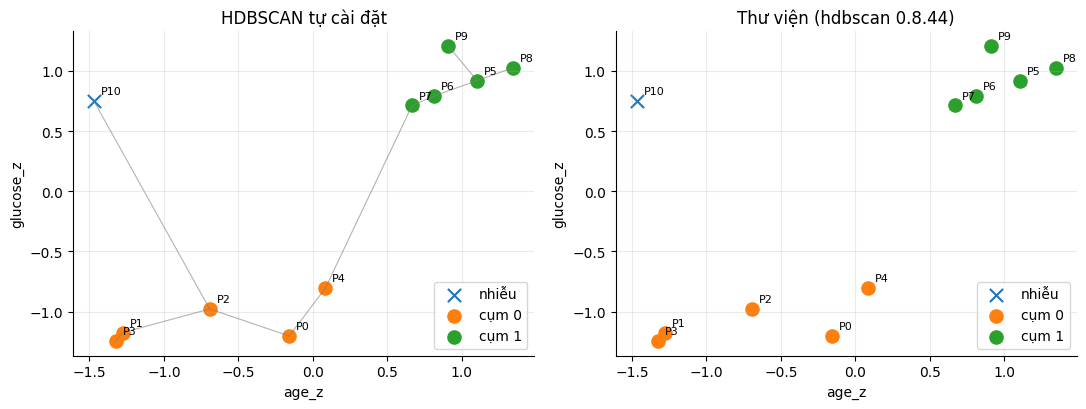

In [66]:
# Chạy HDBSCAN tự cài đặt và bản thư viện trên D1 với cấu hình chung (min_cluster_size=3, min_samples=2)
sc = HDBSCANScratch(3, 2).fit(XD1)
lib = HDBSCANLibraryAdapter(3, 2).fit(XD1)
print("Tự cài :", sc.labels_)
print("Thư viện:", lib.labels_)
print("ARI(tự cài, thư viện) =", EV.ari_manual(sc.labels_, lib.labels_))
print("Cạnh MST (u, v, d_mreach):")
display(pd.DataFrame(sc.mst_[np.argsort(sc.mst_[:, 2])], columns=["u", "v", "d_mreach"]).round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, (lab, ttl) in zip(ax, [(sc.labels_, "HDBSCAN tự cài đặt"), (lib.labels_, f"Thư viện ({LIB_ENGINE.split(' (')[0]})")]):
    for c in np.unique(lab):
        m = lab == c
        a.scatter(XD1[m, 0], XD1[m, 1], s=90, marker="x" if c == NOISE else "o", label="nhiễu" if c == NOISE else f"cụm {c}")
    for i, (x, y) in enumerate(XD1):
        a.annotate(f"P{i}", (x, y), textcoords="offset points", xytext=(5, 5), fontsize=8)
    a.set_title(ttl); a.legend(); a.set_xlabel("age_z"); a.set_ylabel("glucose_z")
for u, v, w in sc.mst_:
    ax[0].plot(XD1[[int(u), int(v)], 0], XD1[[int(u), int(v)], 1], color="gray", lw=.8, alpha=.6)
plt.tight_layout()

### 5.7. Kiểm chứng cài đặt
Gồm: (1) từng bước trung gian so với scipy/sklearn; (2) kiểm lại **ví dụ tính tay 3.4** từ đúng bảng cạnh MST; (3) tái lập mẫu bootstrap seed = 2 ở Ví dụ 4.2; (4) tính chất của S, T, C (Mệnh đề 4.2) và Mệnh đề 4.3; (5) phương án đối chiếu ở 4.5.4–4.5.5.

In [33]:
class ImplementationTests:
    """Các kiểm chứng của mục 5.6. Mỗi test trả về (tên, đạt?, ghi chú)."""

    def __init__(self):
        self.results = []

    def check(self, name, ok, note=""):
        self.results.append((name, bool(ok), note)); return ok

    def intermediate_steps(self, X, mcs, ms):
        """Từng bước trung gian của HDBSCANScratch so với thư viện (6.6)."""
        h = HDBSCANScratch(mcs, ms).fit(X)
        D_sp = cdist(X, X)
        self.check("3.3.1 ma trận khoảng cách = scipy cdist", np.allclose(h.D_, D_sp))
        if len(X) <= 60:
            self.check("3.3.1 bản vòng lặp (giả mã) = bản vector", np.allclose(h.compute_distance_matrix(X, True), h.D_))
        nn = NearestNeighbors(n_neighbors=min(ms, len(X))).fit(X)
        core_ref = nn.kneighbors(X)[0][:, -1]
        self.check("3.3.2 core distance = k-NN (k=min_samples, có tính chính điểm)", np.allclose(h.core_, core_ref))
        Dm_ref = np.maximum(D_sp, np.maximum(core_ref[:, None], core_ref[None, :])); np.fill_diagonal(Dm_ref, 0)
        self.check("3.3.3 mutual reachability", np.allclose(h.Dmreach_, Dm_ref))
        w_ref = minimum_spanning_tree(Dm_ref).sum()
        self.check("3.3.4 tổng trọng số MST (Prim) = scipy", np.isclose(h.mst_[:, 2].sum(), w_ref), f"{h.mst_[:,2].sum():.6f} vs {w_ref:.6f}")
        Z = linkage(squareform(Dm_ref, checks=False), "single")
        self.check("3.3.5 các độ cao single linkage = scipy", np.allclose(np.sort(h.hierarchy_[:, 2]), np.sort(Z[:, 2])))
        lib = HDBSCANLibraryAdapter(mcs, ms).fit(X)
        self.check("Adapter dùng gói hdbscan và quy đổi đúng min_samples",
                   lib.engine_name.startswith("hdbscan ") and lib.min_samples_library_ == min(ms,len(X))-1,
                   f"MS_tự_cài={ms}; MS_hdbscan={lib.min_samples_library_}")
        # Các bước 3.3.6–3.3.8 trên CHÍNH cây single linkage của thư viện phải cho đúng nhãn của thư viện
        h2 = HDBSCANScratch(mcs, ms).fit_from_hierarchy(lib.hierarchy_, len(X))
        ari2 = EV.ari_manual(h2.labels_, lib.labels_); nm2 = EV.noise_mask_agreement(h2.labels_, lib.labels_)
        self.check("3.3.6–3.3.8 (cây của thư viện → cô đọng, EOM, gán nhãn của tự cài) = nhãn thư viện", np.isclose(ari2, 1.0), f"ARI={ari2:.4f}")
        self.check("3.3.8 mặt nạ nhiễu trùng hoàn toàn (cùng cây single linkage)", nm2["agreement"] == 1.0)
        ari = EV.ari_manual(h.labels_, lib.labels_)
        ties = self.tied_merge_fraction(h.hierarchy_)
        self.check("Đầu–cuối: ARI(tự cài, thư viện) ≥ 0,9", ari >= 0.9,
                   f"ARI={ari:.4f}; {ties:.0%} số bước gộp có độ cao trùng với bước kề (đồng trọng số) → thứ tự gộp khác nhau giữa các cài đặt" if ari < 1 - 1e-9 else f"ARI={ari:.4f}")
        return h, lib

    @staticmethod
    def tied_merge_fraction(hier):
        """Tỷ lệ bước gộp của cây single linkage có độ cao bằng (xấp xỉ) độ cao bước kề: nguồn gốc của khác biệt thứ tự gộp."""
        w = np.sort(hier[:, 2]); return float(np.mean(np.isclose(w[1:], w[:-1], rtol=1e-9, atol=0))) if len(w) > 1 else 0.0

    def sampler_example_4_2(self):
        """Ví dụ 4.2: seed=2, B=3, n=11, bootstrap → I1, I2, I3."""
        want = [[9, 2, 1, 3, 4, 8, 4, 1, 3, 6, 8], [8, 10, 2, 9, 0, 6, 3, 2, 7, 3, 6], [2, 1, 8, 4, 7, 7, 10, 4, 2, 6, 10]]
        s = BootstrapSampler(3, 1.0, "bootstrap", 2); got = [list(map(int, I)) for I in s.generate(11)]
        self.check("4.3.1 mẫu bootstrap seed=2 trùng Ví dụ 4.2", got == want)
        s2 = BootstrapSampler(3, 0.8, "subsample", 2); s2.generate(11)
        self.check("Ví dụ 4.2: kiểu (b), ρ=0,8 → 9 điểm khác nhau, không lặp", all(len(I) == len(set(I)) == 9 for I in s2.I_))
        return got

    def coassociation_properties(self, y_rounds):
        """Mệnh đề 4.2 (a)(b)(c) trên các vector nhãn từng lượt y_rounds (B×n)."""
        n = y_rounds.shape[1]
        b = CoAssociationBuilder(n)
        for y in y_rounds:
            b.update(y)
        self.check("Mệnh đề 4.2(a): S, T đối xứng", (b.S == b.S.T).all() and (b.T == b.T.T).all())
        self.check("Mệnh đề 4.2(b): 0 ≤ S ≤ T ≤ B", ((b.S >= 0) & (b.S <= b.T) & (b.T <= len(y_rounds))).all())
        rng = np.random.default_rng(0)
        y2 = y_rounds.copy()
        for r in range(len(y2)):                            # đổi số hiệu cụm ở mỗi lượt bằng một hoán vị
            ids = [c for c in np.unique(y2[r]) if c >= 0]; perm = dict(zip(ids, rng.permutation(ids)))
            y2[r] = np.array([perm.get(v, v) for v in y2[r]])
        b2 = CoAssociationBuilder(n)
        for y in y2:
            b2.update(y)
        self.check("Mệnh đề 4.2(c): đổi số hiệu cụm không làm đổi S, T", (b.S == b2.S).all() and (b.T == b2.T).all())
        return b

    def noise_rule_example_4_8(self):
        """Ví dụ 4.8 – lượt dựng thêm 5 điểm a–e với nhãn (0, 0, −1, −1, ∅): cặp (c,d) cùng nhiễu: T=1, S=0; cặp (a,e): T=0."""
        b = CoAssociationBuilder(5); b.update(np.array([0, 0, -1, -1, UNOBS]))
        self.check("Bảng 4.5: hai điểm cùng nhiễu → T=1, S=0", b.T[2, 3] == 1 and b.S[2, 3] == 0)
        self.check("Bảng 4.5: điểm không lấy mẫu → T=0", b.T[0, 4] == 0 and b.S[0, 4] == 0)
        self.check("Bảng 4.5: cùng cụm hợp lệ → T=1, S=1", b.T[0, 1] == 1 and b.S[0, 1] == 1)

    def proposition_4_3(self, S, T, theta=0.5, t_min=2):
        """Mệnh đề 4.3: thành phần liên thông của đồ thị ngưỡng = cụm của single linkage trên D cắt tại 1 − θ."""
        cc = ConsensusClusterer(theta, t_min, 1, "threshold"); y = cc.fit(S, T)       # c_min = 1: giữ mọi thành phần
        D = cc.dissimilarity(S, T)
        g = fcluster(linkage(squareform(D, checks=False), "single"), 1 - theta + 1e-12, "distance")
        same = lambda a, b: all((a[i] == a[j]) == (b[i] == b[j]) for i in range(len(a)) for j in range(i))
        self.check("Mệnh đề 4.3: thành phần liên thông ≡ single linkage cắt tại 1−θ", same(y, g))

    def example_4_13(self):
        """Ví dụ 4.13: nối chuỗi. 10 điểm, A={0..3}, B={4..7}: C nội bộ 0,9; giữa A–B 0,1 trừ (3,4)=0,6; {8,9}: C=1; còn lại 0,1."""
        n, B = 10, 10
        C = np.full((n, n), 0.1)
        for g in ([0, 1, 2, 3], [4, 5, 6, 7]):
            for i in g:
                for j in g:
                    C[i, j] = 0.9
        C[3, 4] = C[4, 3] = 0.6; C[8, 9] = C[9, 8] = 1.0
        np.fill_diagonal(C, 1.0)
        T = np.full((n, n), B); S = np.rint(C * B).astype(int)
        res = {}
        for m in ("threshold", "average", "hdbscan"):
            res[m] = ConsensusClusterer(0.5, 2, 3, m, hdbscan_min_samples=2).fit(S, T)
        self.check("Ví dụ 4.13: đồ thị ngưỡng gộp A và B (nối chuỗi), {8,9} là nhiễu",
                   len(set(res["threshold"][:8])) == 1 and res["threshold"][0] >= 0 and (res["threshold"][8:] == NOISE).all())
        self.check("Ví dụ 4.14: average linkage tách được A và B", res["average"][0] != res["average"][4] and res["average"][0] >= 0 and res["average"][4] >= 0)
        self.check("Ví dụ 4.14: HDBSCAN(precomputed) tách được A và B", res["hdbscan"][0] != res["hdbscan"][4] and res["hdbscan"][0] >= 0 and res["hdbscan"][4] >= 0)
        return res

    def summary(self):
        df = pd.DataFrame(self.results, columns=["Kiểm chứng", "Đạt", "Ghi chú"])
        df["Đạt"] = df["Đạt"].map({True: "ĐẠT", False: "KHÔNG ĐẠT"})
        return df

In [34]:
T5 = ImplementationTests()
h_chk, lib_chk = T5.intermediate_steps(XD1, 3, 2)
I_ex = T5.sampler_example_4_2()
# Bagging trên D1 với đúng tham số bảng 4.3 (B=3, ρ=1, seed=2, θ=0,5, T_min=2, c_min=3)
bag_d1 = BaggedHDBSCANScratch(3, 2, B=3, rho=1.0, sampling="bootstrap", seed=2, theta=.5, t_min=2, c_min=3).fit(XD1)
T5.coassociation_properties(bag_d1.round_labels_)
T5.noise_rule_example_4_8()
T5.proposition_4_3(bag_d1.S_, bag_d1.T_)
res_4_13 = T5.example_4_13()
# Bagging chạy qua HDBSCAN thư viện với CÙNG mẫu phải cho cùng S, T và nhãn từng lượt (6.7 ở quy mô nhỏ)
bag_d1_lib = BaggedHDBSCANScratch(3, 2, B=3, rho=1.0, seed=2, engine="library").fit(XD1, samples=bag_d1.samples_)
T5.check("6.7 (D1): nhãn từng lượt, S, T, nhãn cuối trùng giữa bản tự cài và bản thư viện",
         (bag_d1.round_labels_ == bag_d1_lib.round_labels_).all() and (bag_d1.S_ == bag_d1_lib.S_).all()
         and (bag_d1.T_ == bag_d1_lib.T_).all() and (bag_d1.labels_ == bag_d1_lib.labels_).all())
T5.summary()

,Kiểm chứng,Đạt,Ghi chú
0,3.3.1 ma trận khoảng cách = scipy cdist,ĐẠT,
1,3.3.1 bản vòng lặp (giả mã) = bản vector,ĐẠT,
2,"3.3.2 core distance = k-NN (k=min_samples, có ...",ĐẠT,
3,3.3.3 mutual reachability,ĐẠT,
4,3.3.4 tổng trọng số MST (Prim) = scipy,ĐẠT,6.353224 vs 6.353224
5,3.3.5 các độ cao single linkage = scipy,ĐẠT,
6,Adapter dùng gói hdbscan và quy đổi đúng min_s...,ĐẠT,MS_tự_cài=2; MS_hdbscan=1
7,"3.3.6–3.3.8 (cây của thư viện → cô đọng, EOM, ...",ĐẠT,ARI=1.0000
8,3.3.8 mặt nạ nhiễu trùng hoàn toàn (cùng cây s...,ĐẠT,
9,"Đầu–cuối: ARI(tự cài, thư viện) ≥ 0,9",ĐẠT,ARI=1.0000


In [35]:
# Kết quả Bagging trên D1: nhãn từng lượt (bảng 4.4), ma trận C và nhãn đồng thuận
rl = bag_d1.round_labels_
tab = pd.DataFrame(np.where(rl == UNOBS, "∅", rl.astype(str)), columns=[f"P{i}" for i in range(len(XD1))], index=[f"Lượt {b+1}" for b in range(len(rl))])
print("Nhãn từng lượt sau ánh xạ (∅: không được lấy mẫu; −1: nhiễu):"); display(tab)
n = len(XD1); iu = np.triu_indices(n, 1)
print("Ma trận C = S/T (NaN: T = 0):"); display(pd.DataFrame(bag_d1.C_, columns=tab.columns, index=tab.columns).round(2))
print(f"Cặp có T=0: {(bag_d1.T_[iu]==0).sum()}, 0<T<T_min: {((bag_d1.T_[iu]>0)&(bag_d1.T_[iu]<2)).sum()}, T≥T_min: {(bag_d1.T_[iu]>=2).sum()}; độ bao phủ cặp = {bag_d1.builder_.pair_coverage(2):.3f}")
print("Số cạnh đồ thị ngưỡng:", len(bag_d1.consensus_.edges_))
print("Nhãn đồng thuận y*   :", bag_d1.labels_)
print("HDBSCAN đơn lẻ (mục 3.4):", sc.labels_)
print("E|U|/n (Mệnh đề 4.1) với n=m=11:", round(BootstrapSampler.expected_unique_fraction(11, 11), 4))

Nhãn từng lượt sau ánh xạ (∅: không được lấy mẫu; −1: nhiễu):


,P0,P1,P2,P3,P4,P5,P6,P7,P8,P9,P10
Lượt 1,∅,0,0,0,0,∅,1,∅,1,1,∅
Lượt 2,0,∅,0,0,∅,∅,1,1,1,1,0
Lượt 3,∅,0,0,∅,0,∅,1,1,1,∅,-1


Ma trận C = S/T (NaN: T = 0):


,P0,P1,P2,P3,P4,P5,P6,P7,P8,P9,P10
P0,1.0,NaN,1.0,1.0,NaN,NaN,0.0,0.0,0.0,0.0,1.0
P1,NaN,1.0,1.0,1.0,1.0,NaN,0.0,0.0,0.0,0.0,0.0
P2,1.0,1.0,1.0,1.0,1.0,NaN,0.0,0.0,0.0,0.0,0.5
P3,1.0,1.0,1.0,1.0,1.0,NaN,0.0,0.0,0.0,0.0,1.0
P4,NaN,1.0,1.0,1.0,1.0,NaN,0.0,0.0,0.0,0.0,0.0
P5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
P6,0.0,0.0,0.0,0.0,0.0,NaN,1.0,1.0,1.0,1.0,0.0
P7,0.0,0.0,0.0,0.0,0.0,NaN,1.0,1.0,1.0,1.0,0.0
P8,0.0,0.0,0.0,0.0,0.0,NaN,1.0,1.0,1.0,1.0,0.0
P9,0.0,0.0,0.0,0.0,0.0,NaN,1.0,1.0,1.0,1.0,0.0


Cặp có T=0: 12, 0<T<T_min: 19, T≥T_min: 24; độ bao phủ cặp = 0.436
Số cạnh đồ thị ngưỡng: 10
Nhãn đồng thuận y*   : [-1  0  0  0  0 -1  1  1  1  1  0]
HDBSCAN đơn lẻ (mục 3.4): [ 0  0  0  0  0  1  1  1  1  1 -1]
E|U|/n (Mệnh đề 4.1) với n=m=11: 0.6495


**Kiểm lại ví dụ tính tay ở mục 3.4.** Bảng cạnh MST ở 3.4.3 (10 cạnh) được đưa thẳng vào đường ống từ bước 3.3.5. Kết quả của chương trình được đối chiếu với các con số trong 3.4.5 – 3.4.7.

In [36]:
mst_hand = np.array([(5, 6, .3181), (5, 9, .4259), (5, 8, .4720), (5, 7, .4831), (0, 2, .6143),
                     (1, 2, .6143), (1, 3, .6844), (0, 4, .7953), (4, 7, 1.6242), (1, 10, 1.9298)])
hh = HDBSCANScratch(3, 3).fit_from_mst(mst_hand, 11)
print("Nhãn (cụm theo thứ tự nhãn cây cô đọng):", hh.labels_)
print("\nCây cô đọng (cha, con, λ, kích thước):")
display(pd.DataFrame(hh.condensed_, columns=["cha", "con", "lambda", "size"]).round(4))
names = {11: "C_root"}
print("λ_birth:", {k: round(v, 4) for k, v in hh.birth_.items()})
print("Độ ổn định S(C):", {k: round(v, 4) for k, v in hh.stability_.items()})
print("Cụm được chọn:", hh.selected_)

Nhãn (cụm theo thứ tự nhãn cây cô đọng): [ 0  0  0  0  0  1  1  1  1  1 -1]

Cây cô đọng (cha, con, λ, kích thước):


,cha,con,lambda,size
0,11,10,0.5182,1
1,11,12,0.6157,5
2,11,13,0.6157,5
3,13,7,2.0700,1
4,13,8,2.1186,1
5,13,6,2.3480,1
6,13,5,2.3480,1
7,13,9,2.3480,1
8,12,4,1.2574,1
9,12,3,1.4611,1


λ_birth: {11: 0.0, 12: np.float64(0.6157), 13: np.float64(0.6157)}
Độ ổn định S(C): {11: np.float64(6.6751), 13: np.float64(8.1541), 12: np.float64(4.5237)}
Cụm được chọn: [12, 13]


**Nhận xét khi đối chiếu ví dụ 3.4.** Đường ống tái lập đúng: P10 rơi tại λ = 0,5182; tách cụm tại λ = 0,6157 thành {P0..P4} và {P5..P9}; P4, P3 rơi tại 1,2574 và 1,4611; ba điểm lõi P0, P1, P2 rơi tại 1,6279; P7, P8 rơi tại 2,0700 và 2,1188; S(C_root) ≈ 6,675 và S(C_A) ≈ 4,524 – **khớp bản tính tay**.

Có **một điểm không khớp** cần sửa trong báo cáo (mục 3.4.5 bước 8–9, 3.4.6): khi nhánh {P5, P6, P9} (3 điểm = min_cluster_size) bị cắt tại cạnh P5–P9 thành hai nhánh {P9} (1 điểm) và {P5, P6} (2 điểm), **cả hai đều nhỏ hơn min_cluster_size**, nên theo đúng quy tắc cô đọng (3.2.6, giả mã 3.3.6, nhánh `ELSE` cuối) *mọi* điểm của hai nhánh rơi rớt cùng tại λ = 2,3478. Do đó λ(P5) = λ(P6) = 2,3478 (không phải 3,1435), λ_max(C_B) = 2,3478 và S(C_B) ≈ 8,154 (không phải 9,7451; lưu ý bản tính tay còn ghi nhầm S(C_B) = 4,5237 ở dòng công thức). Quyết định EOM không đổi vì 4,524 + 8,154 = 12,678 > 6,675.

### 5.8. Bảng liên kết lý thuyết với chương trình

In [37]:
# 5.8 Bảng liên kết lý thuyết với chương trình
link = pd.DataFrame([
    ("3.2.1 / 3.3.1", "Khoảng cách Euclidean, ma trận D", "HDBSCANScratch.compute_distance_matrix", "Test 3.3.1 (cdist; bản vòng lặp)"),
    ("3.2.2 / 3.3.2", "Core distance (có tính chính điểm)", "HDBSCANScratch.compute_core_distances", "Test 3.3.2 (k-NN)"),
    ("3.2.3 / 3.3.3", "Mutual reachability", "HDBSCANScratch.compute_mutual_reachability", "Test 3.3.3"),
    ("3.2.4 / 3.3.4", "MST bằng Prim", "HDBSCANScratch.build_mst_prim", "Test 3.3.4 (tổng trọng số = scipy)"),
    ("3.2.5 / 3.3.5", "Single linkage, λ = 1/d (UnionFind)", "HDBSCANScratch.build_single_linkage, UnionFind", "Test 3.3.5 (độ cao = scipy)"),
    ("3.2.6 / 3.3.6", "Cây cô đọng", "HDBSCANScratch.condense_tree", "Ví dụ 3.4 (ô kiểm lại ví dụ tính tay)"),
    ("3.2.7", "Mức sinh/rơi, độ ổn định", "HDBSCANScratch.compute_stability", "Ví dụ 3.4: S(C_root), S(C_A)"),
    ("3.2.8 / 3.3.7", "Chọn cụm EOM", "HDBSCANScratch.select_clusters_eom", "Test nhãn cuối = thư viện"),
    ("3.2.9 / 3.3.8", "Gán nhãn, nhiễu, xác suất", "HDBSCANScratch.assign_labels", "Test mặt nạ nhiễu trùng"),
    ("4.3.1", "Sinh và lưu chỉ số mẫu", "BootstrapSampler.generate", "Ví dụ 4.2 (seed = 2)"),
    ("4.3.2–4.3.5", "HDBSCAN từng mẫu, ánh xạ, điểm lặp, vắng", "BaggedHDBSCANScratch.fit_rounds", "Bảng 4.4; 6.7"),
    ("4.4.1–4.4.5", "S, T, C và quy tắc nhiễu", "CoAssociationBuilder.update / .C", "Mệnh đề 4.2; Bảng 4.5; Ví dụ 4.8"),
    ("4.5.1–4.5.3", "Đồ thị ngưỡng, thành phần liên thông, nhãn", "ConsensusClusterer.fit('threshold'), UnionFind.components", "Mệnh đề 4.3"),
    ("4.5.4–4.5.5", "Nối chuỗi; average linkage, HDBSCAN trên 1−C", "ConsensusClusterer.fit('average' | 'hdbscan')", "Ví dụ 4.13, 4.14"),
    ("4.6", "Giả mã tổng thể", "BaggedHDBSCANScratch.fit", "6.7"),
    ("2.5", "Chỉ số đánh giá", "ClusteringEvaluator", "ARI tự cài = sklearn (ô kế tiếp)"),
], columns=["Mục lý thuyết", "Nội dung", "Lớp.phương thức", "Kiểm chứng"])
display(link)
a1 = np.random.default_rng(1).integers(0, 4, 200); a2 = np.random.default_rng(2).integers(0, 3, 200)
print("ARI tự cài vs sklearn:", EV.ari_manual(a1, a2), adjusted_rand_score(a1, a2))
# Kiểm DBCV: gần 1 với hai cụm tách xa, âm/thấp với dữ liệu ngẫu nhiên
rg = np.random.default_rng(0)
Xb = np.vstack([rg.normal(0, .3, (60, 2)), rg.normal(5, .3, (60, 2))]); yb = np.r_[np.zeros(60), np.ones(60)].astype(int)
Xr = rg.uniform(0, 1, (120, 2)); yr = rg.integers(0, 2, 120)
print("DBCV 2 cụm tách xa:", round(EV.dbcv(Xb, yb), 3), "| DBCV nhãn ngẫu nhiên:", round(EV.dbcv(Xr, yr), 3))

,Mục lý thuyết,Nội dung,Lớp.phương thức,Kiểm chứng
0,3.2.1 / 3.3.1,"Khoảng cách Euclidean, ma trận D",HDBSCANScratch.compute_distance_matrix,Test 3.3.1 (cdist; bản vòng lặp)
1,3.2.2 / 3.3.2,Core distance (có tính chính điểm),HDBSCANScratch.compute_core_distances,Test 3.3.2 (k-NN)
2,3.2.3 / 3.3.3,Mutual reachability,HDBSCANScratch.compute_mutual_reachability,Test 3.3.3
3,3.2.4 / 3.3.4,MST bằng Prim,HDBSCANScratch.build_mst_prim,Test 3.3.4 (tổng trọng số = scipy)
4,3.2.5 / 3.3.5,"Single linkage, λ = 1/d (UnionFind)","HDBSCANScratch.build_single_linkage, UnionFind",Test 3.3.5 (độ cao = scipy)
5,3.2.6 / 3.3.6,Cây cô đọng,HDBSCANScratch.condense_tree,Ví dụ 3.4 (ô kiểm lại ví dụ tính tay)
6,3.2.7,"Mức sinh/rơi, độ ổn định",HDBSCANScratch.compute_stability,"Ví dụ 3.4: S(C_root), S(C_A)"
7,3.2.8 / 3.3.7,Chọn cụm EOM,HDBSCANScratch.select_clusters_eom,Test nhãn cuối = thư viện
8,3.2.9 / 3.3.8,"Gán nhãn, nhiễu, xác suất",HDBSCANScratch.assign_labels,Test mặt nạ nhiễu trùng
9,4.3.1,Sinh và lưu chỉ số mẫu,BootstrapSampler.generate,Ví dụ 4.2 (seed = 2)


ARI tự cài vs sklearn: -0.006430517444760971 -0.006430517444760947
DBCV 2 cụm tách xa: 0.95 | DBCV nhãn ngẫu nhiên: -0.405


## Chương 6. Dữ liệu, thực nghiệm và so sánh
### 6.1. Giới thiệu dataset duy nhất
**Stroke-like Synthetic Dataset v2 (HDBSCAN-Bagging)** do nhóm tự sinh với seed 2027,
gồm **2.985 dòng, 12 cột** trong sheet `healthcare-dataset-stroke-data`.
Dataset mô phỏng cấu trúc của Stroke Prediction Dataset; các dòng là quan sát tổng hợp,
không phải dữ liệu bệnh nhân thật. Thông tin nguồn được đọc từ sheet `Nguon`.

Hai biến phân cụm vẫn là `age` và `avg_glucose_level`.
`id`, `stroke`, `profile_thiet_ke` không đưa vào không gian đặc trưng.
`stroke` là nhãn tham khảo mô phỏng; `profile_thiet_ke` mô tả nhóm sinh dữ liệu
(C0–C7, BR là cầu nối, NZ là nhiễu được sinh). Cả hai không dùng để chọn tham số.
Các nhóm thiết kế có thể chồng lấn khi chỉ quan sát hai biến nên không mặc định HDBSCAN phải tách đủ sáu nhóm.

Đặt file `synthetic-stroke-hdbscan-data-v2.xlsx` cạnh notebook hoặc trong thư mục `Raw` của thư mục chạy.
Các ví dụ D1 và kịch bản S1–S3 vẫn là bộ kiểm chứng độc lập đã có, không thay cho dữ liệu thực nghiệm chính.


In [38]:
from pathlib import Path

XLSX_NAME = "synthetic-stroke-hdbscan-data.xlsx"
XLSX = Path(XLSX_NAME)
if not XLSX.is_file():
    XLSX = Path("Raw") / XLSX_NAME
if not XLSX.is_file():
    raise FileNotFoundError(f"Đặt {XLSX_NAME} cạnh notebook hoặc trong thư mục Raw của thư mục chạy.")
SHEET = "healthcare-dataset-stroke-data"
raw = pd.read_excel(XLSX, sheet_name=SHEET)
required = {"id", "age", "avg_glucose_level", "bmi", "stroke"}
if not required.issubset(raw.columns):
    raise ValueError(f"Thiếu cột cần dùng: {sorted(required - set(raw.columns))}")
if raw["id"].isna().any() or not raw["id"].is_unique:
    raise ValueError("Cột id phải đầy đủ và duy nhất để đối chiếu các sheet theo đúng dòng.")
if raw["stroke"].isna().any() or not raw["stroke"].isin([0, 1]).all():
    raise ValueError("Nhãn tham khảo stroke phải có giá trị 0 hoặc 1.")
for column in ["age", "avg_glucose_level"]:
    if not pd.api.types.is_numeric_dtype(raw[column]):
        raise TypeError(f"Cột {column} phải là số.")
source_info = pd.read_excel(XLSX, sheet_name="Nguon", header=0).iloc[0].dropna().to_dict()
print("File dữ liệu:", XLSX.name)
print("Kích thước:", raw.shape)
print("Nguồn:", source_info)
print("DỮ LIỆU TỔNG HỢP; stroke chỉ là nhãn tham khảo mô phỏng.")
display(raw.head())
display(raw.dtypes.to_frame("kiểu").T)
print("Giá trị thiếu:", raw.isna().sum()[lambda s: s > 0].to_dict())
print("Nhãn tham khảo stroke:", raw["stroke"].value_counts().to_dict(), f"(tỷ lệ stroke=1: {raw['stroke'].mean():.4f})")


File dữ liệu: synthetic-stroke-hdbscan-data.xlsx
Kích thước: (2985, 12)
Nguồn: {'Tên dataset': 'Stroke-like Synthetic Dataset v2 (HDBSCAN-Bagging)', 'Tác giả': 'Dữ liệu tổng hợp do nhóm tự sinh (seed=2027)', 'Link': 'Mô phỏng cấu trúc cột của Stroke Prediction Dataset (Fedesoriano, Kaggle)', 'Số dòng': 2985, 'Số cột': 12, 'Ghi chú': 'DỮ LIỆU TỔNG HỢP, không phải dữ liệu bệnh nhân thật. Phải nêu rõ trong đồ án. Cột stroke chỉ là nhãn tham khảo mô phỏng.'}
DỮ LIỆU TỔNG HỢP; stroke chỉ là nhãn tham khảo mô phỏng.


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,66976,Female,40.0,0,0,No,Govt_job,Rural,86.82,27.1,never smoked,0
1,22723,Female,50.0,1,1,Yes,Private,Rural,131.02,36.2,formerly smoked,0
2,25714,Female,76.0,0,0,No,Govt_job,Urban,143.59,25.0,smokes,0
3,25591,Male,5.0,0,0,No,children,Rural,77.98,14.9,Unknown,0
4,67872,Female,75.0,1,0,Yes,Self-employed,Urban,125.99,31.1,smokes,0


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
kiểu,int64,str,float64,int64,int64,str,str,str,float64,float64,str,int64


Giá trị thiếu: {'bmi': 141}
Nhãn tham khảo stroke: {0: 2848, 1: 137} (tỷ lệ stroke=1: 0.0459)


### 6.1b. Biểu đồ tổng quan dữ liệu
Các biểu đồ dưới đây chỉ **mô tả dữ liệu** (chưa tiền xử lý, chưa phân cụm): chất lượng dữ liệu (thiếu, trùng, ngoại lệ),
phân phối các cột phân loại và nhãn tham khảo `stroke`. Không biểu đồ nào ở đây ảnh hưởng đến việc chọn tham số.

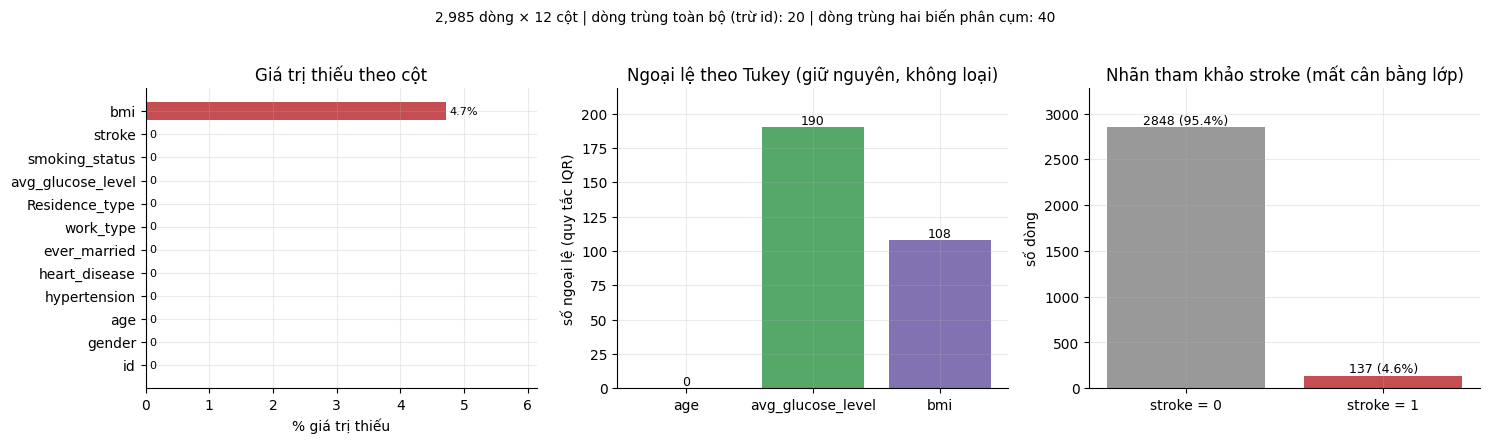

In [39]:
# 6.1b (1) Chất lượng dữ liệu: giá trị thiếu, ngoại lệ, nhãn tham khảo
_feat2 = ["age", "avg_glucose_level"]
n_dup_all = int(raw.drop(columns="id").duplicated().sum()); n_dup_feat = int(raw.duplicated(subset=_feat2).sum())
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))

miss = raw.isna().mean().mul(100).sort_values()
ax[0].barh(miss.index, miss.values, color=["#C44E52" if v > 0 else "#9DB4D3" for v in miss.values])
for y, v in enumerate(miss.values):
    ax[0].text(v + 0.05, y, f"{v:.1f}%" if v > 0 else "0", va="center", fontsize=8)
ax[0].set_xlabel("% giá trị thiếu"); ax[0].set_title("Giá trị thiếu theo cột"); ax[0].set_xlim(0, max(miss.max() * 1.3, 1))

num_cols = ["age", "avg_glucose_level", "bmi"]
n_out = [Preprocessor.iqr_outliers(raw[c].dropna())[0] for c in num_cols]
bars = ax[1].bar(num_cols, n_out, color=["#4C72B0", "#55A868", "#8172B2"])
for b_, v in zip(bars, n_out):
    ax[1].text(b_.get_x() + b_.get_width() / 2, v, str(v), ha="center", va="bottom", fontsize=9)
ax[1].set_ylabel("số ngoại lệ (quy tắc IQR)"); ax[1].set_title("Ngoại lệ theo Tukey (giữ nguyên, không loại)")
ax[1].set_ylim(0, max(max(n_out) * 1.15, 1))

vc = raw["stroke"].value_counts().sort_index()
bars = ax[2].bar(["stroke = 0", "stroke = 1"], vc.values, color=["#999999", "#C44E52"])
for b_, v in zip(bars, vc.values):
    ax[2].text(b_.get_x() + b_.get_width() / 2, v, f"{v} ({v / len(raw):.1%})", ha="center", va="bottom", fontsize=9)
ax[2].set_title("Nhãn tham khảo stroke (mất cân bằng lớp)"); ax[2].set_ylabel("số dòng"); ax[2].set_ylim(0, vc.max() * 1.15)
fig.suptitle(f"{len(raw):,} dòng × {raw.shape[1]} cột | dòng trùng toàn bộ (trừ id): {n_dup_all} | dòng trùng hai biến phân cụm: {n_dup_feat}", fontsize=10, y=1.02)
plt.tight_layout()

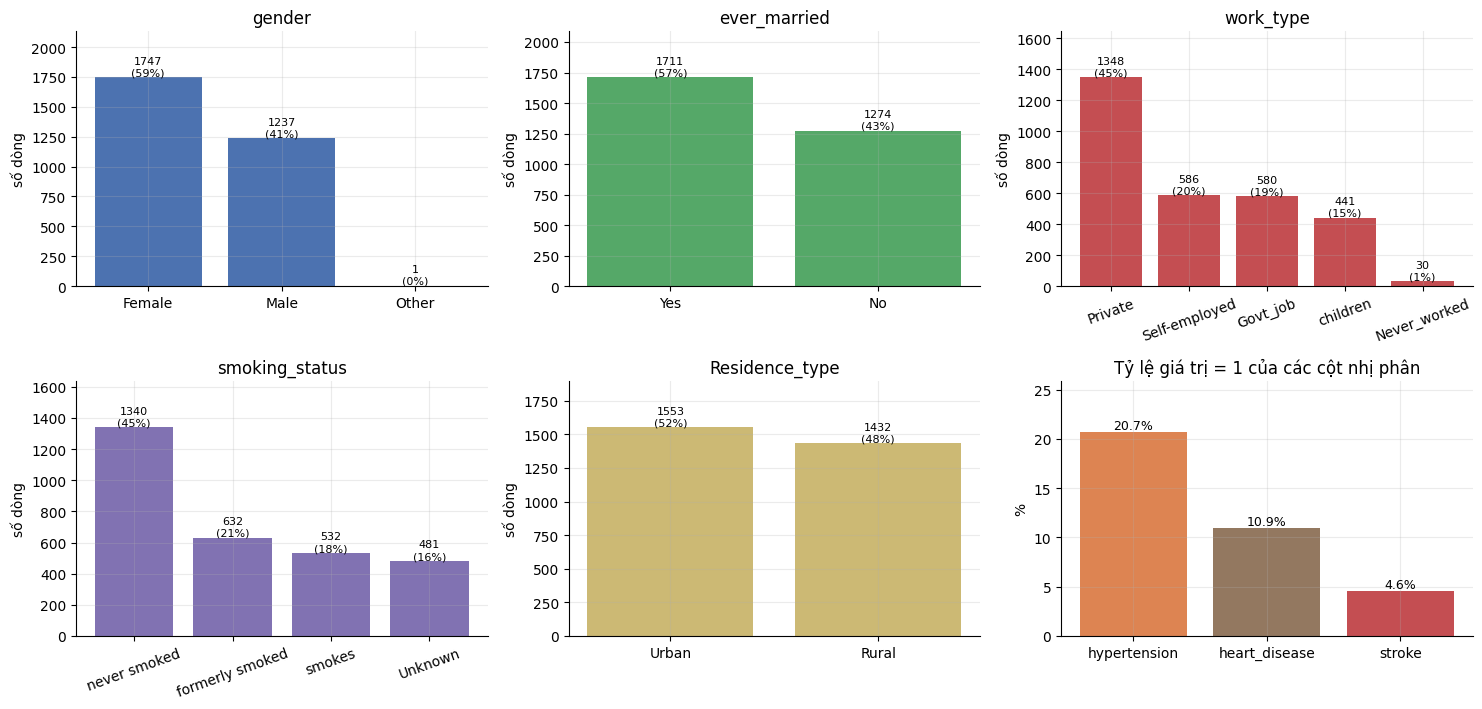

In [40]:
# 6.1b (2) Phân phối các cột phân loại và cột nhị phân
cat_cols = ["gender", "ever_married", "work_type", "smoking_status", "Residence_type"]
palette = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.2)); axes = axes.ravel()
for a, c, col in zip(axes, cat_cols, palette):
    vc = raw[c].value_counts()
    bars = a.bar(vc.index.astype(str), vc.values, color=col)
    for b_, v in zip(bars, vc.values):
        a.text(b_.get_x() + b_.get_width() / 2, v, f"{v}\n({v / len(raw):.0%})", ha="center", va="bottom", fontsize=8)
    a.set_title(c); a.set_ylabel("số dòng"); a.set_ylim(0, vc.max() * 1.22)
    if len(vc) > 3: a.tick_params(axis="x", rotation=20)
bin_cols = ["hypertension", "heart_disease", "stroke"]
share = [raw[c].mean() * 100 for c in bin_cols]
bars = axes[5].bar(bin_cols, share, color=["#DD8452", "#937860", "#C44E52"])
for b_, v in zip(bars, share):
    axes[5].text(b_.get_x() + b_.get_width() / 2, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
axes[5].set_title("Tỷ lệ giá trị = 1 của các cột nhị phân"); axes[5].set_ylabel("%"); axes[5].set_ylim(0, max(share) * 1.25)
plt.tight_layout()

### 6.1c. Vì sao dùng dữ liệu tổng hợp có thiết kế cụm trước
**Vấn đề.** Phân cụm là học không giám sát: dữ liệu thật không có "đáp án cụm". Nhãn `stroke` là nhãn bệnh, không phải nhãn cụm, nên không thể kết luận một phân hoạch là đúng hay sai.
Điều đó khiến câu hỏi trọng tâm của đồ án (Bagging có làm HDBSCAN tốt hơn không, và trong điều kiện nào) khó trả lời chỉ bằng dữ liệu thật.

**Cách làm.** Sinh dữ liệu từ các nhóm có tham số biết trước (benchmark có kiểm soát, cách làm phổ biến khi đánh giá thuật toán phân cụm). Mỗi nhóm đại diện cho một tình huống mà HDBSCAN hoặc Bagging cần được kiểm tra:

| Nhóm | Tình huống | Câu hỏi đồ án trả lời |
|---|---|---|
| C0, C1, C2, C3 | cụm có mật độ khác nhau (dày đến thưa) | HDBSCAN xử lý đa mật độ ra sao (3.7) |
| C4 (105 dòng), C6 (45 dòng) | cụm nhỏ, trong đó C6 rất nhỏ nhưng dày | cụm nhỏ có sống sót khi lấy mẫu lại không (4.8, 6.11) |
| C5 | cụm thưa, phương sai lớn | ảnh hưởng của `min_samples` |
| C3 và C7 | hai cụm chồng lấn một phần trên (age, glucose), tách rõ khi thêm `bmi` | HDBSCAN đơn lẻ có thiếu ổn định không; Bagging có ổn định hơn không; thêm biến có giúp không (6.10b, 6.10c) |
| BR | cầu nối thưa giữa C1 và C2 | nguy cơ nối chuỗi của thành phần liên thông (4.5.4, 6.9) |
| NZ | nhiễu và ngoại lệ | khả năng nhận nhiễu |
| dòng trùng, `gender = Other`, `bmi` thiếu | lỗi dữ liệu thực tế | tiền xử lý (2.4, 4.3.4) |

**Vì sao cách làm này chấp nhận được.**
* Có đáp án để đo (ARI so với nhóm thiết kế), điều mà dữ liệu thật không cho.
* Từng hiện tượng được tách riêng, nên biết nguyên nhân khi một phương pháp tốt hơn hay kém hơn.
* Tái lập được: mã sinh dữ liệu và seed được công khai ở Phụ lục A.
* Giúp kiểm chứng cài đặt: biết trước cấu trúc thì phát hiện được lỗi cài đặt.

**Nguyên tắc để kết quả khách quan.** Nhãn thiết kế (sheet `Thiet_ke_cum`) không được dùng khi chọn tham số hay lấy mẫu; tham số chọn trên tập phát triển bằng DBCV (không cần nhãn), rồi khóa và đánh giá trên tập rời.
Thiết kế dữ liệu được cố định trước khi chạy Bagging và không chỉnh theo kết quả Bagging.

**Giới hạn cần nói rõ (mục 7.3).**
* Đáp án cụm do chính thiết kế tạo ra, nên ARI cao chỉ cho thấy thuật toán khôi phục được cấu trúc đã đặt, không chứng minh hiệu quả trên dữ liệu thật.
* Độ tách giữa các nhóm do người thiết kế chọn, nên các kết luận chỉ áp dụng cho loại cấu trúc đã mô phỏng.
* Đây không phải dữ liệu bệnh nhân thật; không suy luận y học từ các cột và nhãn `stroke`.
* Nên đối chiếu thêm với một bộ dữ liệu thật như phép đối chứng.

### 6.2. Phân tích khám phá
Mục tiêu: kiểm tra giả định của đề tài rằng dữ liệu có **mật độ không đồng đều** trong không gian đặc trưng (age, avg_glucose_level) *bằng số liệu*, không chỉ nêu như một nhận định.

,count,mean,std,min,25%,50%,75%,max
age,2985.0,44.30,22.59,0.50,29.00,47.0,65.00,82.00
avg_glucose_level,2985.0,114.06,39.38,58.51,85.97,102.9,126.85,264.83
bmi,2844.0,28.94,11.13,10.90,23.28,27.6,33.30,97.00


Số dòng trùng (age, avg_glucose_level): 40 | trùng toàn bộ cột (trừ id): 20


,số ngoại lệ,tỷ lệ
age,0.0,0.000000
avg_glucose_level,190.0,0.063652
bmi,108.0,0.037975


Hệ số tương quan Pearson:


,age,avg_glucose_level,bmi
age,1.000,0.458,0.328
avg_glucose_level,0.458,1.000,0.563
bmi,0.328,0.563,1.000


core distance k=10: P10=0.031, P50=0.053, P90=0.150  → vùng thưa có bán kính lân cận gấp 4.8 lần vùng dày (P90/P10).


Text(0, 0.5, 'PC2')

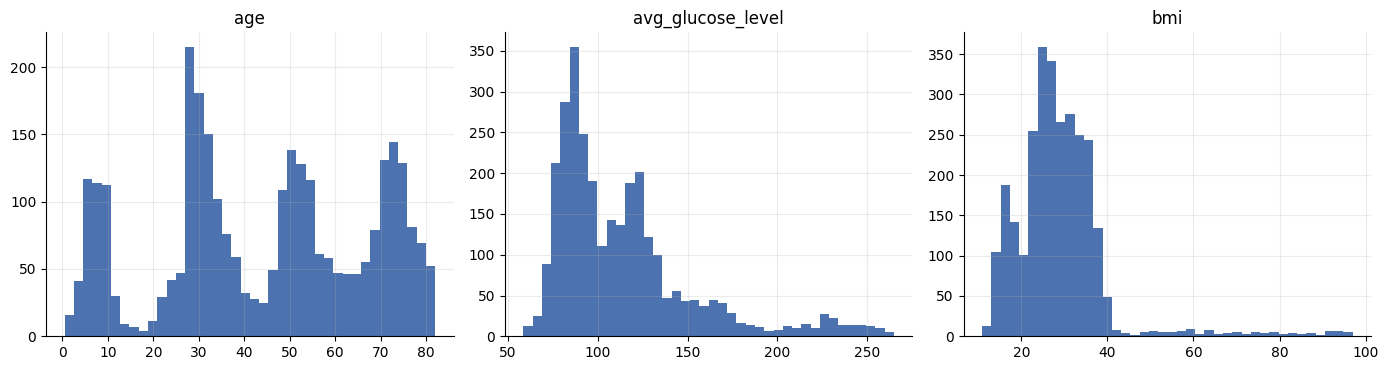

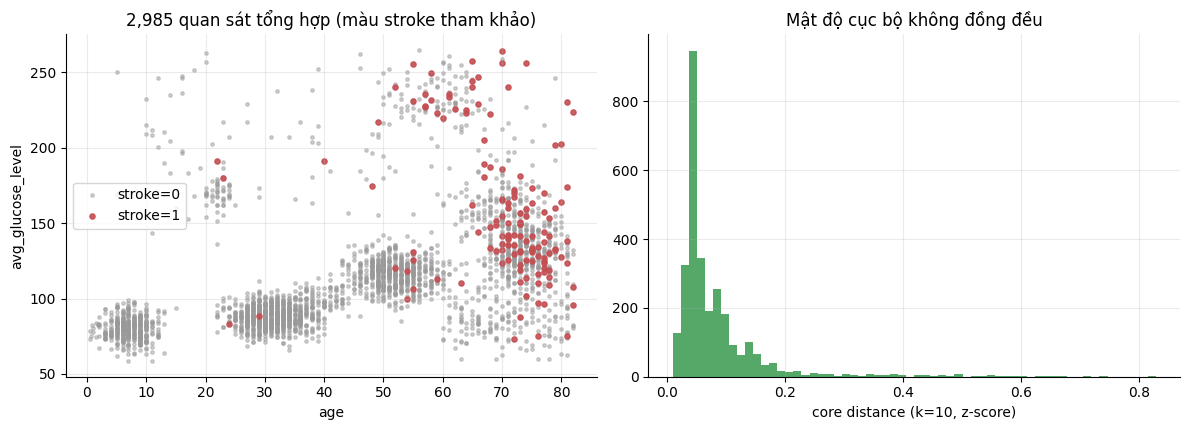

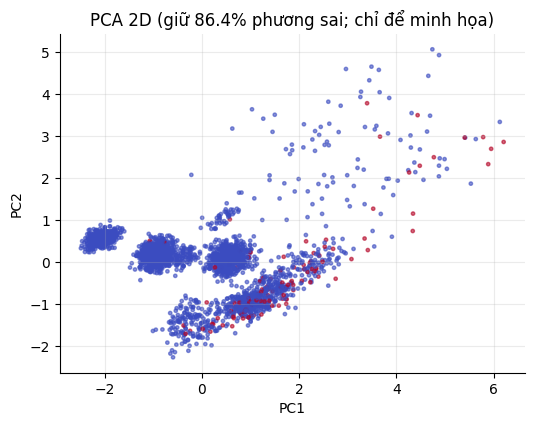

In [41]:
FEAT = ["age", "avg_glucose_level"]
num = raw[["age", "avg_glucose_level", "bmi"]]
display(num.describe().T.round(2))
pp = Preprocessor(FEAT)
print("Số dòng trùng (age, avg_glucose_level):", pp.duplicate_report(raw, FEAT), "| trùng toàn bộ cột (trừ id):", pp.duplicate_report(raw.drop(columns="id"), list(raw.columns.drop("id"))))
out_tab = pd.DataFrame({c: pp.iqr_outliers(num[c].dropna()) for c in num.columns}, index=["số ngoại lệ", "tỷ lệ"]).T
display(out_tab)
print("Hệ số tương quan Pearson:"); display(num.corr().round(3))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, c in zip(ax, num.columns):
    a.hist(num[c].dropna(), bins=40, color="#4C72B0"); a.set_title(c)
plt.tight_layout()

Zfull = Preprocessor.zscore(raw[FEAT].drop_duplicates().to_numpy(float))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for v, c, l in [(0, "#999", "stroke=0"), (1, "#C44E52", "stroke=1")]:
    m = raw["stroke"].values == v
    ax[0].scatter(raw.loc[m, "age"], raw.loc[m, "avg_glucose_level"], s=6 if v == 0 else 14, alpha=.45 if v == 0 else .9, c=c, label=l)
ax[0].set_xlabel("age"); ax[0].set_ylabel("avg_glucose_level"); ax[0].legend(); ax[0].set_title(f"{len(raw):,} quan sát tổng hợp (màu stroke tham khảo)")
# Bằng chứng đa mật độ: phân phối core distance (k=10) trên không gian đã chuẩn hóa
nn = NearestNeighbors(n_neighbors=10).fit(Zfull); core10 = nn.kneighbors(Zfull)[0][:, -1]
ax[1].hist(core10, bins=60, color="#55A868"); ax[1].set_xlabel("core distance (k=10, z-score)"); ax[1].set_title("Mật độ cục bộ không đồng đều")
plt.tight_layout()
q = np.percentile(core10, [10, 50, 90])
print(f"core distance k=10: P10={q[0]:.3f}, P50={q[1]:.3f}, P90={q[2]:.3f}  → vùng thưa có bán kính lân cận gấp {q[2]/q[0]:.1f} lần vùng dày (P90/P10).")

# PCA 2D (chỉ để trực quan hóa; trên ba biến số age, avg_glucose_level, bmi, bỏ dòng thiếu bmi)
nb3 = raw[["age", "avg_glucose_level", "bmi", "stroke"]].dropna()
P2, ratio = Preprocessor.pca_2d(Preprocessor.zscore(nb3[["age", "avg_glucose_level", "bmi"]].to_numpy(float)))
plt.figure(figsize=(6, 4.4)); plt.scatter(P2[:, 0], P2[:, 1], c=nb3["stroke"], s=6, cmap="coolwarm", alpha=.6)
plt.title(f"PCA 2D (giữ {ratio:.1%} phương sai; chỉ để minh họa)"); plt.xlabel("PC1"); plt.ylabel("PC2")


### 6.2b. Biểu đồ bổ sung cho phân tích khám phá
Bổ sung cho các biểu đồ ở 6.2: phân phối biến số theo nhãn tham khảo, tương quan, quan hệ từng cặp biến số, bản đồ mật độ cục bộ (liên hệ trực tiếp với core distance của HDBSCAN)
và mô tả thiết kế dữ liệu tổng hợp. Chỉ để mô tả; không dùng để chọn tham số.

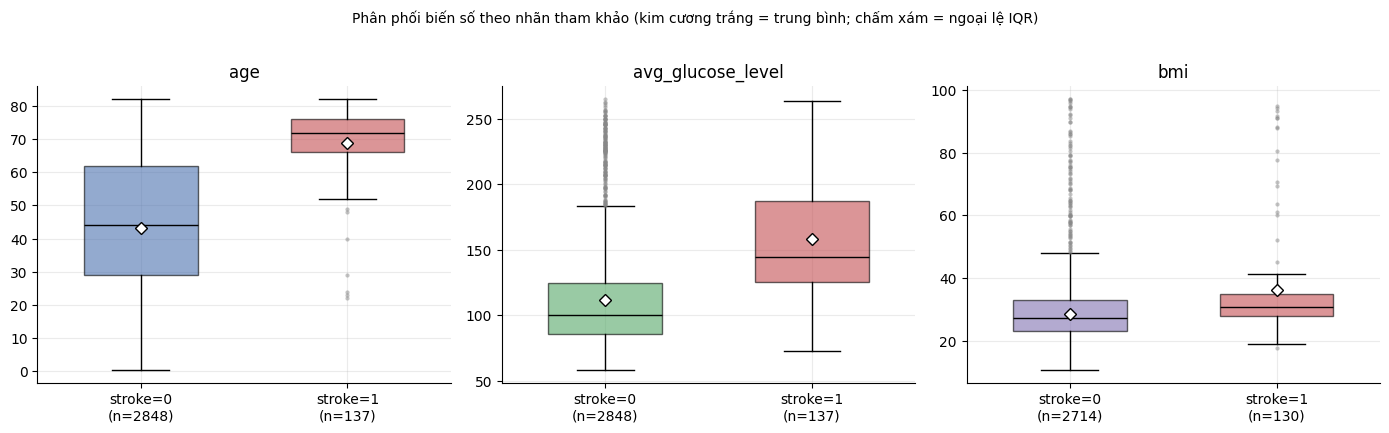

In [42]:
# 6.2b (1) Phân phối ba biến số theo nhãn tham khảo stroke (hộp + điểm trung bình)
num_cols = ["age", "avg_glucose_level", "bmi"]
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
for a, c, col in zip(ax, num_cols, ["#4C72B0", "#55A868", "#8172B2"]):
    groups = [raw.loc[raw["stroke"] == v, c].dropna().to_numpy() for v in (0, 1)]
    bp = a.boxplot(groups, widths=.55, patch_artist=True, showmeans=True,
                   flierprops=dict(marker="o", markersize=3, markerfacecolor="#888", alpha=.5, markeredgecolor="none"),
                   meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=6),
                   medianprops=dict(color="black"))
    for patch, colr in zip(bp["boxes"], [col, "#C44E52"]):
        patch.set_facecolor(colr); patch.set_alpha(.6)
    a.set_xticklabels([f"stroke=0\n(n={len(groups[0])})", f"stroke=1\n(n={len(groups[1])})"]); a.set_title(c)
fig.suptitle("Phân phối biến số theo nhãn tham khảo (kim cương trắng = trung bình; chấm xám = ngoại lệ IQR)", fontsize=10, y=1.02)
plt.tight_layout()

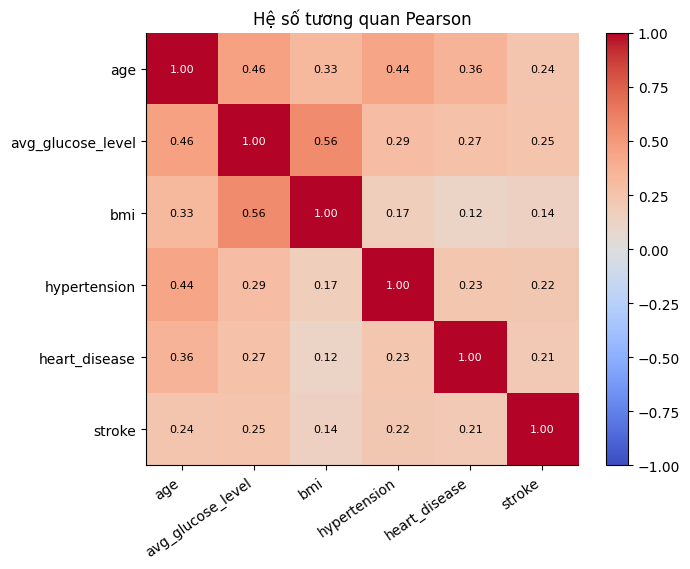

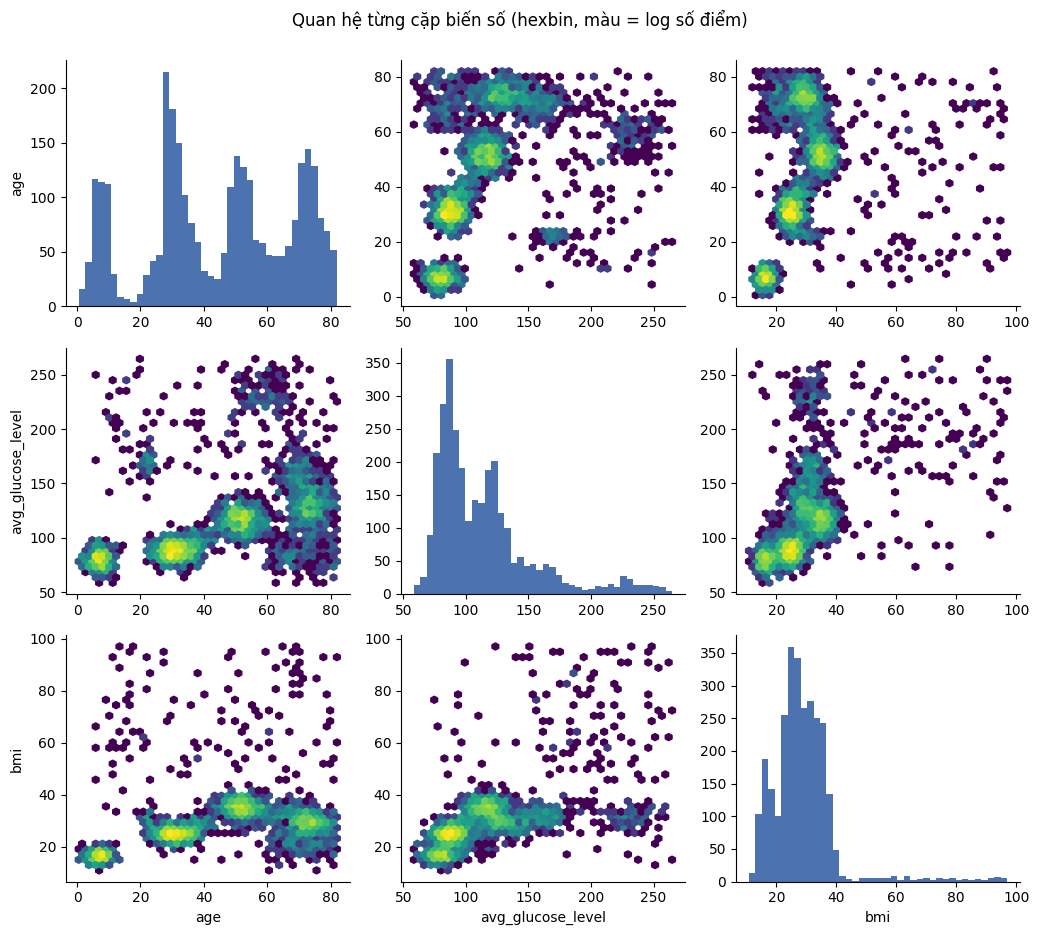

In [43]:
# 6.2b (2) Tương quan Pearson giữa các biến số/nhị phân và ma trận quan hệ từng cặp ba biến số
corr_cols = ["age", "avg_glucose_level", "bmi", "hypertension", "heart_disease", "stroke"]
cm = raw[corr_cols].corr()
fig, ax = plt.subplots(figsize=(7.2, 5.8))
im = ax.imshow(cm.values, cmap="coolwarm", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(corr_cols))); ax.set_xticklabels(corr_cols, rotation=35, ha="right")
ax.set_yticks(range(len(corr_cols))); ax.set_yticklabels(corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{cm.values[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(cm.values[i, j]) > .6 else "black")
ax.set_title("Hệ số tương quan Pearson"); plt.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout()

# Ma trận quan hệ từng cặp: đường chéo = histogram; ngoài đường chéo = hexbin (màu = log số điểm)
fig, axes = plt.subplots(3, 3, figsize=(10.5, 9.3))
for i, ci in enumerate(num_cols):
    for j, cj in enumerate(num_cols):
        a = axes[i, j]
        if i == j:
            a.hist(raw[ci].dropna(), bins=40, color="#4C72B0")
        else:
            d = raw[[cj, ci]].dropna()
            a.hexbin(d[cj], d[ci], gridsize=38, bins="log", cmap="viridis", mincnt=1)
        if i == len(num_cols) - 1: a.set_xlabel(cj)
        if j == 0: a.set_ylabel(ci)
        a.grid(False)
fig.suptitle("Quan hệ từng cặp biến số (hexbin, màu = log số điểm)", y=1.0)
plt.tight_layout()

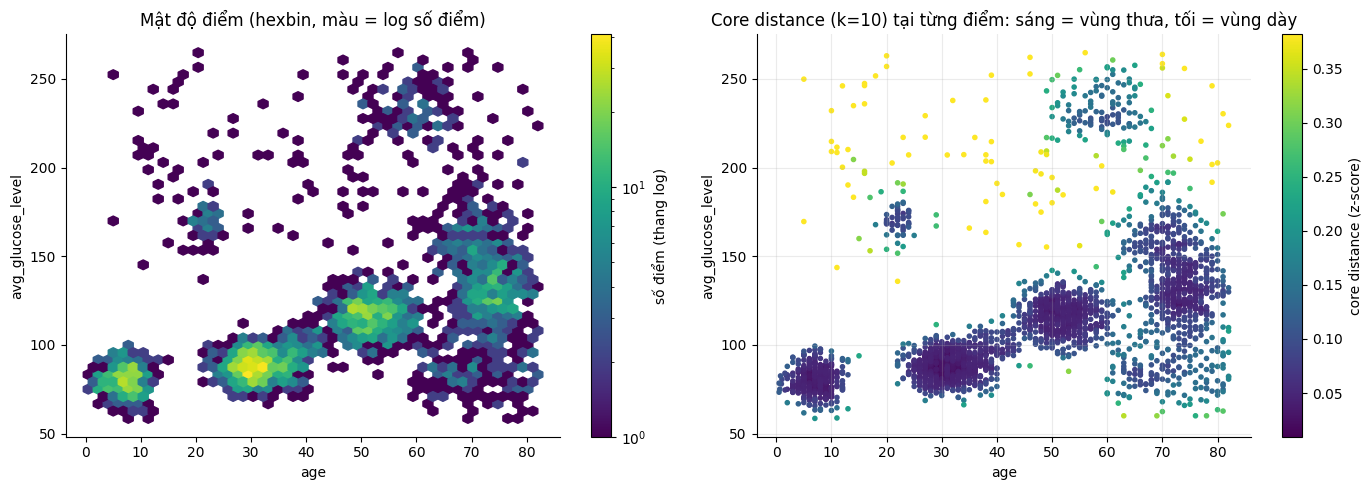

In [44]:
# 6.2b (3) Bản đồ mật độ cục bộ trên hai biến phân cụm (age, avg_glucose_level)
from sklearn.neighbors import NearestNeighbors
_uniq = raw[["age", "avg_glucose_level"]].drop_duplicates().to_numpy(float)
_Z = Preprocessor.zscore(_uniq)
_core = NearestNeighbors(n_neighbors=10).fit(_Z).kneighbors(_Z)[0][:, -1]   # core distance, k = 10, không gian z-score
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
hb = ax[0].hexbin(_uniq[:, 0], _uniq[:, 1], gridsize=45, bins="log", cmap="viridis", mincnt=1)
ax[0].set_xlabel("age"); ax[0].set_ylabel("avg_glucose_level"); ax[0].set_title("Mật độ điểm (hexbin, màu = log số điểm)"); ax[0].grid(False)
plt.colorbar(hb, ax=ax[0], label="số điểm (thang log)")
order = np.argsort(_core)                                   # vẽ điểm thưa sau cùng để nổi bật
sc = ax[1].scatter(_uniq[order, 0], _uniq[order, 1], c=_core[order], s=9, cmap="viridis", vmax=np.percentile(_core, 98))
ax[1].set_xlabel("age"); ax[1].set_ylabel("avg_glucose_level")
ax[1].set_title("Core distance (k=10) tại từng điểm: sáng = vùng thưa, tối = vùng dày")
plt.colorbar(sc, ax=ax[1], label="core distance (z-score)")
plt.tight_layout()

**Mô tả thiết kế dữ liệu tổng hợp.** Hai biểu đồ dưới đây dùng sheet `Thiet_ke_cum` **chỉ để mô tả cách dữ liệu được sinh**
(nhóm lõi C0–C7, cầu nối BR, nhiễu NZ). Nhãn nhóm này **không** được dùng khi fit hoặc chọn tham số; việc đối chiếu kết quả với nhóm thiết kế vẫn chỉ thực hiện sau khi khóa cấu hình, ở 6.10.

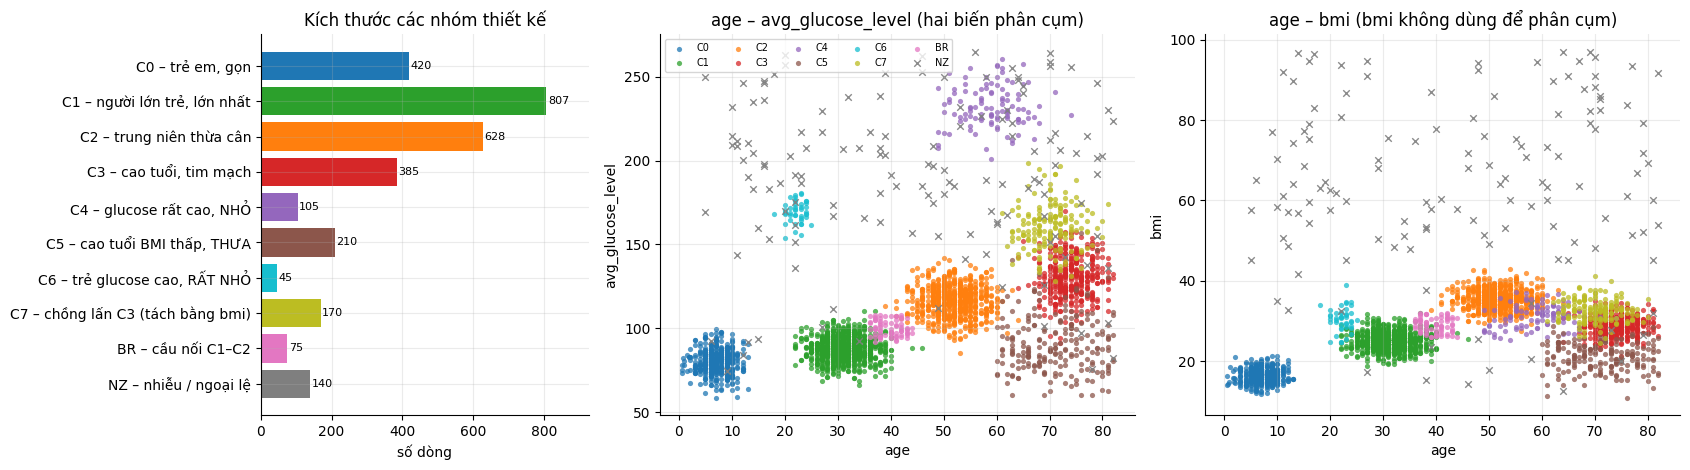

In [45]:
# 6.2b (4) Mô tả thiết kế dữ liệu tổng hợp (chỉ để minh họa; không dùng chọn tham số)
try:
    _design = pd.read_excel(XLSX, sheet_name="Thiet_ke_cum")
    _dd = raw[["id", "age", "avg_glucose_level", "bmi"]].merge(_design, on="id", how="left", validate="one_to_one")
    _grp = ["C0", "C1", "C2", "C3", "C4", "C5", "C6", "C7", "BR", "NZ"]
    _col = {"C0": "#1f77b4", "C1": "#2ca02c", "C2": "#ff7f0e", "C3": "#d62728", "C4": "#9467bd", "C5": "#8c564b", "C6": "#17becf", "C7": "#bcbd22", "BR": "#e377c2", "NZ": "#7f7f7f"}
    _desc = {"C0": "trẻ em, gọn", "C1": "người lớn trẻ, lớn nhất", "C2": "trung niên thừa cân", "C3": "cao tuổi, tim mạch", "C4": "glucose rất cao, NHỎ",
             "C5": "cao tuổi BMI thấp, THƯA", "C6": "trẻ glucose cao, RẤT NHỎ", "C7": "chồng lấn C3 (tách bằng bmi)", "BR": "cầu nối C1–C2", "NZ": "nhiễu / ngoại lệ"}
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw=dict(width_ratios=[.9, 1.3, 1.3]))
    cnt = _dd["profile_thiet_ke"].value_counts().reindex(_grp).fillna(0).astype(int)
    ax[0].barh([f"{g} – {_desc[g]}" for g in _grp][::-1], cnt.values[::-1], color=[_col[g] for g in _grp][::-1])
    for y, v in enumerate(cnt.values[::-1]): ax[0].text(v + 4, y, str(v), va="center", fontsize=8)
    ax[0].set_xlabel("số dòng"); ax[0].set_title("Kích thước các nhóm thiết kế"); ax[0].set_xlim(0, cnt.max() * 1.15)
    for a, (xc, yc, xl, yl) in zip(ax[1:], [("age", "avg_glucose_level", "age", "avg_glucose_level"), ("age", "bmi", "age", "bmi")]):
        for g in _grp:
            m = (_dd["profile_thiet_ke"] == g).to_numpy()
            a.scatter(_dd.loc[m, xc], _dd.loc[m, yc], s=14 if g != "NZ" else 22, marker="x" if g == "NZ" else "o",
                      color=_col[g], alpha=.75 if g != "NZ" else .9, label=g, linewidths=1 if g == "NZ" else 0)
        a.set_xlabel(xl); a.set_ylabel(yl)
    ax[1].set_title("age – avg_glucose_level (hai biến phân cụm)"); ax[2].set_title("age – bmi (bmi không dùng để phân cụm)")
    ax[1].legend(ncol=5, fontsize=7, loc="upper left")
    plt.tight_layout()
except Exception as exc:
    print("Không vẽ được biểu đồ thiết kế dữ liệu:", exc)

### 6.3. Tiền xử lý và phân đoạn dữ liệu
* **Biến phân cụm giữ nguyên:** `age`, `avg_glucose_level`. Dataset mới không thiếu hai biến này.
  Chỉ loại dòng thiếu biến thực sự đưa vào mô hình. `bmi` thiếu vẫn được giữ ở thực nghiệm chính
  vì không dùng BMI để phân cụm. Riêng hình PCA ba biến ở 6.2 vẫn bỏ dòng thiếu BMI trong phạm vi hình đó.
* **Chuẩn hóa giữ nguyên:** z-score với ddof = 0, tính trên chính tập đang phân cụm.
  Đây là đánh giá phân cụm độc lập trên hai tập điểm; không phải dự đoán cho điểm mới bằng mô hình đã fit trên tập phát triển.
* **Dữ liệu trùng:** loại dòng trùng trên cặp biến phân cụm **trên toàn bộ dữ liệu**,
  trước khi tách phát triển/đánh giá. Bảng ở 6.2 phân biệt trùng toàn bộ thuộc tính (trừ id)
  với trùng hai biến đầu vào. Việc loại trùng làm thay đổi mật độ và có thể bỏ các quan sát có thuộc tính khác nhau;
  đây là lựa chọn tiền xử lý của thí nghiệm, không phải yêu cầu bắt buộc của HDBSCAN.
* **Ngoại lệ giữ nguyên:** không tự động loại ngoại lệ theo IQR. Dữ liệu được thiết kế có nhóm thưa,
  nhóm nhỏ, điểm cầu và nhiễu; loại chúng trước sẽ thay đổi bài toán phân cụm.
* **Cỡ dữ liệu thực nghiệm: dùng toàn bộ.** Các ma trận D, S, T, C có bộ nhớ O(n²), nhưng benchmark ở 6.10 cho thấy
  với n ≈ 1.800 một lần HDBSCAN tự cài chỉ tốn vài phần mười giây và khoảng 130 MB, nên không cần khống chế n xuống 500.
  Việc lấy mẫu con chỉ làm mất cụm nhỏ (các nhóm nhỏ C4 và C6 chỉ có 105 và 45 dòng ở nguồn). Nếu cần lấy mẫu con, đặt `N_SAMPLE` là một số nguyên:
  khi đó lấy phân tầng theo `stroke` (không dùng `profile_thiet_ke`).
* **Chia dữ liệu giữ nguyên:** 70% phát triển, 30% đánh giá, seed 42, phân tầng theo `stroke`.
  Chọn cấu hình trên tập phát triển rồi khóa trước khi phân cụm tập đánh giá độc lập.

**Tên tập dữ liệu.** Trong code, tập thực nghiệm chính được đặt tên `DATA` (không dùng `D2`) để không nhầm với tập D2 gồm 500 bệnh nhân thật
của Chương 2, vốn chỉ dùng để minh họa lý thuyết. Nếu báo cáo Chương 1–4 còn ghi dữ liệu bệnh nhân thật, "toàn bộ quan sát của tập gốc" hoặc 500 quan sát,
cần cập nhật mô tả thực nghiệm cho khớp; bộ điểm tính tay D1 vẫn giữ riêng.


In [46]:
# N_SAMPLE = None: dùng TOÀN BỘ dữ liệu sau khi loại trùng. Đặt một số nguyên (ví dụ 1000) chỉ khi cần lấy mẫu con.
N_SAMPLE, SEED_DATA = None, 42
rng = np.random.default_rng(SEED_DATA)
# Chỉ xét giá trị thiếu trên hai biến thực sự dùng cho phân cụm; giữ các dòng thiếu BMI.
pool = raw.dropna(subset=FEAT).reset_index(drop=True)
if not np.isfinite(pool[FEAT].to_numpy(float)).all():
    raise ValueError("Hai biến phân cụm chứa giá trị vô hạn.")
PROP_STROKE = float(pool["stroke"].mean())

# Loại trùng trên cặp biến phân cụm TRƯỚC khi tách tập (điểm trùng làm khoảng cách bằng 0, mục 2.4.2).
n_dup = Preprocessor.duplicate_report(pool, FEAT)
pool = pool.drop_duplicates(subset=FEAT).reset_index(drop=True)

USE_ALL = N_SAMPLE is None or N_SAMPLE >= len(pool)
if USE_ALL:
    DATA = pool.copy()                                  # dùng toàn bộ
else:
    n1 = int(round(pool["stroke"].mean() * N_SAMPLE))   # lấy mẫu phân tầng theo stroke, tỷ lệ gần tỷ lệ nguồn
    idx1 = rng.choice(np.where(pool.stroke == 1)[0], n1, replace=False)
    idx0 = rng.choice(np.where(pool.stroke == 0)[0], N_SAMPLE - n1, replace=False)
    DATA = pool.loc[np.sort(np.r_[idx0, idx1])].reset_index(drop=True)
N_USED = len(DATA)
DATA.to_csv(f"synthetic_stroke_{N_USED}_HDBSCAN.csv", index=False)
print(f"Nguồn: {len(raw)} dòng; đủ hai biến đầu vào: {int(raw[FEAT].notna().all(axis=1).sum())}; loại trùng hai biến: {n_dup}; "
      f"dùng cho thực nghiệm: {N_USED} ({'toàn bộ' if USE_ALL else 'mẫu con'}).")
print(f"stroke=1 ở nguồn: {PROP_STROKE:.3%}; ở DATA: {DATA.stroke.mean():.3%} (không tái cân bằng lớp).")
print(f"Thiếu trên biến phân cụm: {int(DATA[FEAT].isna().sum().sum())}; thiếu BMI được giữ: {int(DATA.bmi.isna().sum())}.")

dev_idx, ev_idx = Preprocessor.stratified_split(DATA["stroke"].values, 0.7, seed=SEED_DATA)
assert len(np.intersect1d(dev_idx, ev_idx)) == 0
DEV, EVAL = DATA.iloc[dev_idx].reset_index(drop=True), DATA.iloc[ev_idx].reset_index(drop=True)
X_dev, X_ev = Preprocessor.zscore(DEV[FEAT].to_numpy(float)), Preprocessor.zscore(EVAL[FEAT].to_numpy(float))
y_dev, y_ev = DEV.stroke.to_numpy(), EVAL.stroke.to_numpy()
assert set(DEV.id).isdisjoint(set(EVAL.id))
assert np.isfinite(X_dev).all() and np.isfinite(X_ev).all()
print(f"Tập phát triển: {len(DEV)} dòng (stroke=1: {y_dev.mean():.3f}); tập đánh giá: {len(EVAL)} dòng (stroke=1: {y_ev.mean():.3f}); hai tập rời nhau.")

Nguồn: 2985 dòng; đủ hai biến đầu vào: 2985; loại trùng hai biến: 40; dùng cho thực nghiệm: 2945 (toàn bộ).
stroke=1 ở nguồn: 4.590%; ở DATA: 4.652% (không tái cân bằng lớp).
Thiếu trên biến phân cụm: 0; thiếu BMI được giữ: 140.
Tập phát triển: 2062 dòng (stroke=1: 0.047); tập đánh giá: 883 dòng (stroke=1: 0.046); hai tập rời nhau.


### 6.4. Thiết lập thực nghiệm

In [47]:
import sys, platform, sklearn, scipy
SETUP = dict(python=sys.version.split()[0], numpy=np.__version__, pandas=pd.__version__, scipy=scipy.__version__,
             sklearn_dung_cho_chi_so=sklearn.__version__, hdbscan=HDBSCAN_LIBRARY_VERSION, thu_vien_doi_chieu=LIB_ENGINE, may=platform.processor() or platform.machine(),
             seed_du_lieu=SEED_DATA, seed_bagging_chinh=0, B_chinh=30, so_seed_lap=10)
display(pd.Series(SETUP, name="giá trị").to_frame())
B_MAIN, SEEDS = 30, list(range(10))
runner = ExperimentRunner()

,giá trị
python,3.13.7
numpy,2.4.4
pandas,3.0.3
scipy,1.17.1
sklearn_dung_cho_chi_so,1.8.0
hdbscan,0.8.44
thu_vien_doi_chieu,hdbscan 0.8.44
may,"Intel64 Family 6 Model 141 Stepping 1, Genuine..."
seed_du_lieu,42
seed_bagging_chinh,0


### 6.5. Chọn tham số trên tập phát triển
**Lưới công khai.** HDBSCAN: `min_cluster_size` ∈ {3, 5, 10, 20, 40, 60}, `min_samples` ∈ {2, 5, 10, 15, 25} (có cấu hình chung (3, 2) của Chương 2–4). Bagging (với cấu hình cơ sở đã khóa): kiểu lấy mẫu ∈ {bootstrap ρ=1, không hoàn lại ρ=0,8} × hiệu chỉnh (4.3) ∈ {không, có} × θ ∈ {0,5; 0,6; 0,7; 0,8} × T_min ∈ {2, 5, 8}, B = 30, c_min = min_cluster_size đã khóa.

**Tiêu chí chọn** (không dùng nhãn `stroke` hoặc `profile_thiet_ke`): cực đại DBCV (chính sách phạt nhiễu) trong các cấu hình có 2 ≤ số cụm ≤ 10 và tỷ lệ nhiễu ≤ 25%. Hai ràng buộc ngăn việc chọn cấu hình chia vụn (như cấu hình A ở 2.5.2) hoặc "đẹp giả tạo" nhờ bỏ nhiều điểm (2.5.2, 2.5.4). Cả hai phương pháp dùng **cùng tiêu chí** và ngân sách tìm kiếm tương đương (30 cấu hình HDBSCAN; 48 cấu hình tổng hợp Bagging).

**Lưu ý khi đọc lưới.** Với `min_samples` rất nhỏ (như 2), kết quả rất nhạy với `min_cluster_size` (có thể chia vụn thành hàng chục cụm). Hãy xem bảng và heatmap trước khi chấp nhận cấu hình được khóa, và nhớ rằng `min_cluster_size` lớn hơn số điểm của cụm nhỏ nhất (nhóm C4) sẽ làm cụm đó không thể xuất hiện.


Cấu hình HDBSCAN được khóa: min_cluster_size=3, min_samples=15  (DBCV phạt nhiễu = 0.597, k=7, nhiễu=16.0%)


,mcs,ms,n_clusters,noise_ratio,sil_drop,sil_merge,dbcv_penalize,dbcv_drop
0,3,2,346,0.173,0.490,0.244,0.394,0.476
1,3,5,110,0.366,0.489,-0.017,0.369,0.582
2,3,10,4,0.028,0.378,0.352,0.260,0.267
3,3,15,7,0.160,0.670,0.461,0.597,0.711
4,3,25,7,0.150,0.668,0.473,0.578,0.680
5,5,2,164,0.219,0.331,0.059,0.228,0.292
6,5,5,82,0.318,0.404,-0.000,0.311,0.456
7,5,10,9,0.215,0.567,0.296,0.428,0.545
8,5,15,7,0.160,0.670,0.461,0.597,0.711
9,5,25,7,0.150,0.668,0.473,0.578,0.680


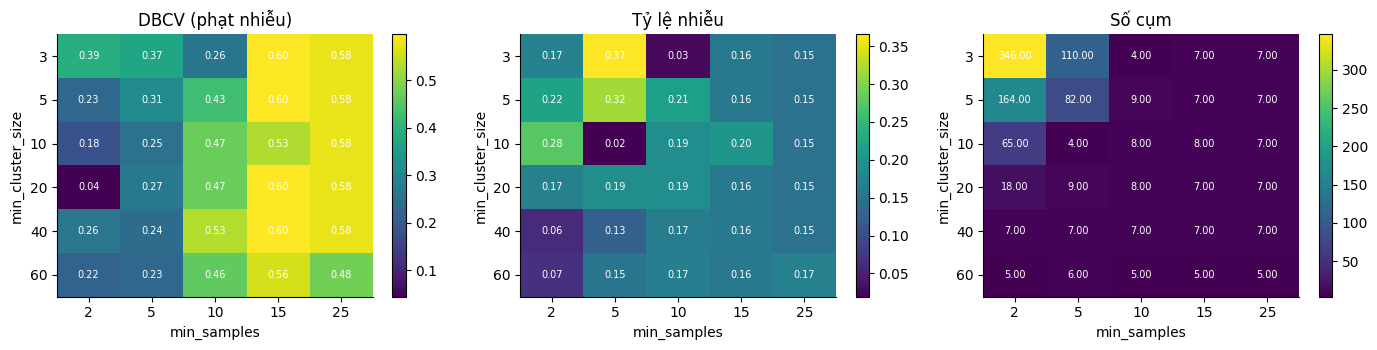

In [48]:
MCS_GRID, MS_GRID = [3, 5, 10, 20, 40, 60], [2, 5, 10, 15, 25]
rows = []
for mcs in MCS_GRID:
    for ms in MS_GRID:
        lab = HDBSCANScratch(mcs, ms).fit_predict(X_dev)
        rows.append(dict(mcs=mcs, ms=ms, **EV.report(X_dev, lab, y_dev)))
grid_single = pd.DataFrame(rows)
ok = grid_single[(grid_single.n_clusters.between(2, 10)) & (grid_single.noise_ratio <= 0.25) & grid_single.dbcv_penalize.notna()]
best = ok.sort_values("dbcv_penalize", ascending=False).iloc[0]
MCS_LOCK, MS_LOCK = int(best.mcs), int(best.ms)
print(f"Cấu hình HDBSCAN được khóa: min_cluster_size={MCS_LOCK}, min_samples={MS_LOCK}  (DBCV phạt nhiễu = {best.dbcv_penalize:.3f}, k={int(best.n_clusters)}, nhiễu={best.noise_ratio:.1%})")
cols = ["mcs", "ms", "n_clusters", "noise_ratio", "sil_drop", "sil_merge", "dbcv_penalize", "dbcv_drop"]
display(grid_single[cols].round(3))
piv = grid_single.pivot(index="mcs", columns="ms", values="dbcv_penalize")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, (v, t) in zip(ax, [("dbcv_penalize", "DBCV (phạt nhiễu)"), ("noise_ratio", "Tỷ lệ nhiễu"), ("n_clusters", "Số cụm")]):
    pv = grid_single.pivot(index="mcs", columns="ms", values=v); im = a.imshow(pv.values, cmap="viridis", aspect="auto")
    a.set_xticks(range(len(pv.columns))); a.set_xticklabels(pv.columns); a.set_yticks(range(len(pv.index))); a.set_yticklabels(pv.index)
    a.set_xlabel("min_samples"); a.set_ylabel("min_cluster_size"); a.set_title(t); a.grid(False); plt.colorbar(im, ax=a)
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            if np.isfinite(pv.values[i, j]): a.text(j, i, f"{pv.values[i,j]:.2f}", ha="center", va="center", color="w", fontsize=7)
plt.tight_layout()

In [49]:
# Lưới Bagging trên tập phát triển: với mỗi (kiểu lấy mẫu, hiệu chỉnh) chạy B lượt một lần, rồi thử mọi (θ, T_min)
THETAS, TMINS = [0.5, 0.6, 0.7, 0.8], [2, 5, 8]
SAMPLINGS = {"bootstrap ρ=1": dict(sampling="bootstrap", rho=1.0), "không hoàn lại ρ=0,8": dict(sampling="subsample", rho=0.8)}
rows, store_dev = [], {}
for sname, sp in SAMPLINGS.items():
    for adj in (False, True):
        bag = BaggedHDBSCANScratch(MCS_LOCK, MS_LOCK, B=B_MAIN, seed=0, adjust=adj, c_min=MCS_LOCK, **sp).fit_rounds(X_dev)
        store_dev[(sname, adj)] = bag
        for th in THETAS:
            for tm in TMINS:
                lab = bag.aggregate(theta=th, t_min=tm, c_min=MCS_LOCK)
                rows.append(dict(sampling=sname, adjust=adj, theta=th, t_min=tm, pair_cov=bag.builder_.pair_coverage(tm), **EV.report(X_dev, lab, y_dev)))
grid_bag = pd.DataFrame(rows)
okb = grid_bag[(grid_bag.n_clusters.between(2, 10)) & (grid_bag.noise_ratio <= 0.25) & grid_bag.dbcv_penalize.notna()]
print(f"{len(grid_bag)} cấu hình Bagging; {len(okb)} thỏa ràng buộc.")
best_by_sampling = {}
for sname in SAMPLINGS:
    sub = okb[okb.sampling == sname]
    if len(sub):
        best_by_sampling[sname] = sub.sort_values("dbcv_penalize", ascending=False).iloc[0]
display(pd.DataFrame(best_by_sampling).T[["adjust", "theta", "t_min", "n_clusters", "noise_ratio", "pair_cov", "dbcv_penalize", "sil_drop"]])

48 cấu hình Bagging; 48 thỏa ràng buộc.


,adjust,theta,t_min,n_clusters,noise_ratio,pair_cov,dbcv_penalize,sil_drop
bootstrap ρ=1,False,0.8,5,7,0.173618,0.998182,0.596635,0.683744
"không hoàn lại ρ=0,8",True,0.6,5,7,0.190592,1.0,0.603615,0.689538


In [50]:
BAG_LOCK = {s: dict(adjust=bool(r.adjust), theta=float(r.theta), t_min=int(r.t_min)) for s, r in best_by_sampling.items()}
print("Cấu hình Bagging được khóa:", BAG_LOCK)
display(grid_bag.groupby(["sampling", "adjust"])[["n_clusters", "noise_ratio", "dbcv_penalize"]].agg(["min", "median", "max"]).round(3))

Cấu hình Bagging được khóa: {'bootstrap ρ=1': {'adjust': False, 'theta': 0.8, 't_min': 5}, 'không hoàn lại ρ=0,8': {'adjust': True, 'theta': 0.6, 't_min': 5}}


n_clusters            noise_ratio                \
                                   min median max         min median    max   
sampling             adjust                                                   
bootstrap ρ=1        False           6    7.0   7       0.128  0.147  0.181   
                     True            4    6.0   6       0.085  0.134  0.184   
không hoàn lại ρ=0,8 False           7    7.0   8       0.156  0.184  0.212   
                     True            7    7.0   8       0.170  0.202  0.237   

                            dbcv_penalize                
                                      min median    max  
sampling             adjust                              
bootstrap ρ=1        False          0.473  0.580  0.597  
                     True           0.266  0.401  0.470  
không hoàn lại ρ=0,8 False          0.533  0.578  0.585  
                     True           0.528  0.597  0.604

### 6.6. HDBSCAN tự viết so với thư viện
Dùng gói `hdbscan` với `algorithm="generic"`, EOM, epsilon=0, root bị loại. Cùng MCS; MS được quy đổi theo cách đếm chính điểm, bảng bên dưới ghi cả hai giá trị. Đối chiếu: nhãn cuối (ARI, mặt nạ nhiễu), các bước trung gian, thời gian và bộ nhớ. Đối chiếu thực hiện trên **toàn bộ 30 cấu hình của lưới** (tập phát triển) và trên tập đánh giá.

In [51]:
rows = []
for mcs in MCS_GRID:
    for ms in MS_GRID:
        hs = HDBSCANScratch(mcs, ms).fit(X_dev); lb = HDBSCANLibraryAdapter(mcs, ms).fit(X_dev)
        a, b = hs.labels_, lb.labels_
        h2 = HDBSCANScratch(mcs, ms).fit_from_hierarchy(lb.hierarchy_, len(X_dev))     # cùng cây single linkage của thư viện
        nm = EV.noise_mask_agreement(a, b)
        rows.append(dict(mcs=mcs, ms=ms, ms_hdbscan=lb.min_samples_library_, ari_dau_cuoi=EV.ari_manual(a, b), mask_agree=nm["agreement"],
                         ari_cung_cay_SL=EV.ari_manual(h2.labels_, b), k_scratch=len(set(a) - {-1}), k_lib=len(set(b) - {-1}),
                         ty_le_cap_dong_trong_so=ImplementationTests.tied_merge_fraction(hs.hierarchy_)))
cmp_grid = pd.DataFrame(rows)
nG = len(cmp_grid)
print(f"{nG} cấu hình trên tập phát triển:")
print(f"  • Đầu–cuối (tự cài → nhãn): ARI = 1 ở {(np.isclose(cmp_grid.ari_dau_cuoi, 1)).sum()}/{nG} cấu hình; ARI tối thiểu = {cmp_grid.ari_dau_cuoi.min():.4f}; trung vị = {cmp_grid.ari_dau_cuoi.median():.4f}")
print(f"  • Các bước 3.3.6–3.3.8 trên CÙNG cây single linkage của thư viện: ARI = 1 ở {(np.isclose(cmp_grid.ari_cung_cay_SL, 1)).sum()}/{nG} cấu hình")
print("Nếu có sai khác đầu–cuối, kiểm tra đồng thời ARI, mặt nạ nhiễu và kết quả trên cùng cây single linkage.")
print("Cạnh đồng trọng số là một yếu tố cần khảo sát; tỷ lệ cạnh bằng nhau không tự chứng minh nguyên nhân của mọi sai khác.")
display(cmp_grid[cmp_grid.ari_dau_cuoi < 1 - 1e-9].round(4) if (cmp_grid.ari_dau_cuoi < 1 - 1e-9).any() else pd.DataFrame({"kết luận": ["mọi cấu hình đều trùng hoàn toàn"]}))

T6 = ImplementationTests()
for nm_, Xc in [("tập phát triển", X_dev), ("tập đánh giá", X_ev)]:
    T6.intermediate_steps(Xc, MCS_LOCK, MS_LOCK)
res = T6.summary(); res["Tập"] = ["phát triển"] * (len(res) // 2) + ["đánh giá"] * (len(res) - len(res) // 2)
display(res)

30 cấu hình trên tập phát triển:
  • Đầu–cuối (tự cài → nhãn): ARI = 1 ở 3/30 cấu hình; ARI tối thiểu = 0.9561; trung vị = 0.9977
  • Các bước 3.3.6–3.3.8 trên CÙNG cây single linkage của thư viện: ARI = 1 ở 30/30 cấu hình
Nếu có sai khác đầu–cuối, kiểm tra đồng thời ARI, mặt nạ nhiễu và kết quả trên cùng cây single linkage.
Cạnh đồng trọng số là một yếu tố cần khảo sát; tỷ lệ cạnh bằng nhau không tự chứng minh nguyên nhân của mọi sai khác.


,mcs,ms,ms_hdbscan,ari_dau_cuoi,mask_agree,ari_cung_cay_SL,k_scratch,k_lib,ty_le_cap_dong_trong_so
0,3,2,1,0.9918,0.9985,1.0,346,346,0.7078
1,3,5,4,0.9561,0.9840,1.0,110,111,0.5976
2,3,10,9,0.9997,0.9990,1.0,4,4,0.4738
3,3,15,14,0.9967,0.9990,1.0,7,7,0.3956
4,3,25,24,0.9990,0.9995,1.0,7,7,0.2908
5,5,2,1,0.9979,0.9995,1.0,164,164,0.7078
6,5,5,4,0.9665,0.9879,1.0,82,82,0.5976
7,5,10,9,0.9979,0.9990,1.0,9,9,0.4738
8,5,15,14,0.9967,0.9990,1.0,7,7,0.3956
9,5,25,24,0.9990,0.9995,1.0,7,7,0.2908


,Kiểm chứng,Đạt,Ghi chú,Tập
0,3.3.1 ma trận khoảng cách = scipy cdist,ĐẠT,,phát triển
1,"3.3.2 core distance = k-NN (k=min_samples, có ...",ĐẠT,,phát triển
2,3.3.3 mutual reachability,ĐẠT,,phát triển
3,3.3.4 tổng trọng số MST (Prim) = scipy,ĐẠT,248.658760 vs 248.658760,phát triển
4,3.3.5 các độ cao single linkage = scipy,ĐẠT,,phát triển
5,Adapter dùng gói hdbscan và quy đổi đúng min_s...,ĐẠT,MS_tự_cài=15; MS_hdbscan=14,phát triển
6,"3.3.6–3.3.8 (cây của thư viện → cô đọng, EOM, ...",ĐẠT,ARI=1.0000,phát triển
7,3.3.8 mặt nạ nhiễu trùng hoàn toàn (cùng cây s...,ĐẠT,,phát triển
8,"Đầu–cuối: ARI(tự cài, thư viện) ≥ 0,9",ĐẠT,ARI=0.9967; 40% số bước gộp có độ cao trùng vớ...,phát triển
9,3.3.1 ma trận khoảng cách = scipy cdist,ĐẠT,,đánh giá


In [52]:
# Thời gian và bộ nhớ (cấu hình đã khóa), lặp 5 lần lấy trung vị
def bench(make, X, reps=5):
    ts, ms_ = [], []
    for _ in range(reps):
        _, dt, mem = EV.measure(lambda: make().fit_predict(X)); ts.append(dt); ms_.append(mem)
    return float(np.median(ts)), float(np.median(ms_))
rows = []
for nm_, Xc in [("phát triển (n=%d)" % len(X_dev), X_dev), ("đánh giá (n=%d)" % len(X_ev), X_ev)]:
    for who, mk in [("Tự cài đặt", lambda: HDBSCANScratch(MCS_LOCK, MS_LOCK)), ("Thư viện", lambda: HDBSCANLibraryAdapter(MCS_LOCK, MS_LOCK))]:
        t, m = bench(mk, Xc); rows.append(dict(tap=nm_, ban=who, thoi_gian_ms=t * 1e3, bo_nho_dinh_MB=m))
display(pd.DataFrame(rows).round(3))

,tap,ban,thoi_gian_ms,bo_nho_dinh_MB
0,phát triển (n=2062),Tự cài đặt,415.405,170.075
1,phát triển (n=2062),Thư viện,384.293,68.120
2,đánh giá (n=883),Tự cài đặt,139.006,31.189
3,đánh giá (n=883),Thư viện,129.191,12.561


### 6.7. Kiểm chứng quy trình Bagging
Cùng một danh sách mẫu bootstrap được đưa qua HDBSCAN tự cài và HDBSCAN thư viện; bước tổng hợp giữ nguyên. So sánh nhãn từng lượt, S, T, C và kết quả cuối.

In [53]:
def brute_force_ST(round_labels):
    """Tính S, T bằng hai vòng lặp thuần Python đúng công thức (4.7), (4.8) – độc lập với CoAssociationBuilder."""
    B, n = round_labels.shape; S = np.zeros((n, n), int); T = np.zeros((n, n), int)
    for b in range(B):
        y = round_labels[b]
        for i in range(n):
            if y[i] == UNOBS: continue
            for j in range(n):
                if y[j] == UNOBS: continue
                T[i, j] += 1
                if y[i] == y[j] and y[i] != NOISE: S[i, j] += 1
    return S, T

def components_scipy(S, T, theta, t_min, c_min):
    """Đồ thị ngưỡng + thành phần liên thông bằng scipy (độc lập với UnionFind) rồi áp quy tắc c_min (định nghĩa 4.8)."""
    from scipy.sparse.csgraph import connected_components
    C = np.divide(S, T, out=np.zeros(S.shape), where=T > 0); A = (T >= t_min) & (C >= theta - 1e-12); np.fill_diagonal(A, False)
    _, comp = connected_components(A, directed=False)
    sizes = np.bincount(comp); first = {}
    for i, c in enumerate(comp): first.setdefault(c, i)
    y = np.full(len(comp), -1); k = 0
    for c in sorted(first, key=first.get):
        if sizes[c] >= c_min: y[comp == c] = k; k += 1
    return y

rows = []
for nm_, Xc in [("phát triển", X_dev), ("đánh giá", X_ev)]:
    for sname, sp in SAMPLINGS.items():
        lock = BAG_LOCK.get(sname)
        if lock is None:
            continue
        kw = dict(base_min_cluster_size=MCS_LOCK, base_min_samples=MS_LOCK, B=B_MAIN, seed=0, c_min=MCS_LOCK, **lock, **sp)
        a = BaggedHDBSCANScratch(engine="scratch", **kw).fit(Xc)
        b = BaggedHDBSCANScratch(engine="library", **kw).fit(Xc, samples=a.samples_)      # CÙNG danh sách mẫu
        # Vòng lặp thuần Python có chi phí O(B·m²): với n ≈ 1.000+ điểm thì rất chậm, nên đối chiếu trên m điểm lấy ngẫu nhiên (khối con của S, T chỉ phụ thuộc nhãn của các điểm đó).
        sub = np.sort(np.random.default_rng(0).choice(len(Xc), min(len(Xc), 300), replace=False))
        Sb, Tb = brute_force_ST(a.round_labels_[:, sub])
        # ARI từng lượt giữa bản tự cài và bản thư viện trên các điểm cùng được quan sát
        per_round = []
        for r in range(B_MAIN):
            m = a.round_labels_[r] != UNOBS
            per_round.append(EV.ari_manual(a.round_labels_[r][m], b.round_labels_[r][m]))
        rows.append(dict(tap=nm_, kieu_lay_mau=sname,
                         T_tu_cai_bang_thu_vien=bool((a.T_ == b.T_).all()),
                         S_T_bang_vong_lap_thuan=bool((a.S_[np.ix_(sub, sub)] == Sb).all() and (a.T_[np.ix_(sub, sub)] == Tb).all()),
                         nhan_threshold_bang_scipy=bool((a.labels_ == components_scipy(a.S_, a.T_, lock["theta"], lock["t_min"], MCS_LOCK)).all()),
                         luot_trung_nhan=int(np.sum(np.isclose(per_round, 1.0))), ARI_luot_TB=float(np.mean(per_round)), ARI_luot_min=float(np.min(per_round)),
                         ARI_ket_qua_cuoi=EV.ari_manual(a.labels_, b.labels_), t_scratch_s=a.fit_rounds_time_, t_lib_s=b.fit_rounds_time_))
verify_bag = pd.DataFrame(rows); display(verify_bag.round(4))
print("Giải thích: T chỉ phụ thuộc danh sách mẫu nên bằng nhau tuyệt đối; S, T của CoAssociationBuilder trùng với phép đếm vòng lặp thuần theo (4.7)–(4.8) (kiểm trên 300 điểm ngẫu nhiên mỗi tập để giữ thời gian chạy);")
print("nhãn đồng thuận bằng đồ thị ngưỡng trùng thành phần liên thông của scipy. Nhãn từng lượt của hai engine có thể lệch nhẹ ở các lượt có cạnh đồng trọng số (xem 6.6),")
print("nên S và nhãn cuối của hai engine được so bằng ARI (không đòi hỏi trùng tuyệt đối).")

,tap,kieu_lay_mau,T_tu_cai_bang_thu_vien,S_T_bang_vong_lap_thuan,nhan_threshold_bang_scipy,luot_trung_nhan,ARI_luot_TB,ARI_luot_min,ARI_ket_qua_cuoi,t_scratch_s,t_lib_s
0,phát triển,bootstrap ρ=1,True,True,True,2,0.9879,0.8826,0.9801,4.3825,2.4649
1,phát triển,"không hoàn lại ρ=0,8",True,True,True,0,0.9515,0.7726,0.9609,6.9611,4.4324
2,đánh giá,bootstrap ρ=1,True,True,True,1,0.9868,0.7929,1.0000,1.0906,0.6500
3,đánh giá,"không hoàn lại ρ=0,8",True,True,True,0,0.9855,0.8180,0.9987,1.8303,0.9476


Giải thích: T chỉ phụ thuộc danh sách mẫu nên bằng nhau tuyệt đối; S, T của CoAssociationBuilder trùng với phép đếm vòng lặp thuần theo (4.7)–(4.8) (kiểm trên 300 điểm ngẫu nhiên mỗi tập để giữ thời gian chạy);
nhãn đồng thuận bằng đồ thị ngưỡng trùng thành phần liên thông của scipy. Nhãn từng lượt của hai engine có thể lệch nhẹ ở các lượt có cạnh đồng trọng số (xem 6.6),
nên S và nhãn cuối của hai engine được so bằng ARI (không đòi hỏi trùng tuyệt đối).


### 6.8. HDBSCAN đơn lẻ so với Bagging cho HDBSCAN
So trên **cùng các điểm** (tập đánh giá; số dòng thực tế được in trong bảng) và cùng chỉ số. Các phương pháp:
* (a) HDBSCAN chạy một lần với cấu hình đã khóa;
* (b) *ensemble theo tham số*: cùng dữ liệu, 9 cấu hình lân cận quanh cấu hình khóa, tổng hợp bằng chính ma trận đồng phân cụm + đồ thị ngưỡng (θ = 0,5, T_min = 2, c_min = min_cluster_size đã khóa);
* (c) Bagging với hai kiểu lấy mẫu, dùng nguyên cấu hình HDBSCAN cơ sở đã khóa – nên chênh lệch so với (a) là tác động riêng của việc tổ hợp.

**Độ ổn định (giả thuyết H1).** HDBSCAN trên toàn bộ dữ liệu là tất định, nên "đổi seed" không có ý nghĩa với (a). Quy trình công bằng cho mọi phương pháp: lặp 10 lần, mỗi lần lấy ngẫu nhiên 80% số điểm (không hoàn lại), chạy phương pháp trên tập con đó (Bagging dùng seed khác nhau ở mỗi lần), rồi tính ARI trung bình giữa các cặp lần chạy **trên các điểm chung** (2.6.3).


In [54]:
class ParameterEnsembleHDBSCAN:
    """Baseline (b): ensemble theo tham số – mỗi cấu hình (min_cluster_size, min_samples) chạy trên TOÀN BỘ dữ liệu; mọi điểm đều được quan sát
    nên T_ij = số cấu hình; tổng hợp bằng CoAssociationBuilder + ConsensusClusterer như Bagging."""
    def __init__(self, configs, theta=0.5, t_min=2, c_min=3):
        self.configs, self.theta, self.t_min, self.c_min = configs, theta, t_min, c_min
    def fit_predict(self, X):
        n = len(X); cb = CoAssociationBuilder(n)
        for mcs, ms in self.configs:
            cb.update(HDBSCANScratch(mcs, ms).fit_predict(X).astype(np.int64))
        self.builder_ = cb
        return ConsensusClusterer(self.theta, self.t_min, self.c_min, "threshold").fit(cb.S, cb.T)

def neighbour_configs(mcs, ms):
    ms_opts = sorted({max(1, ms // 2), ms, ms * 2}); mcs_opts = sorted({max(2, int(round(mcs * .75))), mcs, int(round(mcs * 1.5))})
    return [(a, b) for a in mcs_opts for b in ms_opts]
PARAM_CONFIGS = neighbour_configs(MCS_LOCK, MS_LOCK)
print("9 cấu hình của ensemble theo tham số:", PARAM_CONFIGS)

def method_factories(seed=0):
    f = {"(a) HDBSCAN đơn lẻ": lambda X: HDBSCANScratch(MCS_LOCK, MS_LOCK).fit_predict(X),
         "(b) Ensemble theo tham số": lambda X: ParameterEnsembleHDBSCAN(PARAM_CONFIGS, 0.5, 2, MCS_LOCK).fit_predict(X)}
    for i, (sname, sp) in enumerate(SAMPLINGS.items()):
        if sname in BAG_LOCK:
            f[f"(c{i+1}) Bagging – {sname}"] = (lambda sname=sname, sp=sp: lambda X: BaggedHDBSCANScratch(
                MCS_LOCK, MS_LOCK, B=B_MAIN, seed=seed, c_min=MCS_LOCK, **BAG_LOCK[sname], **sp).fit_predict(X))()
    return f

def compare_on(X, y, tag):
    rr = ExperimentRunner()
    labs = {}
    for name, fn in method_factories().items():
        labs[name], _ = rr.run(name, fn, X, y, tap=tag)
    return rr.table(), labs

res_ev, labs_ev = compare_on(X_ev, y_ev, "đánh giá")
res_dev, labs_dev = compare_on(X_dev, y_dev, "phát triển")
show = ["method", "n_clusters", "noise_ratio", "coverage", "sil_drop", "sil_merge", "dbcv_penalize", "dbcv_drop", "ari_ref", "time_s", "mem_mb"]
print("TẬP ĐÁNH GIÁ (cấu hình đã khóa, chạy một lần):"); display(res_ev[show].round(3))
print("TẬP PHÁT TRIỂN (tập đã dùng chọn tham số – chỉ để tham khảo):"); display(res_dev[show].round(3))

9 cấu hình của ensemble theo tham số: [(2, 7), (2, 15), (2, 30), (3, 7), (3, 15), (3, 30), (4, 7), (4, 15), (4, 30)]
TẬP ĐÁNH GIÁ (cấu hình đã khóa, chạy một lần):


,method,n_clusters,noise_ratio,coverage,sil_drop,sil_merge,dbcv_penalize,dbcv_drop,ari_ref,time_s,mem_mb
0,(a) HDBSCAN đơn lẻ,6,0.154,0.846,0.677,0.493,0.547,0.646,0.013,0.219,31.190
1,(b) Ensemble theo tham số,6,0.182,0.818,0.698,0.478,0.566,0.692,0.014,3.186,43.670
2,(c1) Bagging – bootstrap ρ=1,5,0.194,0.806,0.691,0.465,0.554,0.687,0.016,5.013,34.068
3,"(c2) Bagging – không hoàn lại ρ=0,8",6,0.152,0.848,0.683,0.506,0.568,0.670,0.015,6.302,34.665


TẬP PHÁT TRIỂN (tập đã dùng chọn tham số – chỉ để tham khảo):


,method,n_clusters,noise_ratio,coverage,sil_drop,sil_merge,dbcv_penalize,dbcv_drop,ari_ref,time_s,mem_mb
0,(a) HDBSCAN đơn lẻ,7,0.160,0.840,0.670,0.461,0.597,0.711,0.009,0.618,170.075
1,(b) Ensemble theo tham số,7,0.162,0.838,0.673,0.461,0.593,0.708,0.009,11.274,238.268
2,(c1) Bagging – bootstrap ρ=1,7,0.174,0.826,0.684,0.458,0.597,0.722,0.009,16.480,177.153
3,"(c2) Bagging – không hoàn lại ρ=0,8",7,0.191,0.809,0.690,0.437,0.604,0.746,0.007,24.262,181.282


In [55]:
# Độ ổn định khi lấy mẫu lại 80% (H1) – trên cả hai tập
def stability_table(X, tag, n_runs=10):
    rows = []
    runner_ = ExperimentRunner()
    for name in method_factories().keys():
        def fac(r, name=name):
            return method_factories(seed=100 + r)[name]
        s, labs, idxs = runner_.stability(fac, X, n_runs=n_runs, frac=0.8, seed=7)
        noise = np.mean([np.mean(l == -1) for l in labs]); kk = np.mean([len(set(l) - {-1}) for l in labs])
        rows.append(dict(tap=tag, method=name, ARI_giua_cac_lan=s, so_cum_TB=kk, ty_le_nhieu_TB=noise))
    return pd.DataFrame(rows)
stab = pd.concat([stability_table(X_ev, "đánh giá"), stability_table(X_dev, "phát triển")], ignore_index=True)
display(stab.round(3))

# Ổn định theo seed của Bagging trên toàn bộ tập (cùng các điểm): ARI giữa các seed khác nhau
rows = []
for X, tag in [(X_ev, "đánh giá"), (X_dev, "phát triển")]:
    for sname, sp in SAMPLINGS.items():
        if sname not in BAG_LOCK: continue
        labs = [BaggedHDBSCANScratch(MCS_LOCK, MS_LOCK, B=B_MAIN, seed=s, c_min=MCS_LOCK, **BAG_LOCK[sname], **sp).fit_predict(X) for s in SEEDS]
        pa = [EV.ari_manual(a, b) for a, b in itertools.combinations(labs, 2)]
        rows.append(dict(tap=tag, kieu=sname, ARI_giua_cac_seed_TB=np.mean(pa), ARI_min=np.min(pa), so_cum_TB=np.mean([len(set(l)-{-1}) for l in labs]), nhieu_TB=np.mean([np.mean(l==-1) for l in labs])))
display(pd.DataFrame(rows).round(3))
print("(HDBSCAN đơn lẻ tất định: ARI giữa các seed = 1 theo định nghĩa, nên không dùng để so sánh – xem bảng độ ổn định theo lấy mẫu lại ở trên.)")

,tap,method,ARI_giua_cac_lan,so_cum_TB,ty_le_nhieu_TB
0,đánh giá,(a) HDBSCAN đơn lẻ,0.892,7.0,0.168
1,đánh giá,(b) Ensemble theo tham số,0.930,6.6,0.160
2,đánh giá,(c1) Bagging – bootstrap ρ=1,0.869,4.9,0.198
3,đánh giá,"(c2) Bagging – không hoàn lại ρ=0,8",0.922,6.2,0.155
4,phát triển,(a) HDBSCAN đơn lẻ,0.839,8.1,0.197
5,phát triển,(b) Ensemble theo tham số,0.901,7.3,0.169
6,phát triển,(c1) Bagging – bootstrap ρ=1,0.919,7.1,0.167
7,phát triển,"(c2) Bagging – không hoàn lại ρ=0,8",0.842,7.4,0.177


,tap,kieu,ARI_giua_cac_seed_TB,ARI_min,so_cum_TB,nhieu_TB
0,đánh giá,bootstrap ρ=1,0.978,0.961,5.1,0.185
1,đánh giá,"không hoàn lại ρ=0,8",0.921,0.683,6.0,0.149
2,phát triển,bootstrap ρ=1,0.946,0.930,7.0,0.164
3,phát triển,"không hoàn lại ρ=0,8",0.946,0.913,7.0,0.175


(HDBSCAN đơn lẻ tất định: ARI giữa các seed = 1 theo định nghĩa, nên không dùng để so sánh – xem bảng độ ổn định theo lấy mẫu lại ở trên.)


### 6.9. Khảo sát độ nhạy và tình huống khó
Thực hiện trên **tập phát triển** (tập đánh giá được giữ nguyên cho kết quả cuối). Với mỗi giá trị tham số: ARI giữa hai seed khác nhau (độ ổn định theo seed), số cụm, tỷ lệ nhiễu, độ bao phủ cặp, DBCV.

Ảnh hưởng của B (bootstrap ρ=1):


,B,n_clusters,noise_ratio,dbcv_penalize,ari_seed,pair_cov,time_s
0,5,7,0.931,0.055,0.027,0.010,0.720
1,10,7,0.304,0.495,0.507,0.353,1.369
2,20,7,0.170,0.590,0.935,0.949,2.689
3,30,7,0.174,0.597,0.945,0.998,4.374
4,50,7,0.186,0.590,0.947,1.000,6.736
5,100,8,0.200,0.532,0.955,1.000,14.913


Ảnh hưởng của ρ và kiểu lấy mẫu:


,rho,kieu,n_clusters,noise_ratio,dbcv_penalize,ari_seed,pair_cov,time_s
0,0.50,bootstrap,7,0.144,0.590,0.946,0.503,1.799
1,0.75,bootstrap,7,0.141,0.578,0.956,0.948,4.228
2,1.00,bootstrap,7,0.174,0.597,0.945,0.998,4.500
3,1.50,bootstrap,7,0.201,0.597,0.948,1.000,6.605
4,0.50,không hoàn lại,7,0.144,0.596,0.958,0.902,2.982
5,0.60,không hoàn lại,7,0.173,0.603,0.943,0.995,4.054
6,0.70,không hoàn lại,7,0.183,0.588,0.939,1.000,5.221
7,0.80,không hoàn lại,8,0.212,0.533,0.941,1.000,6.731
8,0.90,không hoàn lại,7,0.192,0.587,0.935,1.000,8.032


Ảnh hưởng của θ và T_min (B=30):
Số cụm


t_min,1,2,5,8,12
theta,,,,,
0.3,6,6,6,6,7
0.5,6,6,6,6,7
0.6,7,7,7,7,7
0.7,7,7,7,7,7
0.8,7,7,7,7,7
0.9,7,7,7,7,7


Tỷ lệ nhiễu


t_min,1,2,5,8,12
theta,,,,,
0.3,0.113,0.113,0.113,0.117,0.130
0.5,0.127,0.128,0.129,0.131,0.150
0.6,0.136,0.137,0.138,0.142,0.167
0.7,0.152,0.153,0.154,0.160,0.188
0.8,0.173,0.174,0.174,0.181,0.215
0.9,0.207,0.208,0.208,0.214,0.244


DBCV (phạt nhiễu)


t_min,1,2,5,8,12
theta,,,,,
0.3,0.448,0.448,0.447,0.447,0.568
0.5,0.474,0.474,0.474,0.473,0.585
0.6,0.579,0.579,0.578,0.576,0.598
0.7,0.587,0.586,0.586,0.582,0.589
0.8,0.597,0.597,0.597,0.593,0.566
0.9,0.581,0.581,0.580,0.578,0.561


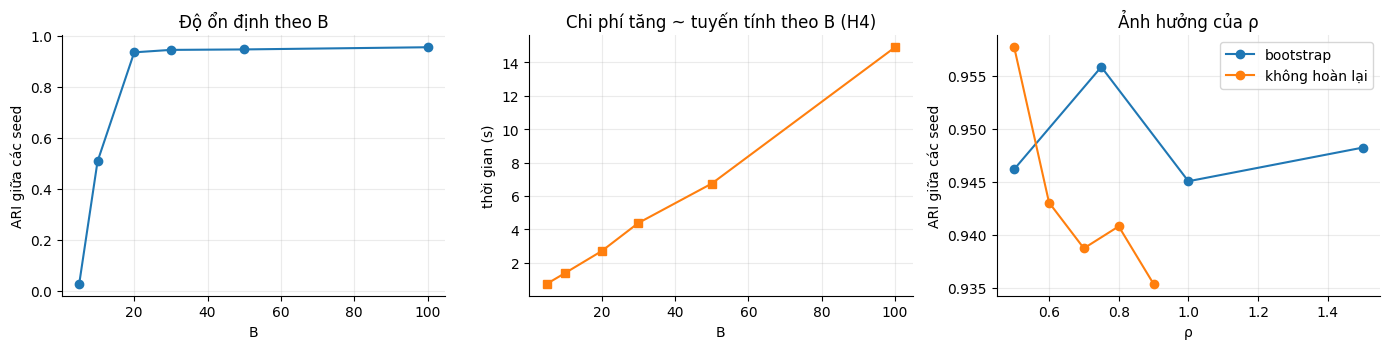

In [56]:
def run_bag(X, seeds=(0, 1, 2), **kw):
    kw = {**dict(base_min_cluster_size=MCS_LOCK, base_min_samples=MS_LOCK, B=B_MAIN, c_min=MCS_LOCK, theta=.5, t_min=2, sampling="bootstrap", rho=1.0), **kw}
    bags = [BaggedHDBSCANScratch(seed=s, **kw).fit(X) for s in seeds]
    labs = [b.labels_ for b in bags]; pa = [EV.ari_manual(a, b) for a, b in itertools.combinations(labs, 2)]
    r = EV.report(X, labs[0]); r.update(ari_seed=float(np.mean(pa)), pair_cov=bags[0].builder_.pair_coverage(kw["t_min"]), time_s=bags[0].fit_rounds_time_)
    return r
BASE = BAG_LOCK.get("bootstrap ρ=1", next(iter(BAG_LOCK.values())))
base_kw = dict(theta=BASE["theta"], t_min=BASE["t_min"], adjust=BASE["adjust"])
cols = ["n_clusters", "noise_ratio", "pair_cov", "ari_seed", "dbcv_penalize", "time_s"]

rows = [dict(B=B, **{k: v for k, v in run_bag(X_dev, **{**base_kw, "B": B}).items() if k in cols}) for B in [5, 10, 20, 30, 50, 100]]
sens_B = pd.DataFrame(rows); print("Ảnh hưởng của B (bootstrap ρ=1):"); display(sens_B.round(3))
rows = [dict(rho=r, kieu="bootstrap", **{k: v for k, v in run_bag(X_dev, **{**base_kw, "rho": r}).items() if k in cols}) for r in [0.5, 0.75, 1.0, 1.5]]
rows += [dict(rho=r, kieu="không hoàn lại", **{k: v for k, v in run_bag(X_dev, **{**base_kw, "rho": r, "sampling": "subsample"}).items() if k in cols}) for r in [0.5, 0.6, 0.7, 0.8, 0.9]]
sens_rho = pd.DataFrame(rows); print("Ảnh hưởng của ρ và kiểu lấy mẫu:"); display(sens_rho.round(3))

# θ và T_min: chỉ cần tổng hợp lại (dùng chung S, T)
bag0 = BaggedHDBSCANScratch(MCS_LOCK, MS_LOCK, B=B_MAIN, seed=0, c_min=MCS_LOCK, adjust=BASE["adjust"]).fit_rounds(X_dev)
rows = []
for th in [0.3, 0.5, 0.6, 0.7, 0.8, 0.9]:
    for tm in [1, 2, 5, 8, 12]:
        lab = bag0.aggregate(theta=th, t_min=tm)
        rows.append(dict(theta=th, t_min=tm, pair_cov=bag0.builder_.pair_coverage(tm), **{k: v for k, v in EV.report(X_dev, lab).items() if k in ["n_clusters", "noise_ratio", "dbcv_penalize"]}, cum_lon_nhat=EV.basic(lab)["max_size"]))
sens_th = pd.DataFrame(rows)
print("Ảnh hưởng của θ và T_min (B=30):")
for col, ttl in [("n_clusters", "Số cụm"), ("noise_ratio", "Tỷ lệ nhiễu"), ("dbcv_penalize", "DBCV (phạt nhiễu)")]:
    print(ttl); display(sens_th.pivot(index="theta", columns="t_min", values=col).round(3))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(sens_B.B, sens_B.ari_seed, "o-"); ax[0].set_xlabel("B"); ax[0].set_ylabel("ARI giữa các seed"); ax[0].set_title("Độ ổn định theo B")
ax[1].plot(sens_B.B, sens_B.time_s, "s-", color="C1"); ax[1].set_xlabel("B"); ax[1].set_ylabel("thời gian (s)"); ax[1].set_title("Chi phí tăng ~ tuyến tính theo B (H4)")
for kieu, g in sens_rho.groupby("kieu"): ax[2].plot(g.rho, g.ari_seed, "o-", label=kieu)
ax[2].set_xlabel("ρ"); ax[2].set_ylabel("ARI giữa các seed"); ax[2].legend(); ax[2].set_title("Ảnh hưởng của ρ")
plt.tight_layout()

In [57]:
# Điểm lặp và hiệu chỉnh theo cỡ mẫu; so sánh ba cách tổng hợp (nối chuỗi)
rows = []
for name, kw in [("loại trùng (4.3.4) – mặc định", {}), ("giữ điểm lặp (không loại trùng)", dict(dedupe=False)),
                 ("không hiệu chỉnh (4.3)", dict(adjust=False)), ("có hiệu chỉnh (4.3)", dict(adjust=True))]:
    r = run_bag(X_dev, **{**base_kw, **kw}); rows.append(dict(cach=name, **{k: r[k] for k in cols}))
display(pd.DataFrame(rows).round(3))

rows = []
for m in ["threshold", "average", "hdbscan"]:
    lab = bag0.aggregate(theta=BASE["theta"], t_min=BASE["t_min"], consensus=m)
    b = EV.basic(lab); rows.append(dict(cach_tong_hop=m, n_clusters=b["n_clusters"], noise_ratio=b["noise_ratio"], cum_lon_nhat=b["max_size"], dbcv_penalize=EV.dbcv(X_dev, lab), sil_drop=EV.silhouette(X_dev, lab)))
cons_cmp = pd.DataFrame(rows); print("Ba cách tổng hợp (θ, T_min đã khóa):"); display(cons_cmp.round(3))
pairs = {m: bag0.aggregate(theta=BASE["theta"], t_min=BASE["t_min"], consensus=m) for m in ["threshold", "average", "hdbscan"]}
print("ARI giữa các cách tổng hợp: threshold–average = %.3f, threshold–hdbscan = %.3f" % (EV.ari_manual(pairs["threshold"], pairs["average"]), EV.ari_manual(pairs["threshold"], pairs["hdbscan"])))

,cach,n_clusters,noise_ratio,pair_cov,ari_seed,dbcv_penalize,time_s
0,loại trùng (4.3.4) – mặc định,7,0.174,0.998,0.945,0.597,4.284
1,giữ điểm lặp (không loại trùng),7,0.172,0.998,0.760,0.599,9.676
2,không hiệu chỉnh (4.3),7,0.174,0.998,0.945,0.597,4.062
3,có hiệu chỉnh (4.3),6,0.175,0.998,0.762,0.279,4.109


Ba cách tổng hợp (θ, T_min đã khóa):


,cach_tong_hop,n_clusters,noise_ratio,cum_lon_nhat,dbcv_penalize,sil_drop
0,threshold,7,0.174,558,0.597,0.684
1,average,11,0.251,522,0.481,0.648
2,hdbscan,7,0.130,581,0.522,0.659


ARI giữa các cách tổng hợp: threshold–average = 0.816, threshold–hdbscan = 0.907


**Tình huống khó trên các bộ kiểm chứng mô phỏng độc lập.** Giữ nguyên code S1–S3 đã có
để so sánh hành vi thuật toán trong các tình huống kiểm soát được.
Dataset tổng hợp chính hiện có nhóm thiết kế trong sheet `Thiet_ke_cum`; sheet này được đối chiếu
sau khi khóa cấu hình ở 6.10. Nó không làm cho ba bộ kiểm chứng dưới đây trở thành các phần của dataset chính.
Ba kịch bản: (S1) ba cụm mật độ khác nhau và nhiễu đều;
(S2) có cụm nhỏ 12 điểm; (S3) hai cụm gần nhau có điểm cầu.
Mỗi kịch bản lặp trên 5 bộ dữ liệu với tham số kịch bản giữ nguyên; điểm nhiễu tham chiếu được gán −1.


In [58]:
def make_scenario(kind, seed):
    r = np.random.default_rng(seed)
    if kind == "S1":
        parts = [r.normal([0, 0], 0.25, (120, 2)), r.normal([4, 0], 0.7, (100, 2)), r.normal([2, 4], 0.45, (100, 2))]; noise = r.uniform([-2, -2], [6, 6], (35, 2))
    elif kind == "S2":
        parts = [r.normal([0, 0], 0.4, (150, 2)), r.normal([5, 0], 0.4, (150, 2)), r.normal([2.5, 4], 0.25, (12, 2))]; noise = r.uniform([-2, -2], [7, 6], (20, 2))
    else:
        a, b = r.normal([0, 0], 0.4, (130, 2)), r.normal([2.6, 0], 0.4, (130, 2)); bridge = np.c_[np.linspace(0.9, 1.7, 6), r.normal(0, 0.05, 6)]
        parts = [a, b, bridge]; noise = r.uniform([-2, -2], [5, 2], (15, 2))
    X = np.vstack(parts + [noise]); y = np.r_[np.concatenate([np.full(len(p), i) for i, p in enumerate(parts)]), np.full(len(noise), -1)]
    if kind == "S3": y[(y == 2)] = -1                                 # điểm cầu coi là nhiễu thật
    return Preprocessor.zscore(X), y

rows = []
for kind, (mcs, ms) in {"S1": (15, 5), "S2": (10, 5), "S3": (15, 5)}.items():
    for ds in range(5):
        X, ytrue = make_scenario(kind, ds)
        cfgs = {"đơn lẻ": HDBSCANScratch(mcs, ms).fit_predict(X)}
        for nm_, kw in [("Bagging bootstrap (không hiệu chỉnh)", dict(sampling="bootstrap", rho=1.0, adjust=False)),
                        ("Bagging bootstrap (hiệu chỉnh)", dict(sampling="bootstrap", rho=1.0, adjust=True)),
                        ("Bagging không hoàn lại ρ=0,8 (hiệu chỉnh)", dict(sampling="subsample", rho=0.8, adjust=True))]:
            cfgs[nm_] = BaggedHDBSCANScratch(mcs, ms, B=30, seed=ds, c_min=mcs, theta=0.5, t_min=5, **kw).fit_predict(X)
        cfgs["Bagging + tổng hợp average linkage"] = BaggedHDBSCANScratch(mcs, ms, B=30, seed=ds, c_min=mcs, theta=0.5, t_min=5, adjust=True, consensus="average").fit_predict(X)
        for nm_, lab in cfgs.items():
            small = (ytrue == 2) if kind == "S2" else None
            rec = dict(kich_ban=kind, bo=ds, phuong_phap=nm_, ARI_nhan_that=EV.ari_manual(lab, ytrue), so_cum=len(set(lab) - {-1}), nhieu=np.mean(lab == -1))
            if kind == "S2": rec["giu_cum_nho"] = float(np.mean(lab[small] != -1))
            rows.append(rec)
hard = pd.DataFrame(rows)
tbl = hard.groupby(["kich_ban", "phuong_phap"]).agg(ARI_nhan_that=("ARI_nhan_that", "mean"), so_cum=("so_cum", "mean"), nhieu=("nhieu", "mean"), giu_cum_nho=("giu_cum_nho", "mean")).round(3)
display(tbl)

ARI_nhan_that  so_cum  \
kich_ban phuong_phap                                                        
S1       Bagging + tổng hợp average linkage                 0.867     3.0   
         Bagging bootstrap (hiệu chỉnh)                     0.462     2.0   
         Bagging bootstrap (không hiệu chỉnh)               0.793     2.8   
         Bagging không hoàn lại ρ=0,8 (hiệu chỉnh)          0.872     3.0   
         đơn lẻ                                             0.883     3.0   
S2       Bagging + tổng hợp average linkage                 0.930     3.0   
         Bagging bootstrap (hiệu chỉnh)                     0.923     3.0   
         Bagging bootstrap (không hiệu chỉnh)               0.933     3.0   
         Bagging không hoàn lại ρ=0,8 (hiệu chỉnh)          0.933     3.0   
         đơn lẻ                                             0.938     3.0   
S3       Bagging + tổng hợp average linkage                 0.716     2.0   
         Bagging bootstrap (hiệu chỉnh)                     0.235     1.2   
         Bagging bootstrap (không hiệu chỉnh)               0.483     1.6   
         Bagging không hoàn lại ρ=0,8 (hiệu chỉnh)          0.361     1.4   
         đơn lẻ                                             0.680     2.0   

                                                    nhieu  giu_cum_nho  
kich_ban phuong_phap                                                    
S1       Bagging + tổng hợp average linkage         0.024          NaN  
         Bagging bootstrap (hiệu chỉnh)             0.013          NaN  
         Bagging bootstrap (không hiệu chỉnh)       0.025          NaN  
         Bagging không hoàn lại ρ=0,8 (hiệu chỉnh)  0.030          NaN  
         đơn lẻ                                     0.041          NaN  
S2       Bagging + tổng hợp average linkage         0.011          1.0  
         Bagging bootstrap (hiệu chỉnh)             0.006          1.0  
         Bagging bootstrap (không hiệu chỉnh)       0.015          1.0  
         Bagging không hoàn lại ρ=0,8 (hiệu chỉnh)  0.011          1.0  
         đơn lẻ                                     0.015          1.0  
S3       Bagging + tổng hợp average linkage         0.179          NaN  
         Bagging bootstrap (hiệu chỉnh)             0.110          NaN  
         Bagging bootstrap (không hiệu chỉnh)       0.146          NaN  
         Bagging không hoàn lại ρ=0,8 (hiệu chỉnh)  0.138          NaN  
         đơn lẻ                                     0.196          NaN

### 6.10. Bảng kết quả và biểu đồ

Tỷ lệ stroke=1 trong từng cụm (tập đánh giá; tỷ lệ chung 0.046; cụm −1 = nhiễu):


,phuong_phap,cluster,size,ref_rate
0,(a) HDBSCAN đơn lẻ,-1,136,0.037
1,(a) HDBSCAN đơn lẻ,0,20,0.000
2,(a) HDBSCAN đơn lẻ,1,35,0.257
3,(a) HDBSCAN đơn lẻ,2,125,0.000
4,(a) HDBSCAN đơn lẻ,3,158,0.165
5,(a) HDBSCAN đơn lẻ,4,176,0.006
6,(a) HDBSCAN đơn lẻ,5,233,0.000
0,(b) Ensemble theo tham số,-1,161,0.056
1,(b) Ensemble theo tham số,0,175,0.006
2,(b) Ensemble theo tham số,1,231,0.000


Số quan sát từng nhóm thiết kế sau lấy mẫu và tiền xử lý (chỉ kiểm tra sau chạy):


,nguồn,thực nghiệm,phát triển,đánh giá
BR,75,75,50,25
C0,420,417,292,125
C1,807,791,564,227
C2,628,615,414,201
C3,385,378,273,105
C4,105,105,74,31
C5,210,210,157,53
C6,45,45,32,13
C7,170,169,112,57
NZ,140,140,94,46


Bảng chéo nhóm thiết kế / cụm dự đoán: (a) HDBSCAN đơn lẻ (−1 là nhiễu)


...

cụm dự đoán,-1,0,1,2,3,4
nhóm thiết kế,,,,,,
BR,8,0,17,0,0,0
C0,0,0,0,125,0,0
C1,9,0,218,0,0,0
C2,22,179,0,0,0,0
C3,11,0,0,0,94,0
C4,5,0,0,0,0,26
C5,49,0,0,0,4,0
C6,13,0,0,0,0,0
C7,16,0,0,0,41,0


Bảng chéo nhóm thiết kế / cụm dự đoán: (c2) Bagging – không hoàn lại ρ=0,8 (−1 là nhiễu)


cụm dự đoán,-1,0,1,2,3,4,5
nhóm thiết kế,,,,,,,
BR,6,0,19,0,0,0,0
C0,0,0,0,125,0,0,0
C1,10,0,217,0,0,0,0
C2,18,183,0,0,0,0,0
C3,8,0,0,0,97,0,0
C4,1,0,0,0,0,0,30
C5,49,0,0,0,4,0,0
C6,0,0,0,0,0,13,0
C7,11,0,0,0,46,0,0


ARI trên các điểm C0–C7: giữ nhãn dự đoán −1 như một nhãn; loại BR và NZ khỏi phép tính ARI này.
Tỷ lệ NZ bị gán nhiễu là recall trên NZ, không phải độ chính xác tổng thể của phát hiện nhiễu.
Nhóm sinh có thể chồng lấn ở hai biến đầu vào; nhãn thiết kế không phải nhãn lâm sàng.


,method,ARI_nhom_thiet_ke_C0_C7,so_diem_NZ,ty_le_NZ_bi_gan_nhieu
0,(a) HDBSCAN đơn lẻ,0.825,46,0.674
1,(b) Ensemble theo tham số,0.817,46,0.739
2,(c1) Bagging – bootstrap ρ=1,0.821,46,0.826
3,"(c2) Bagging – không hoàn lại ρ=0,8",0.851,46,0.674


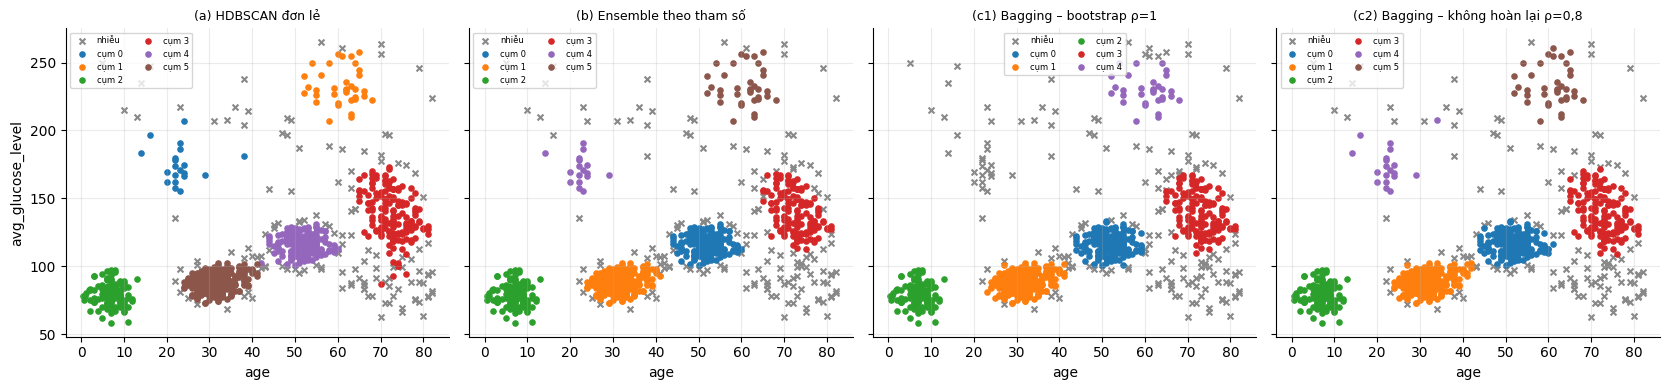

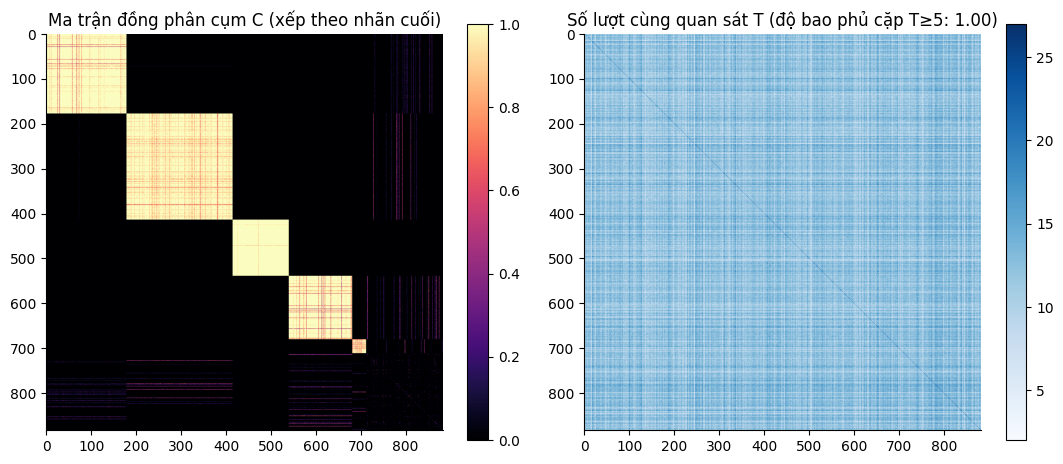

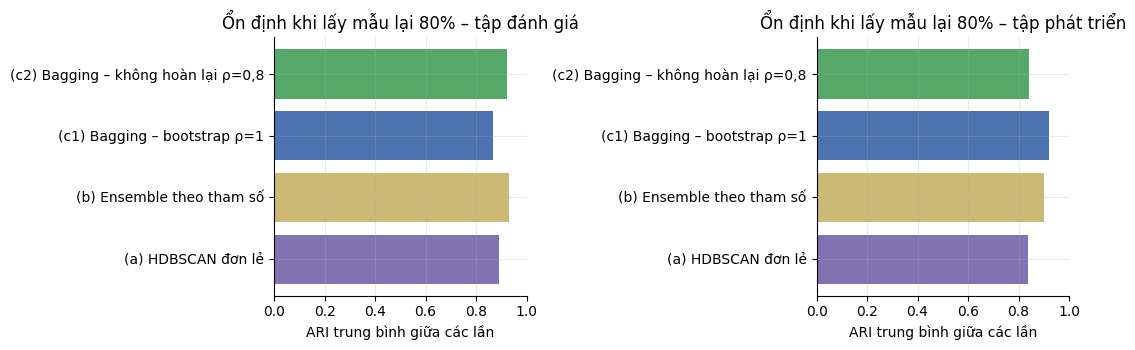

In [59]:
# Hình phân cụm trên tập đánh giá (cấu hình đã khóa)
names = list(labs_ev.keys())
fig, ax = plt.subplots(1, len(names), figsize=(4.2 * len(names), 4), sharex=True, sharey=True)
for a, nm_ in zip(np.atleast_1d(ax), names):
    lab = labs_ev[nm_]
    for c in np.unique(lab):
        m = lab == c
        a.scatter(EVAL.loc[m, "age"], EVAL.loc[m, "avg_glucose_level"], s=14 if c != -1 else 18, marker="x" if c == -1 else "o", color="#888" if c == -1 else None, label="nhiễu" if c == -1 else f"cụm {c}")
    a.set_title(nm_, fontsize=9); a.set_xlabel("age"); a.legend(fontsize=6, ncol=2)
np.atleast_1d(ax)[0].set_ylabel("avg_glucose_level"); plt.tight_layout()

# Heatmap đồng phân cụm kèm độ bao phủ (Bagging bootstrap, tập đánh giá)
sname0 = next(iter(BAG_LOCK)); sp0 = SAMPLINGS[sname0]
bagF = BaggedHDBSCANScratch(MCS_LOCK, MS_LOCK, B=B_MAIN, seed=0, c_min=MCS_LOCK, **BAG_LOCK[sname0], **sp0).fit(X_ev)
order = np.lexsort((np.arange(len(X_ev)), np.where(bagF.labels_ < 0, 10**6, bagF.labels_)))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
im = ax[0].imshow(np.nan_to_num(bagF.C_[np.ix_(order, order)], nan=0), cmap="magma", vmin=0, vmax=1); ax[0].set_title("Ma trận đồng phân cụm C (xếp theo nhãn cuối)"); ax[0].grid(False); plt.colorbar(im, ax=ax[0])
im = ax[1].imshow(bagF.T_[np.ix_(order, order)], cmap="Blues"); ax[1].set_title(f"Số lượt cùng quan sát T (độ bao phủ cặp T≥{BAG_LOCK[sname0]['t_min']}: {bagF.builder_.pair_coverage(BAG_LOCK[sname0]['t_min']):.2f})"); ax[1].grid(False); plt.colorbar(im, ax=ax[1])
plt.tight_layout()

# Biểu đồ ổn định
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, tap in zip(ax, ["đánh giá", "phát triển"]):
    g = stab[stab.tap == tap]; a.barh(g.method, g.ARI_giua_cac_lan, color=["#8172B2", "#CCB974", "#4C72B0", "#55A868"][:len(g)]); a.set_xlim(0, 1); a.set_title(f"Ổn định khi lấy mẫu lại 80% – tập {tap}"); a.set_xlabel("ARI trung bình giữa các lần")
plt.tight_layout()

# Hồ sơ nhãn tham khảo (stroke) trong từng cụm: chỉ để mô tả, không dùng để chọn cấu hình
prof = []
for nm_, lab in labs_ev.items():
    p = EV.reference_profile(lab, y_ev); p.insert(0, "phuong_phap", nm_); prof.append(p)
prof = pd.concat(prof); prof["ref_rate"] = prof.ref_rate.round(3)
print(f"Tỷ lệ stroke=1 trong từng cụm (tập đánh giá; tỷ lệ chung {y_ev.mean():.3f}; cụm −1 = nhiễu):"); display(prof)

# Đối chiếu nhóm sinh dữ liệu SAU KHI KHÓA cấu hình: không dùng sheet này khi fit hoặc chọn tham số.
design = pd.read_excel(XLSX, sheet_name="Thiet_ke_cum")
if design["id"].isna().any() or not design["id"].is_unique:
    raise ValueError("Sheet Thiet_ke_cum phải có id đầy đủ, duy nhất.")
if set(design["id"]) != set(raw["id"]) or design["profile_thiet_ke"].isna().any():
    raise ValueError("Sheet nhóm thiết kế không khớp id hoặc thiếu nhãn nhóm.")

def design_labels(frame):
    matched = frame[["id"]].merge(design, on="id", how="left", sort=False, validate="one_to_one")
    assert np.array_equal(matched["id"].to_numpy(), frame["id"].to_numpy())
    return matched["profile_thiet_ke"].to_numpy()

design_counts = pd.DataFrame({
    name: pd.Series(design_labels(frame)).value_counts()
    for name, frame in [("nguồn", raw), ("thực nghiệm", DATA), ("phát triển", DEV), ("đánh giá", EVAL)]
}).fillna(0).astype(int).sort_index()
print("Số quan sát từng nhóm thiết kế sau lấy mẫu và tiền xử lý (chỉ kiểm tra sau chạy):")
display(design_counts)

ref_design_ev = design_labels(EVAL)
mask_core_design = np.isin(ref_design_ev, [f"C{i}" for i in range(8)])
rows = []
for name, labels in labs_ev.items():
    ari_design = (EV.ari_manual(ref_design_ev[mask_core_design], labels[mask_core_design])
                  if mask_core_design.sum() >= 2 else np.nan)
    nz = ref_design_ev == "NZ"
    rows.append(dict(method=name, ARI_nhom_thiet_ke_C0_C7=ari_design,
                     so_diem_NZ=int(nz.sum()),
                     ty_le_NZ_bi_gan_nhieu=float(np.mean(labels[nz] == NOISE)) if nz.any() else np.nan))
    print(f"Bảng chéo nhóm thiết kế / cụm dự đoán: {name} (−1 là nhiễu)")
    display(pd.crosstab(pd.Series(ref_design_ev, name="nhóm thiết kế"),
                        pd.Series(labels, name="cụm dự đoán")))
design_eval = pd.DataFrame(rows)
print("ARI trên các điểm C0–C7: giữ nhãn dự đoán −1 như một nhãn; loại BR và NZ khỏi phép tính ARI này.")
print("Tỷ lệ NZ bị gán nhiễu là recall trên NZ, không phải độ chính xác tổng thể của phát hiện nhiễu.")
print("Nhóm sinh có thể chồng lấn ở hai biến đầu vào; nhãn thiết kế không phải nhãn lâm sàng.")
display(design_eval.round(3))


### 6.10b. Khảo sát bổ sung: thêm biến `bmi` làm biến phân cụm thứ ba
Cấu hình HDBSCAN và Bagging **đã khóa** ở 6.5 (chọn trên không gian hai biến) được chạy lại trên không gian ba biến `age`, `avg_glucose_level`, `bmi`, **không chọn lại tham số**.
`bmi` thiếu được điền bằng median tính trên chính tập đang phân cụm. Đây là phép khảo sát độ nhạy theo không gian đặc trưng; ARI với nhóm thiết kế chỉ là kiểm tra sau chạy.

In [60]:
def zscore_3(frame):
    A = frame[["age", "avg_glucose_level", "bmi"]].to_numpy(float).copy()
    miss = np.isnan(A[:, 2]); A[miss, 2] = np.nanmedian(A[:, 2])
    return Preprocessor.zscore(A), int(miss.sum())
X3_dev, m3_dev = zscore_3(DEV); X3_ev, m3_ev = zscore_3(EVAL)
print(f"bmi thiếu được điền median: phát triển {m3_dev}, đánh giá {m3_ev}.")
rows = []
for tap, frame, X2, X3 in [("đánh giá", EVAL, X_ev, X3_ev), ("phát triển", DEV, X_dev, X3_dev)]:
    ref_d = design_labels(frame); core_mask = np.isin(ref_d, [f"C{i}" for i in range(8)])
    methods = {"(a) HDBSCAN đơn lẻ": lambda X: HDBSCANScratch(MCS_LOCK, MS_LOCK).fit_predict(X)}
    for i, (sname, sp) in enumerate(SAMPLINGS.items()):
        if sname in BAG_LOCK:
            methods[f"(c{i+1}) Bagging – {sname}"] = (lambda sname=sname, sp=sp: lambda X: BaggedHDBSCANScratch(
                MCS_LOCK, MS_LOCK, B=B_MAIN, seed=0, c_min=MCS_LOCK, **BAG_LOCK[sname], **sp).fit_predict(X))()
    for mname, fn in methods.items():
        for space, X in [("2 biến", X2), ("3 biến (+bmi)", X3)]:
            lab = fn(X); rep_ = EV.report(X, lab)
            rows.append(dict(tap=tap, phuong_phap=mname, khong_gian=space, n_clusters=rep_["n_clusters"], noise_ratio=rep_["noise_ratio"],
                             dbcv_penalize=rep_["dbcv_penalize"], sil_drop=rep_["sil_drop"],
                             ARI_nhom_thiet_ke_C0_C7=EV.ari_manual(ref_d[core_mask], lab[core_mask])))
bmi_tab = pd.DataFrame(rows)
display(bmi_tab.round(3))

bmi thiếu được điền median: phát triển 88, đánh giá 52.


,tap,phuong_phap,khong_gian,n_clusters,noise_ratio,dbcv_penalize,sil_drop,ARI_nhom_thiet_ke_C0_C7
0,đánh giá,(a) HDBSCAN đơn lẻ,2 biến,6,0.154,0.547,0.677,0.825
1,đánh giá,(a) HDBSCAN đơn lẻ,3 biến (+bmi),7,0.200,0.500,0.651,0.813
2,đánh giá,(c1) Bagging – bootstrap ρ=1,2 biến,5,0.194,0.554,0.691,0.821
3,đánh giá,(c1) Bagging – bootstrap ρ=1,3 biến (+bmi),5,0.234,0.385,0.661,0.798
4,đánh giá,"(c2) Bagging – không hoàn lại ρ=0,8",2 biến,6,0.152,0.568,0.683,0.851
5,đánh giá,"(c2) Bagging – không hoàn lại ρ=0,8",3 biến (+bmi),7,0.182,0.426,0.646,0.841
6,phát triển,(a) HDBSCAN đơn lẻ,2 biến,7,0.160,0.597,0.670,0.804
7,phát triển,(a) HDBSCAN đơn lẻ,3 biến (+bmi),8,0.179,0.416,0.646,0.833
8,phát triển,(c1) Bagging – bootstrap ρ=1,2 biến,7,0.174,0.597,0.684,0.812
9,phát triển,(c1) Bagging – bootstrap ρ=1,3 biến (+bmi),7,0.188,0.388,0.652,0.835


### 6.10c. Khảo sát bổ sung: Bagging so với HDBSCAN đơn lẻ khi thay đổi cấu hình cơ sở
Cấu hình cơ sở đã khóa ở 6.5 được chọn bằng DBCV nên thường đã ổn định. Để thấy Bagging có ích trong điều kiện nào, ô dưới chạy lại trên **tập đánh giá** với một số cấu hình cơ sở khác
(gồm cấu hình `min_samples` nhỏ, dễ chia vụn thành nhiều cụm), giữ nguyên B, θ, T_min và kiểu lấy mẫu đã khóa. Đây là khảo sát độ nhạy, **không chọn lại tham số**;
ARI với nhóm thiết kế C0–C7 là kiểm tra sau chạy. Lưu ý θ và T_min được khóa theo cấu hình cơ sở ban đầu, nên với cấu hình khác chúng có thể chưa tối ưu.

In [61]:
ref_ev = design_labels(EVAL); core_ev = np.isin(ref_ev, [f"C{i}" for i in range(8)])
base_cfgs = []
for cfg in [(10, 3), (10, 5), (20, 10), (MCS_LOCK, MS_LOCK)]:
    if cfg not in base_cfgs: base_cfgs.append(cfg)
rows_c = []
for mcs_, ms_ in base_cfgs:
    entries = {"(a) HDBSCAN đơn lẻ": HDBSCANScratch(mcs_, ms_).fit_predict(X_ev)}
    for i_, (sname_, sp_) in enumerate(SAMPLINGS.items()):
        if sname_ in BAG_LOCK:
            entries[f"(c{i_+1}) Bagging – {sname_}"] = BaggedHDBSCANScratch(
                mcs_, ms_, B=B_MAIN, seed=0, c_min=mcs_, **BAG_LOCK[sname_], **sp_).fit_predict(X_ev)
    for name_, lab_ in entries.items():
        r_ = EV.report(X_ev, lab_)
        rows_c.append(dict(min_cluster_size=mcs_, min_samples=ms_, phuong_phap=name_, n_clusters=r_["n_clusters"], noise_ratio=r_["noise_ratio"],
                           dbcv_penalize=r_["dbcv_penalize"], ARI_nhom_thiet_ke_C0_C7=EV.ari_manual(ref_ev[core_ev], lab_[core_ev])))
base_cfg_tab = pd.DataFrame(rows_c)
display(base_cfg_tab.round(3))
print("Cách đọc: so sánh từng nhóm dòng cùng (min_cluster_size, min_samples); chỉ kết luận cho cấu hình và dữ liệu này.")

,min_cluster_size,min_samples,phuong_phap,n_clusters,noise_ratio,dbcv_penalize,ARI_nhom_thiet_ke_C0_C7
0,10,3,(a) HDBSCAN đơn lẻ,7,0.062,0.463,0.882
1,10,3,(c1) Bagging – bootstrap ρ=1,6,0.097,0.544,0.860
2,10,3,"(c2) Bagging – không hoàn lại ρ=0,8",7,0.063,0.527,0.905
3,10,5,(a) HDBSCAN đơn lẻ,8,0.121,0.371,0.793
4,10,5,(c1) Bagging – bootstrap ρ=1,7,0.104,0.482,0.878
5,10,5,"(c2) Bagging – không hoàn lại ρ=0,8",6,0.085,0.522,0.846
6,20,10,(a) HDBSCAN đơn lẻ,5,0.142,0.515,0.838
7,20,10,(c1) Bagging – bootstrap ρ=1,5,0.166,0.544,0.837
8,20,10,"(c2) Bagging – không hoàn lại ρ=0,8",5,0.120,0.495,0.846
9,3,15,(a) HDBSCAN đơn lẻ,6,0.154,0.547,0.825


Cách đọc: so sánh từng nhóm dòng cùng (min_cluster_size, min_samples); chỉ kết luận cho cấu hình và dữ liệu này.


Số điểm tối đa sau loại trùng: 2945 | Các cỡ mẫu benchmark: [100, 200, 400, 800, 1200, 1800]


,n,scratch_s,scratch_MB,lib_s,lib_MB
0,100,0.016,0.401,0.017,0.234
1,200,0.051,1.601,0.034,0.712
2,400,0.120,6.402,0.099,2.632
3,800,0.252,25.602,0.229,10.312
4,1200,0.454,57.602,0.399,23.106
5,1800,0.779,129.602,0.513,51.906


,B,time_s,mem_MB
0,5,1.856,144.803
1,10,5.034,154.013
2,20,10.184,174.187
3,40,16.929,177.902
4,80,34.564,180.226


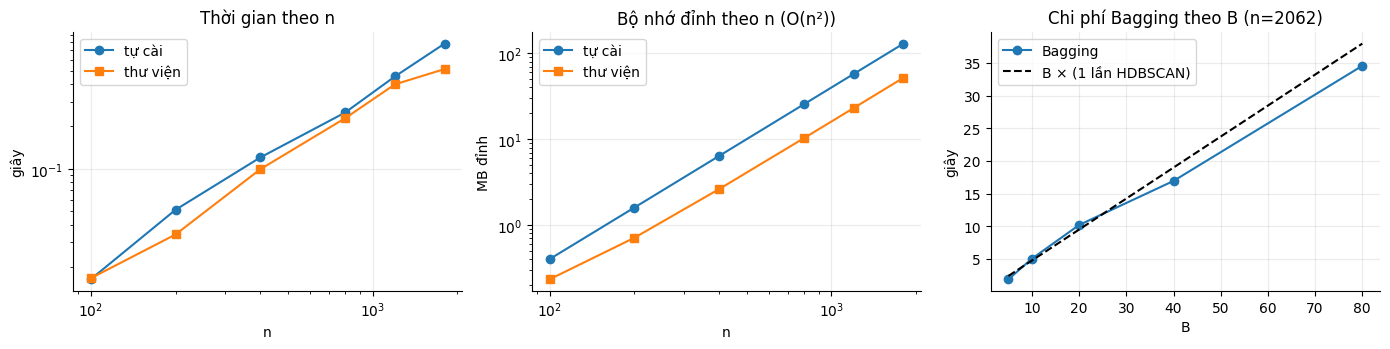

In [62]:
# Chi phí theo n trên dữ liệu tổng hợp đầy đủ (loại trùng hai biến), và chi phí Bagging theo B
full = raw[FEAT].drop_duplicates().to_numpy(float); rs = np.random.default_rng(3)
rows = []
SCALE_NS = sorted({min(n, len(full)) for n in [100, 200, 400, 800, 1200, 1800]})
print("Số điểm tối đa sau loại trùng:", len(full), "| Các cỡ mẫu benchmark:", SCALE_NS)
for n_ in SCALE_NS:
    Xn = Preprocessor.zscore(full[rs.choice(len(full), n_, replace=False)])
    ts, tl = bench(lambda: HDBSCANScratch(MCS_LOCK, MS_LOCK), Xn, reps=2), bench(lambda: HDBSCANLibraryAdapter(MCS_LOCK, MS_LOCK), Xn, reps=2)
    rows.append(dict(n=n_, scratch_s=ts[0], scratch_MB=ts[1], lib_s=tl[0], lib_MB=tl[1]))
scale = pd.DataFrame(rows); display(scale.round(3))
rows = []
for B in [5, 10, 20, 40, 80]:
    Xb = X_dev; _, dt, mem = EV.measure(lambda: BaggedHDBSCANScratch(MCS_LOCK, MS_LOCK, B=B, seed=0, c_min=MCS_LOCK, **BASE).fit_predict(Xb))
    rows.append(dict(B=B, time_s=dt, mem_MB=mem))
bag_cost = pd.DataFrame(rows); display(bag_cost.round(3))
t1 = bench(lambda: HDBSCANScratch(MCS_LOCK, MS_LOCK), X_dev, reps=3)[0]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].loglog(scale.n, scale.scratch_s, "o-", label="tự cài"); ax[0].loglog(scale.n, scale.lib_s, "s-", label="thư viện"); ax[0].set_xlabel("n"); ax[0].set_ylabel("giây"); ax[0].legend(); ax[0].set_title("Thời gian theo n")
ax[1].loglog(scale.n, scale.scratch_MB, "o-", label="tự cài"); ax[1].loglog(scale.n, scale.lib_MB, "s-", label="thư viện"); ax[1].set_xlabel("n"); ax[1].set_ylabel("MB đỉnh"); ax[1].legend(); ax[1].set_title("Bộ nhớ đỉnh theo n (O(n²))")
ax[2].plot(bag_cost.B, bag_cost.time_s, "o-", label="Bagging"); ax[2].plot(bag_cost.B, bag_cost.B * t1, "k--", label="B × (1 lần HDBSCAN)"); ax[2].set_xlabel("B"); ax[2].set_ylabel("giây"); ax[2].legend(); ax[2].set_title("Chi phí Bagging theo B (n=%d)" % len(X_dev))
plt.tight_layout()


### 6.11. Phân tích kết quả và hạn chế
Ô dưới đây tổng hợp trực tiếp các bảng vừa chạy trên dữ liệu mới.
Không dùng lại số cụm, tỷ lệ nhiễu, cấu hình tốt nhất hoặc kết luận ưu thế của lần chạy dataset cũ.

* Đọc chất lượng cụm bằng DBCV, Silhouette, số cụm và tỷ lệ nhiễu cùng nhau.
* Đọc ổn định bằng ARI trên các điểm chung giữa các lần lấy mẫu; đây là phép đo khác ARI với nhóm sinh dữ liệu.
* `stroke` chỉ mô tả phân bố nhãn mô phỏng. Không diễn giải thành bằng chứng nguy cơ bệnh.
* ARI với C0–C7 và tỷ lệ nhận ra NZ là kiểm tra sau chạy; không đổi tham số theo các chỉ số này.
* Thực nghiệm chính dùng toàn bộ dữ liệu sau loại trùng; kiểm tra bảng số nhóm sau khi chia tập để thấy còn bao nhiêu điểm của các nhóm nhỏ C4, C6 và điểm cầu BR ở mỗi tập.
* Báo cáo độ ổn định ở **cả tập phát triển và tập đánh giá**; nếu chiều chênh lệch khác nhau giữa hai tập thì không kết luận một chiều.
* Các kết quả chỉ phản ánh một thiết kế dữ liệu, hai biến và seed đã công bố. So sánh chênh lệch chưa phải kiểm định thống kê.


In [63]:
print("DỮ LIỆU VÀ CẤU HÌNH CỦA LẦN CHẠY HIỆN TẠI")
print(f"Nguồn tổng hợp: {len(raw)} dòng; loại trùng hai biến: {n_dup}; dùng cho thực nghiệm: {N_USED}; phát triển/đánh giá: {len(DEV)}/{len(EVAL)}.")
print(f"BMI thiếu giữ trong DATA: {DATA.bmi.isna().sum()}; stroke=1 ở DATA: {DATA.stroke.mean():.2%}.")
print(f"Cấu hình HDBSCAN đã khóa trên phát triển: MCS={MCS_LOCK}, MS_tự_cài={MS_LOCK} (tính chính điểm).")
print("Cấu hình Bagging đã khóa:", BAG_LOCK)

print("\nĐỐI CHIẾU GÓI HDBSCAN")
print(f"Đầu–cuối khớp ARI=1: {np.isclose(cmp_grid.ari_dau_cuoi, 1).sum()}/{len(cmp_grid)} cấu hình; ARI nhỏ nhất: {cmp_grid.ari_dau_cuoi.min():.4f}.")
print(f"Cùng cây thư viện khớp ARI=1: {np.isclose(cmp_grid.ari_cung_cay_SL, 1).sum()}/{len(cmp_grid)} cấu hình.")
print(f"T bằng nhau qua hai engine ở {int(verify_bag.T_tu_cai_bang_thu_vien.sum())}/{len(verify_bag)} phép so Bagging.")
print(f"S/T khớp đếm độc lập: {int(verify_bag.S_T_bang_vong_lap_thuan.sum())}/{len(verify_bag)}; nhãn tổng hợp khớp SciPy: {int(verify_bag.nhan_threshold_bang_scipy.sum())}/{len(verify_bag)}.")

base_name = "(a) HDBSCAN đơn lẻ"
base_ev = res_ev.set_index("method").loc[base_name]
stab_ev = stab[stab.tap == "đánh giá"].set_index("method")
base_stability = stab_ev.loc[base_name, "ARI_giua_cac_lan"]
comparison = res_ev[["method", "n_clusters", "noise_ratio", "dbcv_penalize", "sil_drop", "time_s"]].copy()
comparison["chenh_DBCV_so_voi_don_le"] = comparison.dbcv_penalize - base_ev.dbcv_penalize
comparison["ARI_on_dinh_80pct"] = comparison.method.map(stab_ev.ARI_giua_cac_lan)
comparison["chenh_on_dinh_so_voi_don_le"] = comparison.ARI_on_dinh_80pct - base_stability
print("\nTẬP ĐÁNH GIÁ: chất lượng và ổn định (chênh dương nghĩa là cao hơn đơn lẻ)")
display(comparison.round(3))
bag_rows = comparison[comparison.method.str.startswith("(c")]
for _, row in bag_rows.iterrows():
    print(f"{row.method}: chênh DBCV={row.chenh_DBCV_so_voi_don_le:+.3f}; chênh ARI ổn định={row.chenh_on_dinh_so_voi_don_le:+.3f}; cụm={int(row.n_clusters)}; nhiễu={row.noise_ratio:.1%}.")
print("Chỉ kết luận cho từng chỉ số và cấu hình đã khóa; không mặc định Bagging phải tốt hơn HDBSCAN đơn lẻ.")

# Độ ổn định ở TẬP PHÁT TRIỂN (để đối chiếu chiều chênh lệch với tập đánh giá)
stab_dev = stab[stab.tap == "phát triển"].set_index("method")
comp_dev = res_dev[["method", "n_clusters", "noise_ratio", "dbcv_penalize"]].copy()
comp_dev["chenh_DBCV_so_voi_don_le"] = comp_dev.dbcv_penalize - res_dev.set_index("method").loc[base_name, "dbcv_penalize"]
comp_dev["ARI_on_dinh_80pct"] = comp_dev.method.map(stab_dev.ARI_giua_cac_lan)
comp_dev["chenh_on_dinh_so_voi_don_le"] = comp_dev.ARI_on_dinh_80pct - stab_dev.loc[base_name, "ARI_giua_cac_lan"]
print("\nTẬP PHÁT TRIỂN: chất lượng và ổn định (tham khảo; chiều chênh lệch có thể khác tập đánh giá)")
display(comp_dev.round(3))

print("\nKIỂM TRA NHÓM THIẾT KẾ SAU CHẠY")
display(design_eval.round(3))
for _g in ("C4", "C6"):
    print(f"Nhóm nhỏ {_g} còn lại ở nguồn / thực nghiệm / phát triển / đánh giá:", design_counts.loc[_g].to_dict())
print("Nhãn stroke được sinh mô phỏng, các tỷ lệ trong cụm chỉ có ý nghĩa mô tả dữ liệu này.")

print("\nTÀI NGUYÊN VÀ GIỚI HẠN")
print(f"Benchmark HDBSCAN dùng n từ {int(scale.n.min())} đến {int(scale.n.max())}; không lấy vượt số dòng có sẵn.")
print(f"Bagging ở B={int(bag_cost.B.iloc[0])}: {bag_cost.time_s.iloc[0]:.3f}s; B={int(bag_cost.B.iloc[-1])}: {bag_cost.time_s.iloc[-1]:.3f}s (máy chạy hiện tại).")
print(f"Thực nghiệm chính dùng toàn bộ n = {N_USED} dòng sau loại trùng, hai biến phân cụm; các nhóm thiết kế có thể chồng lấn; các ma trận dày dùng bộ nhớ O(n²).")


DỮ LIỆU VÀ CẤU HÌNH CỦA LẦN CHẠY HIỆN TẠI
Nguồn tổng hợp: 2985 dòng; loại trùng hai biến: 40; dùng cho thực nghiệm: 2945; phát triển/đánh giá: 2062/883.
BMI thiếu giữ trong DATA: 140; stroke=1 ở DATA: 4.65%.
Cấu hình HDBSCAN đã khóa trên phát triển: MCS=3, MS_tự_cài=15 (tính chính điểm).
Cấu hình Bagging đã khóa: {'bootstrap ρ=1': {'adjust': False, 'theta': 0.8, 't_min': 5}, 'không hoàn lại ρ=0,8': {'adjust': True, 'theta': 0.6, 't_min': 5}}

ĐỐI CHIẾU GÓI HDBSCAN
Đầu–cuối khớp ARI=1: 3/30 cấu hình; ARI nhỏ nhất: 0.9561.
Cùng cây thư viện khớp ARI=1: 30/30 cấu hình.
T bằng nhau qua hai engine ở 4/4 phép so Bagging.
S/T khớp đếm độc lập: 4/4; nhãn tổng hợp khớp SciPy: 4/4.

TẬP ĐÁNH GIÁ: chất lượng và ổn định (chênh dương nghĩa là cao hơn đơn lẻ)


,method,n_clusters,noise_ratio,dbcv_penalize,sil_drop,time_s,chenh_DBCV_so_voi_don_le,ARI_on_dinh_80pct,chenh_on_dinh_so_voi_don_le
0,(a) HDBSCAN đơn lẻ,6,0.154,0.547,0.677,0.219,0.000,0.892,0.000
1,(b) Ensemble theo tham số,6,0.182,0.566,0.698,3.186,0.019,0.930,0.037
2,(c1) Bagging – bootstrap ρ=1,5,0.194,0.554,0.691,5.013,0.007,0.869,-0.024
3,"(c2) Bagging – không hoàn lại ρ=0,8",6,0.152,0.568,0.683,6.302,0.021,0.922,0.030


(c1) Bagging – bootstrap ρ=1: chênh DBCV=+0.007; chênh ARI ổn định=-0.024; cụm=5; nhiễu=19.4%.
(c2) Bagging – không hoàn lại ρ=0,8: chênh DBCV=+0.021; chênh ARI ổn định=+0.030; cụm=6; nhiễu=15.2%.
Chỉ kết luận cho từng chỉ số và cấu hình đã khóa; không mặc định Bagging phải tốt hơn HDBSCAN đơn lẻ.

TẬP PHÁT TRIỂN: chất lượng và ổn định (tham khảo; chiều chênh lệch có thể khác tập đánh giá)


,method,n_clusters,noise_ratio,dbcv_penalize,chenh_DBCV_so_voi_don_le,ARI_on_dinh_80pct,chenh_on_dinh_so_voi_don_le
0,(a) HDBSCAN đơn lẻ,7,0.160,0.597,0.000,0.839,0.000
1,(b) Ensemble theo tham số,7,0.162,0.593,-0.004,0.901,0.062
2,(c1) Bagging – bootstrap ρ=1,7,0.174,0.597,-0.000,0.919,0.081
3,"(c2) Bagging – không hoàn lại ρ=0,8",7,0.191,0.604,0.007,0.842,0.003



KIỂM TRA NHÓM THIẾT KẾ SAU CHẠY


,method,ARI_nhom_thiet_ke_C0_C7,so_diem_NZ,ty_le_NZ_bi_gan_nhieu
0,(a) HDBSCAN đơn lẻ,0.825,46,0.674
1,(b) Ensemble theo tham số,0.817,46,0.739
2,(c1) Bagging – bootstrap ρ=1,0.821,46,0.826
3,"(c2) Bagging – không hoàn lại ρ=0,8",0.851,46,0.674


Nhóm nhỏ C4 còn lại ở nguồn / thực nghiệm / phát triển / đánh giá: {'nguồn': 105, 'thực nghiệm': 105, 'phát triển': 74, 'đánh giá': 31}
Nhóm nhỏ C6 còn lại ở nguồn / thực nghiệm / phát triển / đánh giá: {'nguồn': 45, 'thực nghiệm': 45, 'phát triển': 32, 'đánh giá': 13}
Nhãn stroke được sinh mô phỏng, các tỷ lệ trong cụm chỉ có ý nghĩa mô tả dữ liệu này.

TÀI NGUYÊN VÀ GIỚI HẠN
Benchmark HDBSCAN dùng n từ 100 đến 1800; không lấy vượt số dòng có sẵn.
Bagging ở B=5: 1.856s; B=80: 34.564s (máy chạy hiện tại).
Thực nghiệm chính dùng toàn bộ n = 2945 dòng sau loại trùng, hai biến phân cụm; các nhóm thiết kế có thể chồng lấn; các ma trận dày dùng bộ nhớ O(n²).


## Chương 7. Kết luận và hướng phát triển
### 7.1. Kết quả đạt được
* **Lý thuyết và cài đặt:** giữ nguyên các lớp hướng đối tượng HDBSCAN và Bagging, Prim,
  cây cô đọng, stability, EOM, ma trận S/T/C và các cách tổng hợp đã có.
* **Minh họa và kiểm chứng:** giữ các bộ D1, ví dụ cây tính tay, kiểm tra ma trận và kịch bản S1–S3.
  D1 độc lập với dataset mới; chọn đúng nguồn D1 khi đối chiếu số tính tay.
* **Đối chiếu thư viện:** vẫn dùng gói `hdbscan`, giữ quy đổi cách đếm `min_samples`.
  Số cấu hình khớp và sai khác thực tế nằm ở 6.6–6.7 và phần tổng hợp 6.11.
* **Dữ liệu mới:** đọc đúng workbook tổng hợp, giữ dòng thiếu BMI khi BMI không tham gia mô hình,
  dùng toàn bộ dữ liệu sau loại trùng (không lấy mẫu con) và kiểm tra nhóm thiết kế sau khi khóa cấu hình.

### 7.2. Kết luận từ thực nghiệm
Kết luận định lượng lấy từ bảng **tập đánh giá** và bảng chênh lệch ở 6.11.
Chỉ số chất lượng cụm và độ ổn định phải được nhận xét riêng: một phương pháp có thể tăng chỉ số này nhưng giảm chỉ số khác.
Không chọn lại cấu hình theo kết quả đánh giá hoặc nhóm thiết kế.
Kết quả trên dữ liệu tổng hợp chỉ cho thấy hành vi thuật toán trong thiết kế này;
không suy ra hiệu quả trên dữ liệu bệnh nhân thật hoặc khẳng định Bagging luôn tốt hơn.

### 7.3. Hạn chế của đồ án
* Một dataset tổng hợp (kết quả chỉ phản ánh thiết kế sinh dữ liệu, không suy ra dữ liệu thật), n khoảng 1.800 sau loại trùng, chủ yếu dùng hai biến phân cụm.
  Nhóm thiết kế có thể chồng lấn; các nhóm nhỏ C4 và C6 chỉ còn vài chục điểm sau khi chia tập phát triển/đánh giá.
* Giữ chính sách loại trùng trên hai biến: mật độ có thể thay đổi, kể cả khi các cột khác của hai dòng khác nhau.
* Mỗi tập được chuẩn hóa và phân cụm độc lập; đây không phải đánh giá dự đoán ngoài mẫu của một mô hình fit duy nhất.
* Các ma trận dày tốn bộ nhớ O(n²); Bagging phải chạy HDBSCAN nhiều lần và thêm bước tổng hợp.
* Khi loại các chỉ số được rút lặp trong từng mẫu bootstrap, base learner học trên tập chỉ số duy nhất
  có kích thước ngẫu nhiên. Vì vậy không trực tiếp áp dụng bảo đảm lý thuyết của Bagging phân loại cho quy trình phân cụm này.
* Đồ thị ngưỡng có thể nối chuỗi. Độ nhạy và các phương án tổng hợp được đo ở 6.9;
  các đặc tính chưa hỗ trợ của bản tự cài giữ nguyên phạm vi đã nêu.

### 7.4. Hướng phát triển
* Tăng cỡ dữ liệu (vài nghìn điểm) với ma trận thưa hoặc chỉ lưu S, T cho các cặp có T ≥ T_min; thêm nhiều seed chia tập để đo độ dao động.
* Mở rộng biến đầu vào; khi dùng BMI phải bổ sung xử lý thiếu, khi dùng biến phân loại phải bổ sung mã hóa phù hợp.
* Kiểm tra thêm nhiều thiết kế cụm và dữ liệu thực; giữ riêng nhóm thiết kế khỏi chọn tham số.
* Tối ưu MST, lưu ma trận thưa và khảo sát các cách tổng hợp nhằm giảm nối chuỗi.


## Phụ lục A. Mã sinh dữ liệu tổng hợp
Ô dưới chứa mã sinh dữ liệu (seed và kích thước các nhóm công khai) và so sánh kết quả với file Excel đang dùng. Mã chỉ **đọc và so sánh**, không ghi đè file dữ liệu.
Nếu phiên bản `numpy` khác, dãy số ngẫu nhiên có thể khác và kết quả so sánh sẽ báo "khác"; khi đó hãy dùng đúng file Excel kèm theo.

In [64]:
import numpy as np, pandas as pd

GEN_SEED = 2027
# Kích thước từng nhóm thiết kế (trước khi thêm dòng trùng)
GEN_SIZES = {"C0": 420, "C1": 800, "C2": 620, "C3": 380, "C4": 105, "C5": 210, "C6": 45, "C7": 170, "BR": 75, "NZ": 140}
GEN_N_DUP = 20

def generate_synthetic(seed=GEN_SEED, sizes=GEN_SIZES, n_dup=GEN_N_DUP):
    rng = np.random.default_rng(seed)
    rows = []
    N = lambda m, s: (lambda n: rng.normal(m, s, n))
    U = lambda lo, hi: (lambda n: rng.uniform(lo, hi, n))
    def add(profile, age, glu, bmi, p_hyp, p_heart, p_married, work_p, smoke_p):
        n = sizes[profile]
        a, g, b = age(n), glu(n), bmi(n)
        wk = np.array(list(work_p.values()), float); wk /= wk.sum()
        sm = np.array(list(smoke_p.values()), float); sm /= sm.sum()
        for i in range(n):
            rows.append(dict(profile=profile, age=a[i], avg_glucose_level=g[i], bmi=b[i],
                             hypertension=int(rng.random() < p_hyp), heart_disease=int(rng.random() < p_heart),
                             ever_married="Yes" if rng.random() < p_married else "No",
                             work_type=rng.choice(list(work_p), p=wk), smoking_status=rng.choice(list(smoke_p), p=sm)))
    ADULT = {"Private": .6, "Self-employed": .2, "Govt_job": .19, "Never_worked": .01, "children": 0}
    # C0: trẻ em/thiếu niên – cụm DÀY, gọn
    add("C0", lambda n: np.clip(rng.normal(7, 2.3, n), .5, 13), N(80, 7), N(16.5, 1.8), 0, 0, 0.0,
        {"children": .97, "Never_worked": .03, "Private": 0, "Self-employed": 0, "Govt_job": 0},
        {"never smoked": .7, "Unknown": .3, "formerly smoked": 0, "smokes": 0})
    # C1: người lớn trẻ – cụm LỚN, mật độ vừa
    add("C1", N(31, 3.6), N(88, 7), N(25, 2.2), .02, .005, .35,
        {"Private": .68, "Self-employed": .14, "Govt_job": .17, "Never_worked": .01, "children": 0},
        {"never smoked": .5, "Unknown": .2, "formerly smoked": .1, "smokes": .2})
    # C2: trung niên thừa cân – mật độ vừa
    add("C2", N(52, 3.8), N(116, 9), N(35.5, 2.4), .22, .04, .88, ADULT,
        {"never smoked": .4, "Unknown": .1, "formerly smoked": .25, "smokes": .25})
    # C3: cao tuổi, tim mạch – mật độ thấp hơn
    add("C3", N(74, 3.2), N(130, 12), N(29, 2.2), .55, .45, .92,
        {"Private": .4, "Self-employed": .3, "Govt_job": .3, "Never_worked": 0, "children": 0},
        {"never smoked": .3, "Unknown": .05, "formerly smoked": .45, "smokes": .2})
    # C4: glucose rất cao – cụm NHỎ
    add("C4", N(60, 5), N(232, 12), N(31, 2.8), .4, .25, .9,
        {"Private": .4, "Self-employed": .3, "Govt_job": .3, "Never_worked": 0, "children": 0},
        {"never smoked": .4, "Unknown": .05, "formerly smoked": .35, "smokes": .2})
    # C5: cao tuổi BMI thấp – cụm THƯA, phương sai lớn
    add("C5", U(60, 82), lambda n: np.clip(rng.lognormal(np.log(90), .2, n), 60, 180), N(21, 3.2), .25, .12, .8,
        {"Private": .15, "Self-employed": .45, "Govt_job": .4, "Never_worked": 0, "children": 0},
        {"never smoked": .5, "Unknown": .1, "formerly smoked": .3, "smokes": .1})
    # C6: người trẻ glucose cao – cụm RẤT NHỎ nhưng DÀY (thử sống sót khi lấy mẫu lại)
    add("C6", N(22, 1.8), N(170, 6), N(31, 3), .1, .0, .3,
        {"Private": .6, "Self-employed": .15, "Govt_job": .2, "Never_worked": .05, "children": 0},
        {"never smoked": .5, "Unknown": .2, "formerly smoked": .1, "smokes": .2})
    # C7: cao tuổi, glucose cao hơn – CHỒNG LẤN một phần với C3 trên (age, glucose); tách rõ nhờ bmi
    add("C7", N(70, 3.6), N(160, 13), N(32.5, 2.4), .6, .3, .9,
        {"Private": .35, "Self-employed": .35, "Govt_job": .3, "Never_worked": 0, "children": 0},
        {"never smoked": .3, "Unknown": .05, "formerly smoked": .4, "smokes": .25})
    # BR: cầu nối thưa giữa C1 và C2 (nguy cơ nối chuỗi)
    add("BR", U(36, 44), U(92, 108), U(26, 32), .1, .02, .7, ADULT,
        {"never smoked": .45, "Unknown": .15, "formerly smoked": .2, "smokes": .2})
    # NZ: nhiễu / ngoại lệ thật
    add("NZ", U(5, 82), lambda n: np.where(rng.random(n) < .5, rng.uniform(55, 271, n), rng.uniform(150, 271, n)),
        lambda n: np.where(rng.random(n) < .5, rng.uniform(12, 97, n), rng.uniform(45, 97, n)), .3, .2, .5,
        {"Private": .3, "Self-employed": .2, "Govt_job": .2, "Never_worked": .1, "children": .2},
        {"never smoked": .3, "Unknown": .2, "formerly smoked": .2, "smokes": .3})

    df = pd.DataFrame(rows)
    df["age"] = df.age.round(0).where(df.age >= 2, df.age.round(2)).clip(0.08, 82)
    df["avg_glucose_level"] = df.avg_glucose_level.clip(55.12, 271.74).round(2)
    df["bmi"] = df.bmi.clip(10.3, 97.6).round(1)
    kids = df.age < 16                                   # ràng buộc nhất quán giữa các cột
    df.loc[kids, "work_type"] = "children"; df.loc[kids, "ever_married"] = "No"
    df.loc[kids, ["hypertension", "heart_disease"]] = 0
    df.loc[kids & ~df.smoking_status.isin(["never smoked", "Unknown"]), "smoking_status"] = "Unknown"
    df.loc[~kids & (df.work_type == "children"), "work_type"] = "Private"
    df["gender"] = rng.choice(["Female", "Male"], len(df), p=[.585, .415])
    df["Residence_type"] = rng.choice(["Urban", "Rural"], len(df), p=[.508, .492])
    z = -8.8 + .075 * df.age + .012 * (df.avg_glucose_level - 100) + 1.0 * df.hypertension + .9 * df.heart_disease + .02 * (df.bmi - 28)
    df["stroke"] = (rng.random(len(df)) < 1 / (1 + np.exp(-z))).astype(int)   # nhãn tham khảo: phụ thuộc rủi ro, KHÔNG trùng với cụm
    df.loc[rng.random(len(df)) < .04, "bmi"] = np.nan                         # ~4% bmi thiếu
    df.loc[df.index[rng.integers(len(df))], "gender"] = "Other"               # 1 dòng gender = Other như dữ liệu gốc
    dups = df[df.profile.isin(["C1", "C2", "C3"])].sample(n_dup, random_state=1)   # dòng trùng (khác id)
    df = pd.concat([df, dups], ignore_index=True).sample(frac=1, random_state=7).reset_index(drop=True)
    df.insert(0, "id", rng.choice(np.arange(60, 73000), len(df), replace=False))
    return df

_cols = ["id", "gender", "age", "hypertension", "heart_disease", "ever_married", "work_type", "Residence_type", "avg_glucose_level", "bmi", "smoking_status", "stroke"]
_gen = generate_synthetic()
try:
    pd.testing.assert_frame_equal(_gen[_cols].reset_index(drop=True), raw[_cols].reset_index(drop=True), check_dtype=False, atol=1e-9, rtol=0)
    print("Dữ liệu sinh lại KHỚP với file Excel đang dùng (seed =", GEN_SEED, ").")
    _d = _gen[["id", "profile"]].merge(design, on="id", how="left") if "design" in globals() else None
    if _d is not None: print("Nhóm thiết kế khớp với sheet Thiet_ke_cum:", bool((_d["profile"] == _d["profile_thiet_ke"]).all()))
except AssertionError as exc:
    print("Dữ liệu sinh lại KHÁC file Excel (có thể do phiên bản numpy/pandas khác). Chi tiết:", str(exc)[:300])
print("Số dòng sinh ra:", len(_gen), "| kích thước nhóm:", _gen["profile"].value_counts().to_dict())

Dữ liệu sinh lại KHỚP với file Excel đang dùng (seed = 2027 ).
Nhóm thiết kế khớp với sheet Thiet_ke_cum: True
Số dòng sinh ra: 2985 | kích thước nhóm: {'C1': 807, 'C2': 628, 'C0': 420, 'C3': 385, 'C5': 210, 'C7': 170, 'NZ': 140, 'C4': 105, 'BR': 75, 'C6': 45}
